# Basat: user-defined objectives and unified experiments

**Sections 1–4: archived example outputs.** Experiment summaries and figures below were rebuilt from the current saved result JSON files, without running optimization again. Each refreshed output identifies its source file and preserves recorded warnings and stopping reasons. Execution counters are cleared for those cells to distinguish this refresh from running the code. Editing an experiment configuration does not change its saved measurements until you execute it again. The distributional example uses the completed OPSD wind-power run with 5 trials and 50 evaluations.

This guide has four main sections: **1. Synthetic Functions Optimizations**,
**2. Real Data Formatting** (including **2.1 Real Life Objective Optimization**),
**3. Early Stopping**, and **4. Different Settings Examples**.

Install the updated checkout with `python -m pip install .`, or install its
supplied wheel. Installing Basat installs its runtime dependencies. Every
executable example imports only `basat` and uses Python built-ins. No other package imports are required in the cells. Section 5's SAASBO
reproduction additionally requires the optional `numpyro` installation extra.
These changes must be released before a package-index installation provides
this exact API. Open this notebook with
`python -m basat notebook docs/basat_user_guide.ipynb`.

Each experiment block runs independently: copy the entire block, including
its import and configuration definitions. Earlier blocks are not prerequisites.
This notebook is the current guide; older exported companions are historical snapshots.
Data files live in the project's external `data` directory; locate this guide
within that project, or edit the explicit data path.

The execution manifest records the Python version, platform and backend
versions reported by `basat.runtime_info()`. The exact dependency snapshot
is retained at `output/last_guide/execution_requirements.txt` and included
with the editable Overleaf source. Basat installs its runtime dependencies
automatically; these recorded versions identify the environment that
produced the figures.

`Experiment` is the single runner. Its `algorithm` argument accepts one
algorithm, a list/tuple of algorithms, or a label-to-algorithm dictionary.
A dictionary makes labels explicit when comparing several configurations of
the same method. Multiple algorithms receive independent environments and
stopping rules; each has its own budget (50 evaluations in Sections 1–4). Individual failures
are reported and the other methods continue. With the default `trials=1`,
single-algorithm exceptions remain visible to the caller. With `trials>1`,
a failed single-algorithm trial is recorded and the remaining seeds continue.

**There is no profile setting.** Omitting optional configuration fields uses
the algorithm's dataclass defaults; required scientific choices must still be
supplied. No preset chooses your objective, environment, threshold, or budget.
The expanded configurations below show algorithm hyperparameters, including
options inactive for the selected method variant. Environment observations
and support belong to the environment, not to algorithm configurations.
Example compute budgets are deliberately modest and are not convergence claims.

## Reproduction section

Section 5 contains the independent nine-method Hartmann6_300 reproduction with five seeds and method-specific paper budgets (SAASBO/ALEBO: 200; the other Song baselines: 600), plus two AG-VS comparisons with an added 600-evaluation budget. The current TuRBO result uses D=300 and numerical policy v3; all five historical incumbent trajectories match within 1.75e-09. Its displayed final mean is 2.816661574. The AG-VS additions use the corrected source and fresh checkpoints; their curves
are shown once all ten runs complete. The other six non-TuRBO methods retain
their archived measurements. Sections 1-4 retain their separate tutorial outputs, not Hartmann results.


# 1. Synthetic Functions Optimizations

Define an objective as an ordinary Python function returning one finite
scalar. Basat maximizes reward by default, so negate a loss to minimize it.
There is no predefined synthetic benchmark inside the library. You can
replace any function body below with your own calculation or simulator.

A stochastic function receives the chosen action. A contextual function also
receives a context revealed before selection. A distributional function
receives the context sampled after action selection; the learner sees a
reference distribution beforehand. An adversarial function receives the
evaluated coordinate after the environment has applied its attack.

These four definitions are repeated in the independent experiments below.
Only the distributional function includes an added sinusoidal component.
Observation noise is configured separately in each environment.

In [1]:
import basat

def stochastic_objective(values):
    target = (0.2, 0.65, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def contextual_objective(values, context):
    c = float(context[0])
    target = (0.2 + 0.5 * c, 0.75 - 0.4 * c, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def reveal_context(*, round_index, generator):
    return [float(round_index % 2)]


def distributional_objective(values, context):
    c = float(context[0])
    target = (0.25 + 0.35 * c, 0.6 - 0.2 * c, 0.3)
    distance = sum((x - t) ** 2 for x, t in zip(values, target))
    wave = 0.08 * basat.sin(6.0 * 3.141592653589793 * values[0])
    return float(-distance + wave)


def adversarial_objective(values):
    # This function receives the evaluated (already perturbed) coordinate.
    target = (0.3, 0.7, 0.5)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def apply_attack(action, *, round_index, generator):
    direction = 1.0 if round_index % 2 else -1.0
    changed = min(1.0, max(0.0, float(action[0]) + 0.05 * direction))
    return [changed - float(action[0]), 0.0, 0.0]

## How to read the full configurations

### Five independent trials and vertical uncertainty bars

The tutorial blocks in Sections 1–4 use `experiment.run(trials=5, max_evaluations=50)`.
Section 5 instead uses the source seeds 2021–2025 and per-method paper budgets.
Trial 1 uses each algorithm's configured seed; trials 2-5 add 1-4. A base seed
of 42 therefore becomes 42, 43, 44, 45, 46. Explicit nested acquisition seeds
and the environment's own base seed advance by the same trial offset. Each
trial starts with fresh algorithm state, embeddings, environment history and
stopping rules. Configured previous data remain available to every trial.
The total budget is up to 250 evaluations per algorithm, 50 per trial.

`trials=1` (the default) preserves the existing single-run result type.
Repeated runs return `ExperimentTrialsResult`: `result.results[label]` contains
the individual outcomes (or `None` for failed methods), `result.statistics[label]`
contains means, sample standard deviations and contributing counts, and
`experiment.trial_experiments` exposes the independent trial coordinators.
The original algorithm objects serve as configuration templates.

`basat.plot(experiment)` draws mean reward and mean per-trial incumbent curves.
It computes each trial's best-so-far curve before averaging. Vertical bars
show mean ± 1.96 sample standard deviations (`uncertainty="std95"`), describing
between-trial variability. They are not a 95% confidence interval for the mean,
and five trials do not establish 95% coverage. Use `uncertainty="std"` for one
sample SD or `uncertainty=None` for means only. No shaded bands are used.
`errorbar_cycles=5` controls the target repetition frequency; Basat scales
spacing with the evaluation range and number of methods, and gives each method
a different offset. All bars use actual integer evaluation positions within
the data. If there are more methods than evaluations, some methods cannot have
distinct bar positions. No SD bar is drawn when only one trial contributes.
Changing the seed does not force randomness: deterministic finite-table
policies can follow identical trajectories across trials, giving zero sample
SD and invisible zero-height bars.

Early-stopped or failed histories are never extended. Later means can therefore
use fewer trials; inspect `result.statistics[label].count` before comparing
tails. Failed trials and their partial measurements remain in the audit data.
Five-trial success does not validate every algorithm's modeling assumptions.

Checkpoints live under `trials/trial-001/` through `trials/trial-005/`; each
multi-algorithm trial has its own `algorithms/` subdirectories. The root JSON
stores aggregate statistics and all per-trial records. To resume, reconstruct
the same base configurations and output directory with `resume=True`, then call
`run(trials=5, max_evaluations=50)`. Do not increment seeds yourself. Completed
evaluations are retained; increasing a run-call ceiling extends each trial,
while completed trials at the requested ceiling perform no new evaluations.
Changing the saved trial count, base seeds or immutable algorithm/environment
settings is rejected. Mutable numerical fit budgets follow the checkpoint
compatibility policy. Stateful external
objectives still need their own durable side-effect handling.


### Environment information versus algorithm settings

The environment supplies observations during optimization; algorithms do not
receive the environment object in their configuration. The papers specify
an information protocol, not a Python constructor design. Known domains and
kernels are legitimate initial information, whereas future observations and
the hidden sampling distribution must not leak into decisions.

| Method | Before choosing an action | After choosing an action | Algorithm settings |
| --- | --- | --- | --- |
| CGP_UCB | Current context from environment | Reward | Action/context kernels, confidence, numerical solver |
| DRBO | Public context support, current reference distribution and ambiguity margin | Realized context and reward | Kernel, confidence, divergence and solver |
| RoBOS | Public context support and current reference distribution | Realized context and reward | Aspiration, kernel and fragility solver |
| AdveRS | Feasible action domain | Perturbed action and reward | Aspiration, metric and solver; actual attack budget is unknown |
| StableOPT | Declared robustness model | Evaluated action and reward | Chosen perturbation radius and metric |

Contexts, support and reference probabilities are environment inputs. They
are not fields to set through `AlgorithmConfig()`. Environment-provided
values take precedence over the algorithm's internal fallback values.
Missing current context uses an internal zero context of the required
dimension. A distributional environment reveals its realized context only
after the action: CGP_UCB therefore chooses using the zero default, then
trains on the actual observed context. The warning explains this mismatch;
the future realized context is not leaked into decisions.
A distributional algorithm outside its native environment uses a point mass
at the current environment context, or at zero if no context was supplied.
Missing reference probabilities use a uniform distribution over known
support, and a missing ambiguity margin uses zero. The warning records the
specific adaptation used. The true
sampling distribution remains private. A changed reference distribution is
allowed; changing the finite support during a run is rejected.
`context_kernel` is a model choice, not an observed context. Likewise,
`distribution_grid` and `distribution_floor` are numerical search controls,
not the environment's reference or sampling probabilities.

The AdveRS examples use `FullDomainPerturbations`: the actual attack stays in
the environment. Its L2 metric is a modeling choice; the paper's kernel-metric
guarantees do not automatically transfer to it. StableOPT's robustness radius
is a user-selected decision criterion, not an observation of the next attack.
These distinctions follow the original
[CGP-UCB paper](https://papers.neurips.cc/paper/4487-contextual-gaussian-process-bandit-optimization.pdf),
[DRBO Algorithm 1](https://proceedings.mlr.press/v108/kirschner20a/kirschner20a.pdf),
[RoBOS Algorithm 1](https://proceedings.neurips.cc/paper_files/paper/2023/file/daa098aa8e1fc718943ff1ab7b5b30c9-Paper-Conference.pdf), and
[AdveRS formulation](https://proceedings.neurips.cc/paper_files/paper/2025/file/4830a9b95a2f63fc4b3fe09abc18f045-Paper-Conference.pdf).


The three-dimensional examples submit all 19 methods once per trial;
the one-dimensional wind example omits AG-VS. The full catalog contains: 14 stochastic, one
contextual (CGP_UCB), two distributional (DRBO and RoBOS), and two robust or
adversarial methods (StableOPT and AdveRS). Cross-environment execution is
automatic when the available internal defaults make it technically possible.
Extra context, distribution or attack metadata are ignored by algorithms that
do not need them. Missing attack feedback means the nominal action is also
the evaluated action: no perturbation is invented. Warnings identify the
non-native pairing, the missing information, and each fallback used. A
genuine inability to select or evaluate an action still raises an error;
non-standard modeling assumptions alone do not stop an experiment.

Required embedding dimensions, decomposition groups, thresholds, aspirations,
and robustness settings are visible in algorithm code. Context support belongs
to the environment configuration. Optional
kernel names apply only where a method exposes a kernel field; some methods
fix a source-specific kernel. An isotropic kernel uses one lengthscale across
all its inputs. Setting `ard_num_dims` requests separate lengthscales.
`active_dims=None` gives the GP every relevant action/context coordinate.

For `AcquisitionConfig` UCB, beta is inside the square root: mean + sqrt(beta)
times standard deviation. CGP_UCB and DRBO use the same beta convention.
MCTS_VS instead uses its own `acquisition_beta` directly as the standard-
deviation multiplier. EI uses `xi` as its improvement offset. Standard
acquisition objects are not interchangeable with algorithm-specific robust
decision rules. Sequential examples use `batch_size=1, q_batch=None`.
Exactly one batching mode may be active. A method that only supports one
action per round rejects a larger batch.

Initial designs, candidate counts, GP optimizer steps, NUTS settings, solver
tolerances, and presentation flags are exposed. These numerical settings
affect speed and approximation quality. SAASBO runs genuine NUTS and prints
its diagnostics; a short chain with warnings is not a validated posterior.
ALEBO's current `metric_inference="laplace"` option records fixed-scale
local metric perturbations; it is not Hessian-derived Laplace inference,
and acquisition decisions use the fitted GP rather than integrating those
recorded samples. The numerical audit below states this limitation.
Changing an environment changes an experiment's assumptions;
a cross-family curve does not inherit the original paper's guarantees.

The main tutorial experiments in Sections 1–4 use only `max_evaluations=50`; they have no patience, target,
or time stopping rules. Initialization counts toward this budget. A failure
or exhausted finite source may still prevent completion; diagnostics identify
it. Those tutorial figures end at evaluation 50 and never extend partial histories.

### TuRBO: general examples versus Song reproduction

TuRBO always models and searches the full action dimension given by `bounds`. For Hartmann6_300 this is **D=300**, not `d_eff=6`; only the user-defined objective knows the first six coordinates are active. Embedding and variable-selection algorithms have their own explicitly different model spaces.

The small examples above/below use native `source_protocol="basat"` (the default), often with EI. They are not Song-paper reproductions and their saved outputs were not replaced with Hartmann measurements. Section 5 uses `source_protocol="mcts_vs_2022"`, predictive Thompson sampling, 20 initial points, batch 10, 5,000 candidates and 50 GP Adam steps.

Source numerical policy v3 restores historical rank-100 Lanczos sampling within a local settings context. Modern BoTorch otherwise forces dense Cholesky, changing the Thompson samples and subsequent random stream. This was the demonstrated cause of the old Hartmann TuRBO discrepancy, not a six-dimensional shortcut or an unexplained seed effect. Native mode is unchanged. Use fresh output directories for changed source-mode TuRBO and its inner-optimizer variants; restart the kernel after updating Basat.

## 1.1 Stochastic: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_stochastic/run_lz813p1t/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -0.036508777 | 0
HeSBO | [50, 50, 50, 50, 50] | -0.054792659 | 0
ALEBO | [50, 50, 50, 50, 50] | -0.029956413 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 0.016784718 | 0
TuRBO | [50, 50, 50, 50, 50] | 0.016255605 | 0
Dropout | [50, 50, 50, 50, 50] | 0.008254622 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -0.0071462707 | 0
SAASBO | [50, 50, 50, 50, 50] | 0.015450853 | 0
AG_VS | [50, 50, 50, 50, 50] | 0.0096887352 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 0.0083738455 | 0
PG | [50, 50, 50, 50, 50] | -0.055902838 | 0
EG | [50, 50, 50, 50, 50] | -0.022810343 | 0
GS | [50, 50, 50, 50, 50] | -0.01597157 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -0.05163461 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.016034203 | 0
DRBO | [50

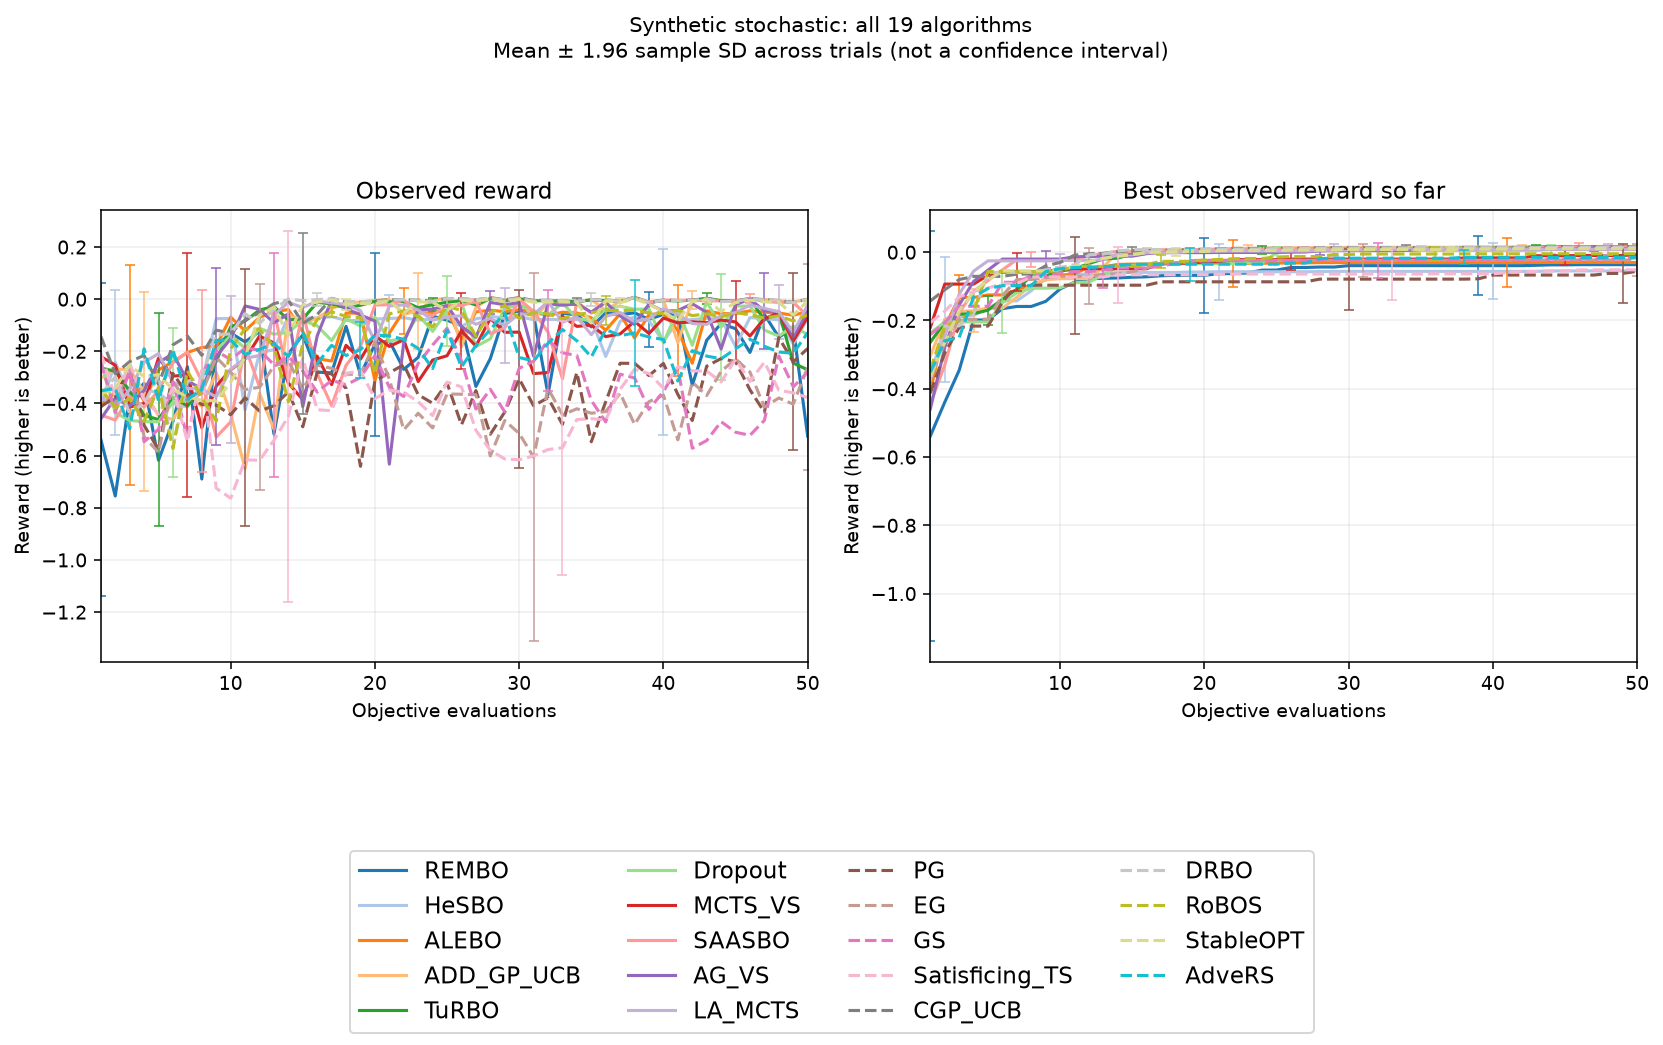

In [ ]:
import basat

seed = basat.set_seed(110, threads=1)
run_directory = basat.new_run_directory('results/last_guide/synthetic_stochastic_agvs_aistats2027_v1')
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def stochastic_objective(values):
    target = (0.2, 0.65, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))

# Fresh, fully explicit configurations for stochastic observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.0,
    initial_points=8,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.0,
    acquisition_optimizer=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=8,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=min(reduced_dimension, dimension - 1),
    sequence_length=2,
    split_groups=min(reduced_dimension + 1, dimension),
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed + 8),
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=8,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=8,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=8,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=8,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.StochasticEnvironment(
    bounds=bounds, function=stochastic_objective,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic stochastic: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

## 1.2 Contextual: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_contextual/run_afer_4e9/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -0.038469907 | 0
HeSBO | [50, 50, 50, 50, 50] | -0.02335136 | 0
ALEBO | [50, 50, 50, 50, 50] | -0.025897367 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | -0.041991983 | 0
TuRBO | [50, 50, 50, 50, 50] | -0.017621211 | 0
Dropout | [50, 50, 50, 50, 50] | -0.030845763 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -0.037111047 | 0
SAASBO | [50, 50, 50, 50, 50] | -0.021687364 | 0
AG_VS | [50, 50, 50, 50, 50] | -0.017438459 | 0
LA_MCTS | [50, 50, 50, 50, 50] | -0.034880386 | 0
PG | [50, 50, 50, 50, 50] | -0.0797253 | 0
EG | [50, 50, 50, 50, 50] | -0.013252706 | 0
GS | [50, 50, 50, 50, 50] | -0.033458616 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -0.033770236 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.014661133 | 0
DRBO | [

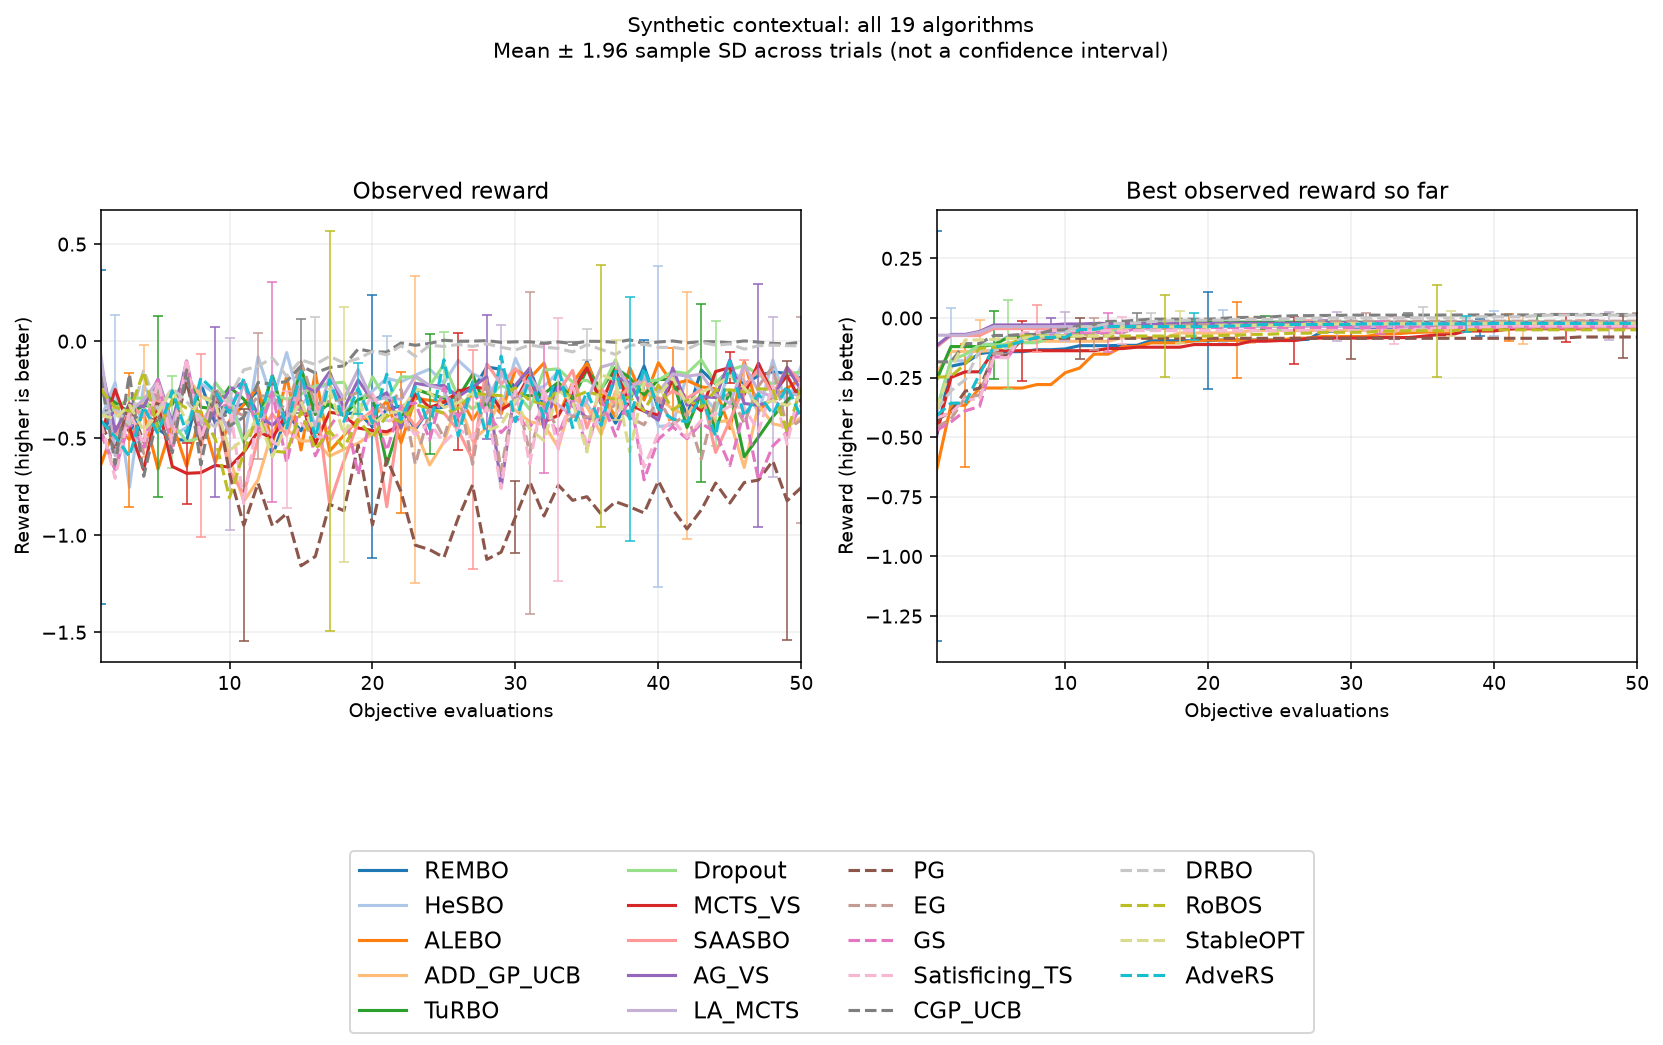

In [ ]:
import basat

seed = basat.set_seed(111, threads=1)
run_directory = basat.new_run_directory('results/last_guide/synthetic_contextual_agvs_aistats2027_v1')
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def contextual_objective(values, context):
    c = float(context[0])
    target = (0.2 + 0.5 * c, 0.75 - 0.4 * c, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def reveal_context(*, round_index, generator):
    return [float(round_index % 2)]

# Fresh, fully explicit configurations for contextual observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=2.5,
    initial_points=9,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=2.5,
    acquisition_optimizer=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=9,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=2.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=min(reduced_dimension, dimension - 1),
    sequence_length=2,
    split_groups=min(reduced_dimension + 1, dimension),
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed + 8),
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=9,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=2.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=9,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=2.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=9,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=2.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=9,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=2.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=2.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.ContextualEnvironment(
    bounds=bounds, function=contextual_objective,
    context_provider=reveal_context,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic contextual: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

## 1.3 Distributional: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_distributional/run_9g6_fprs/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | 0.0065654118 | 0
HeSBO | [50, 50, 50, 50, 50] | 0.0303242 | 0
ALEBO | [50, 50, 50, 50, 50] | 0.023973059 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 0.053510693 | 0
TuRBO | [50, 50, 50, 50, 50] | 0.025572192 | 0
Dropout | [50, 50, 50, 50, 50] | 0.039349369 | 0
MCTS_VS | [50, 50, 50, 50, 50] | 0.039916003 | 0
SAASBO | [50, 50, 50, 50, 50] | 0.055273367 | 0
AG_VS | [50, 50, 50, 50, 50] | 0.044804688 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 0.035250981 | 0
PG | [50, 50, 50, 50, 50] | -0.0089023057 | 0
EG | [50, 50, 50, 50, 50] | 0.022438961 | 0
GS | [50, 50, 50, 50, 50] | 0.011525091 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | 0.025894152 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.062909364 | 0
DRBO | [50, 50

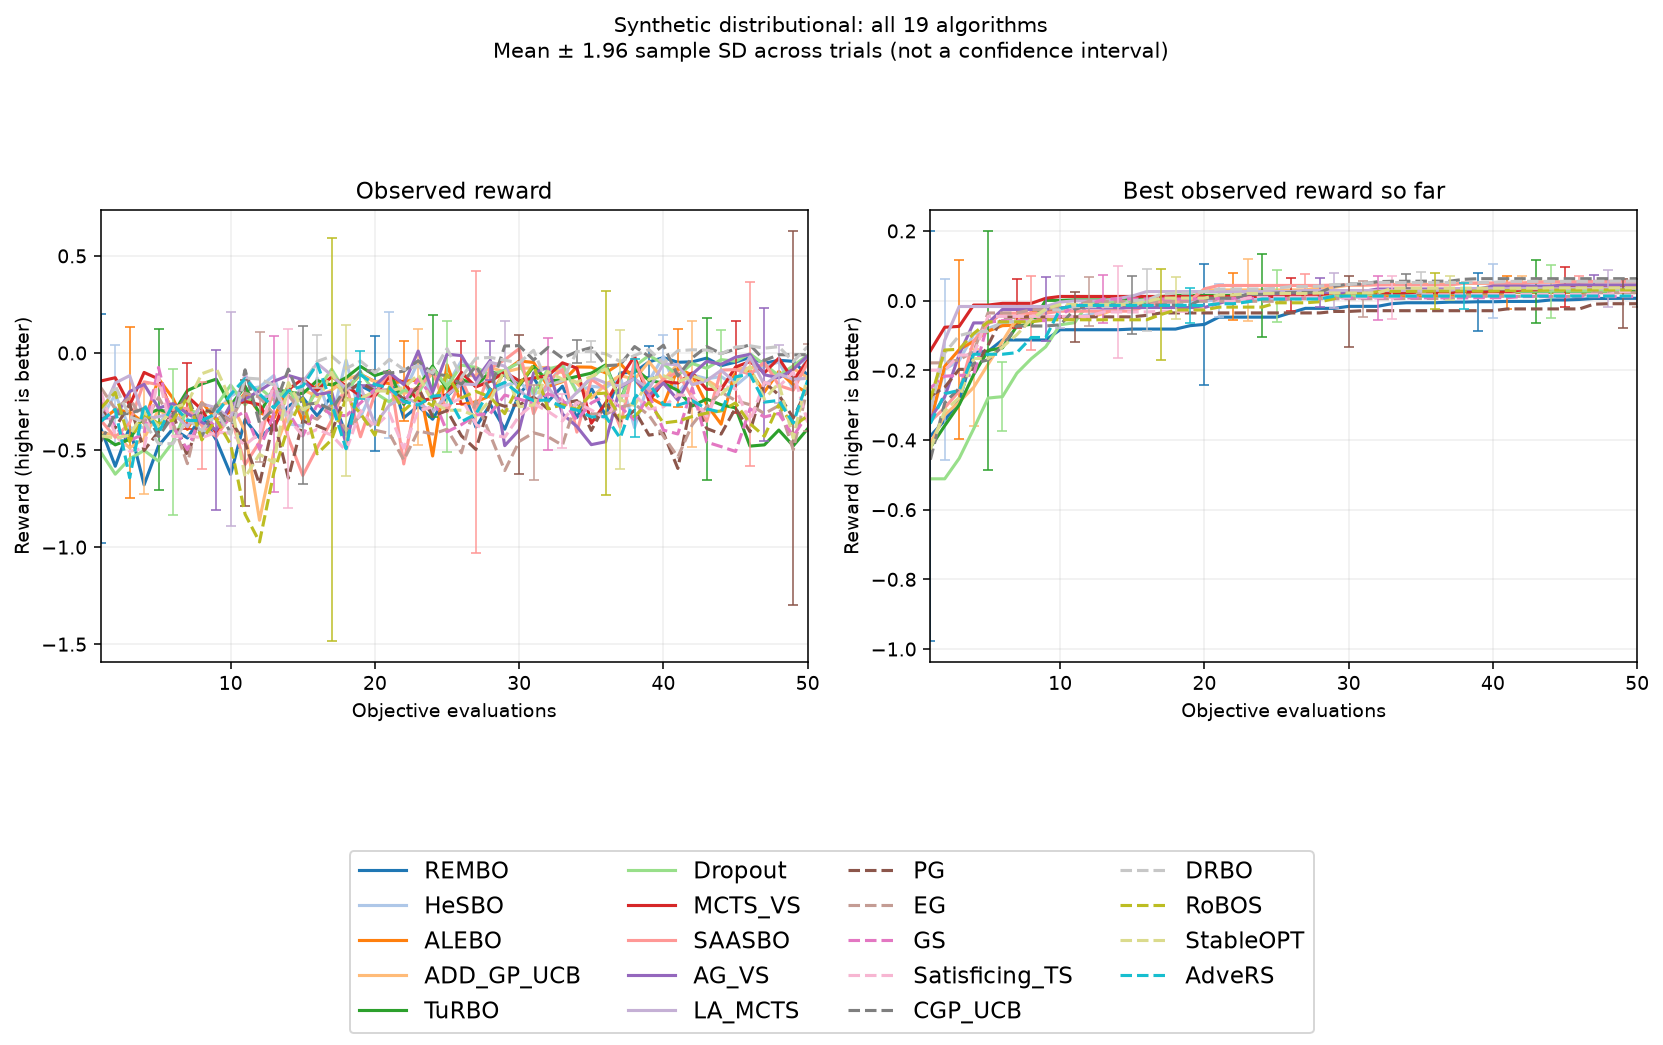

In [ ]:
import basat

seed = basat.set_seed(112, threads=1)
run_directory = basat.new_run_directory('results/last_guide/synthetic_distributional_agvs_aistats2027_v1')
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)
contexts = basat.array([[0.0], [1.0]], dtype="float64")

def distributional_objective(values, context):
    c = float(context[0])
    target = (0.25 + 0.35 * c, 0.6 - 0.2 * c, 0.3)
    distance = sum((x - t) ** 2 for x, t in zip(values, target))
    wave = 0.08 * basat.sin(6.0 * 3.141592653589793 * values[0])
    return float(-distance + wave)

# Fresh, fully explicit configurations for distributional observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern32',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.5,
    initial_points=10,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.5,
    acquisition_optimizer=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=10,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=min(reduced_dimension, dimension - 1),
    sequence_length=2,
    split_groups=min(reduced_dimension + 1, dimension),
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed + 8),
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=10,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=10,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=10,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=10,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.DistributionalEnvironment(
    bounds=bounds, function=distributional_objective,
    context_support=contexts, reference_distribution=[0.5, 0.5],
    sampling_distribution=[0.65, 0.35], margin=0.25,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic distributional: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

## 1.4 Adversarial: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_adversarial/run_crdnppew/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -0.00055410314 | 0
HeSBO | [50, 50, 50, 50, 50] | -0.016273457 | 0
ALEBO | [50, 50, 50, 50, 50] | 0.00280157 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 0.013408545 | 0
TuRBO | [50, 50, 50, 50, 50] | 0.013585926 | 0
Dropout | [50, 50, 50, 50, 50] | 0.0021817932 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -0.022155244 | 0
SAASBO | [50, 50, 50, 50, 50] | 0.011131831 | 0
AG_VS | [50, 50, 50, 50, 50] | 0.0078923088 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 0.0021800672 | 0
PG | [50, 50, 50, 50, 50] | -0.043551361 | 0
EG | [50, 50, 50, 50, 50] | -0.0076407504 | 0
GS | [50, 50, 50, 50, 50] | -0.017379693 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -0.052480618 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.014266291 | 0
DRBO |

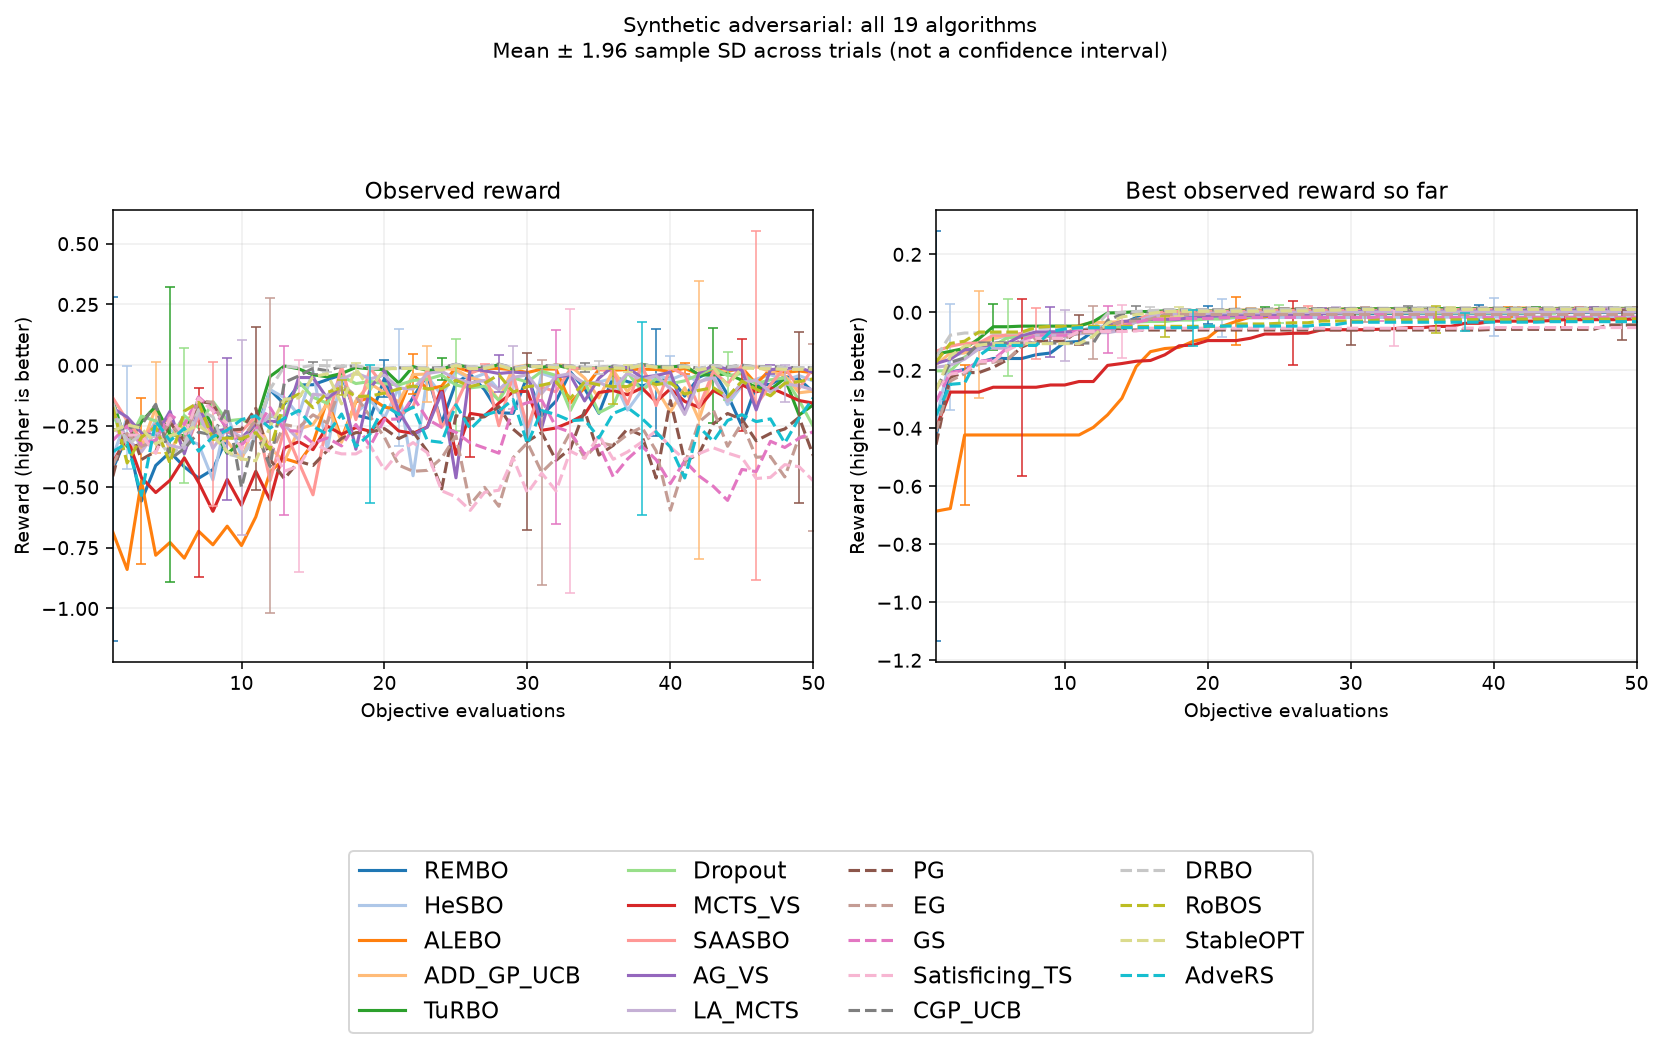

In [ ]:
import basat

seed = basat.set_seed(113, threads=1)
run_directory = basat.new_run_directory('results/last_guide/synthetic_adversarial_agvs_aistats2027_v1')
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def adversarial_objective(values):
    # This function receives the evaluated (already perturbed) coordinate.
    target = (0.3, 0.7, 0.5)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def apply_attack(action, *, round_index, generator):
    direction = 1.0 if round_index % 2 else -1.0
    changed = min(1.0, max(0.0, float(action[0]) + 0.05 * direction))
    return [changed - float(action[0]), 0.0, 0.0]

# Fresh, fully explicit configurations for adversarial observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=4.0,
    initial_points=11,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=4.0,
    acquisition_optimizer=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=11,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=4.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=min(reduced_dimension, dimension - 1),
    sequence_length=2,
    split_groups=min(reduced_dimension + 1, dimension),
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed + 8),
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=11,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=4.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=11,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=4.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=11,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=4.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=11,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=4.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=4.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.AdversarialEnvironment(
    bounds=bounds, function=adversarial_objective,
    attack=apply_attack,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic adversarial: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

# 2. Real Data Formatting

The strict native loader is `basat.load_dataset(path, environment="...")`.
It reads a finite table of **explicit rewards**, not a model-training dataset
whose last column is an arbitrary label. A row is an observation at the
named action and, where relevant, context. The library never invents missing
rewards or interpolates an unmeasured row. Your objective can instead train
a model or run a simulator inside a user-defined function if new evaluations
are possible.

Reserved columns use zero-based contiguous numbering. `action_0` through
`action_{d-1}` identify learner-controlled coordinates. `reward` is required
and must be the final column. Numeric values must be finite. Context vectors
describe exogenous information and need not have the same dimension as actions;
there is no automatic one-context-column-per-action-column rule.

| Environment | Required column order / roles | Learner sees before acting |
|---|---|---|
| Stochastic | action_0,...,action_(d-1),reward | Available action coordinates |
| Contextual | action_0,...,context_0,...,reward | Current context and actions available there |
| Distributional | action_0,...,context_0,...,reference_probability, optional sampling_probability and margin, reward | Support, reference probabilities, ambiguity margin |
| Adversarial | action_0,...,evaluated_action_0,...,reward | Nominal action coordinates; evaluated coordinate arrives in feedback |

Context is not a reward and must not contain the observed target as a shortcut.
Reward columns remain hidden from the learner until the environment evaluates
its selected action. This is offline finite search, not a causal evaluation of
treatments or a policy-value estimator for incomplete logged bandit data.
Arbitrary logged actions without counterfactual coverage cannot be treated as
a complete distributional reward grid.

The four code blocks below write actual sample rows using only Basat, reload
them, and print the exact CSV format. Replace the rows with your own measurements.
They demonstrate formatting; the four large experiments use the full external
files and reconstruct their own environments.

## Stochastic CSV

Only action columns and the final reward are required. The example
        records three scaled patient descriptors and a negative recorded response.
        Searching rows selects measured records, not a medical intervention.

In [6]:
import basat

# Four actual rows from the external example table.
columns = [
    'action_0',
    'action_1',
    'action_2',
    'reward',
]
rows = [
    [
        0.5826446280991735,
        0.5492957746478874,
        0.5622169960335567,
        -151.0,
    ],
    [
        0.14876033057851243,
        0.352112676056338,
        0.22243672996595168,
        -75.0,
    ],
    [
        0.5165289256198347,
        0.43661971830985913,
        0.49657762645231474,
        -141.0,
    ],
    [
        0.30165289256198347,
        0.30985915492957744,
        0.5729228825160587,
        -206.0,
    ],
]

directory = basat.new_run_directory("results/last_guide/format_stochastic")
path = basat.save_csv(
    basat.join_path(directory, "example.csv"),
    rows, columns=columns,
)
loaded = basat.load_dataset(path, environment="stochastic")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))

action_0,action_1,action_2,reward
0.5826446280991735,0.5492957746478874,0.5622169960335567,-151.0
0.14876033057851243,0.352112676056338,0.22243672996595168,-75.0
0.5165289256198347,0.43661971830985913,0.49657762645231474,-141.0
0.30165289256198347,0.30985915492957744,0.5729228825160587,-206.0
Action dimension: 3
Rows: 4


## Contextual CSV

Context dimensions are independent of action dimensions. Wine cultivar
        is encoded with three one-hot context columns so numeric distances do not
        imply an ordering of categories. All action/reward rows at a revealed
        cultivar are eligible; other cultivars' rewards remain unavailable.

In [7]:
import basat

# Four actual rows from the external example table.
columns = [
    'action_0',
    'action_1',
    'action_2',
    'context_0',
    'context_1',
    'context_2',
    'reward',
]
rows = [
    [
        0.8421052631578949,
        0.191699604743083,
        0.572192513368984,
        1.0,
        0.0,
        0.0,
        1065.0,
    ],
    [
        0.5710526315789473,
        0.2055335968379447,
        0.4171122994652407,
        1.0,
        0.0,
        0.0,
        1050.0,
    ],
    [
        0.5605263157894738,
        0.3201581027667984,
        0.7005347593582887,
        1.0,
        0.0,
        0.0,
        1185.0,
    ],
    [
        0.8789473684210525,
        0.2391304347826087,
        0.6096256684491979,
        1.0,
        0.0,
        0.0,
        1480.0,
    ],
]

directory = basat.new_run_directory("results/last_guide/format_contextual")
path = basat.save_csv(
    basat.join_path(directory, "example.csv"),
    rows, columns=columns,
)
loaded = basat.load_dataset(path, environment="contextual")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))

action_0,action_1,action_2,context_0,context_1,context_2,reward
0.8421052631578949,0.191699604743083,0.572192513368984,1.0,0.0,0.0,1065.0
0.5710526315789473,0.2055335968379447,0.4171122994652407,1.0,0.0,0.0,1050.0
0.5605263157894738,0.3201581027667984,0.7005347593582887,1.0,0.0,0.0,1185.0
0.8789473684210525,0.2391304347826087,0.6096256684491979,1.0,0.0,0.0,1480.0
Action dimension: 3
Rows: 4


## Distributional CSV

Every distinct action must have a measured row at every context in
        the support. `reference_probability` must agree across all rows of the same
        context and sum to one over support, not over CSV rows. `sampling_probability`
        has the same normalization and is environment-private. When omitted it
        equals the reference. `margin` is one consistent non-negative scalar;
        omitted margin defaults to zero. A multirow CSV repeats this metadata.
        The wind example uses 11 wind-generation levels. Its rewards are calculated
        from the published revenue function; they are not measured payments.
        Include all contexts when writing a smaller example so probabilities
        still sum to one. The real experiment overrides initial CSV probabilities
        with chronological 48-hour reference and private realization providers.

In [1]:
import basat

# Two actions with all 11 contexts: retain complete probability support.
columns = ['action_0', 'context_0', 'reference_probability', 'sampling_probability', 'margin', 'reward']
rows = [
    [0.0, 0.0, 0.0, 0.0, 0.1, 0.0],
    [0.0, 0.1, 0.0, 0.0, 0.1, 0.010000000000000002],
    [0.0, 0.2, 0.0, 0.0, 0.1, 0.020000000000000004],
    [0.0, 0.3, 0.6875, 0.0, 0.1, 0.03],
    [0.0, 0.4, 0.1875, 0.0, 0.1, 0.04000000000000001],
    [0.0, 0.5, 0.08333333333333333, 1.0, 0.1, 0.05],
    [0.0, 0.6, 0.041666666666666664, 0.0, 0.1, 0.06],
    [0.0, 0.7, 0.0, 0.0, 0.1, 0.06999999999999999],
    [0.0, 0.8, 0.0, 0.0, 0.1, 0.08000000000000002],
    [0.0, 0.9, 0.0, 0.0, 0.1, 0.09000000000000001],
    [0.0, 1.0, 0.0, 0.0, 0.1, 0.1],
    [0.01, 0.0, 0.0, 0.0, 0.1, -0.05],
    [0.01, 0.1, 0.0, 0.0, 0.1, 0.019000000000000003],
    [0.01, 0.2, 0.0, 0.0, 0.1, 0.029000000000000005],
    [0.01, 0.3, 0.6875, 0.0, 0.1, 0.039],
    [0.01, 0.4, 0.1875, 0.0, 0.1, 0.04900000000000001],
    [0.01, 0.5, 0.08333333333333333, 1.0, 0.1, 0.059000000000000004],
    [0.01, 0.6, 0.041666666666666664, 0.0, 0.1, 0.06899999999999999],
    [0.01, 0.7, 0.0, 0.0, 0.1, 0.07899999999999999],
    [0.01, 0.8, 0.0, 0.0, 0.1, 0.08900000000000001],
    [0.01, 0.9, 0.0, 0.0, 0.1, 0.099],
    [0.01, 1.0, 0.0, 0.0, 0.1, 0.109],
]

directory = basat.new_run_directory("results/last_guide/format_distributional_wind")
path = basat.save_csv(basat.join_path(directory, "example.csv"), rows, columns=columns)
loaded = basat.load_dataset(path, environment="distributional")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))


action_0,context_0,reference_probability,sampling_probability,margin,reward
0.0,0.0,0.0,0.0,0.1,0.0
0.0,0.1,0.0,0.0,0.1,0.010000000000000002
0.0,0.2,0.0,0.0,0.1,0.020000000000000004
0.0,0.3,0.6875,0.0,0.1,0.03
Action dimension: 1
Rows: 22


## Adversarial CSV

Both nominal and evaluated action vectors have dimension d. The final
        reward belongs to the evaluated coordinate. This finite-table contract
        requires a deterministic one-to-one permutation over the measured action
        set, so every attack lookup has a real measured outcome and consumed rows
        remain consistent. Arbitrary off-grid attacks are rejected in finite mode;
        use a function-backed environment to evaluate new coordinates. The Iris
        example constructs swaps between measured records. It is an illustrative
        adversarial view of observational data, not a historical attack dataset.

In [9]:
import basat

# Four actual rows from the external example table.
columns = [
    'action_0',
    'action_1',
    'action_2',
    'evaluated_action_0',
    'evaluated_action_1',
    'evaluated_action_2',
    'reward',
]
rows = [
    [
        0.0,
        0.423728813559322,
        0.375,
        0.0833333333333334,
        0.5084745762711864,
        0.375,
        6.0,
    ],
    [
        0.0833333333333334,
        0.5084745762711864,
        0.375,
        0.0,
        0.423728813559322,
        0.375,
        5.0,
    ],
    [
        0.0833333333333334,
        0.5932203389830508,
        0.5833333333333334,
        0.0833333333333334,
        0.6779661016949152,
        0.5833333333333334,
        6.0,
    ],
    [
        0.0833333333333334,
        0.6779661016949152,
        0.5833333333333334,
        0.0833333333333334,
        0.5932203389830508,
        0.5833333333333334,
        6.2,
    ],
]

directory = basat.new_run_directory("results/last_guide/format_adversarial")
path = basat.save_csv(
    basat.join_path(directory, "example.csv"),
    rows, columns=columns,
)
loaded = basat.load_dataset(path, environment="adversarial")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))

action_0,action_1,action_2,evaluated_action_0,evaluated_action_1,evaluated_action_2,reward
0.0,0.423728813559322,0.375,0.0833333333333334,0.5084745762711864,0.375,6.0
0.0833333333333334,0.5084745762711864,0.375,0.0,0.423728813559322,0.375,5.0
0.0833333333333334,0.5932203389830508,0.5833333333333334,0.0833333333333334,0.6779661016949152,0.5833333333333334,6.0
0.0833333333333334,0.6779661016949152,0.5833333333333334,0.0833333333333334,0.5932203389830508,0.5833333333333334,6.2
Action dimension: 3
Rows: 4


## 2.1 Real Life Objective Optimization

Four **different** real datasets provide four large independent comparisons.
The updated runnable examples submit 19 algorithms in each of the three
three-dimensional datasets and 18 in the one-dimensional wind dataset,
with five trials each: **375 submitted algorithm trials**. The archived
outputs retain their original 380 submitted trials.
Non-native combinations use the documented runtime defaults and emit
informative warnings. Genuine failures remain visible in summaries and
legends. The source's
finite reward table is copied privately for each method. No main experiment
enables patience, target, or time stopping; each requests 50 evaluations.

REMBO, HeSBO, and ALEBO use `finite_candidate_mode="project"` by default.
This explicit finite-data extension compresses normalized candidate rows:
REMBO uses least-squares coordinates, HeSBO uses signed bucket averages
(zero for empty buckets), and ALEBO uses its B projection. Acquisition scores
select an actual available row and the environment returns its stored reward.
The wind table stores explicitly modeled revenue; its physical context comes
from measurements. No reward interpolation is performed by the library. Projection
can merge distinct rows, so the original embedding guarantees do not apply.
The warning `data.projected_embedding` explains this adaptation. Set the
configuration field to `"exact"` to restore strict embedding checks.

The original environment classes remain in use. Context still restricts
available contextual rows, the distribution still selects the wind-generation
context, and the adversarial environment still applies its declared attack.
These stochastic policies model pooled scalar feedback without conditioning
on those additional inputs; execution does not imply contextual or robust
optimality. A distribution alone is not enough: evaluation still requires
a reward table or callable objective.

| Environment | Distinct external dataset | Reward and constructed interpretation |
|---|---|---|
| Stochastic | Diabetes | Negative recorded one-year progression; search among measured descriptor rows |
| Contextual | Wine | Recorded proline concentration, conditional on one-hot cultivar |
| Distributional | OPSD German wind generation (2013) | Energy commitment revenue under recorded wind realizations; modeled revenue, not measured market payments |
| Adversarial | Iris | Measured sepal length at a permuted observed coordinate |

These are explicitly constructed finite optimization views of four real
observational tables. They were not collected as four native online bandit
trials. The results do not establish clinical benefits, causal effects,
distributional robustness, or adversarial guarantees for the original studies.
We optimize the stated scalar rewards, including the explicit wind revenue model,
not classification accuracy.
For your own application, select a reward whose maximization is meaningful.

Provenance, source URLs, exact transformations, and SHA-256 hashes are in
`data/native_manifest.json`. The original files and prepared CSVs remain under
the project-level `data/` folder; none are packaged inside Basat. Dataset
descriptions are documented by
[scikit-learn's dataset reference](https://scikit-learn.org/1.6/datasets/toy_dataset.html)
and the wind-source and DRBO references in the distributional subsection.

In the adversarial Iris experiment, StableOPT's selected radius 2 covers the entire [0,1]^3 action box and
the constructed swaps. AdveRS instead considers the full feasible domain
without receiving the environment's actual attack budget. A small-radius assumption would be false for these
data. Best observed reward traces measure sampled outcomes, not the robust
objectives optimized by DRBO, RoBOS, StableOPT, or AdveRS.

### Stochastic: diabetes / all 19 algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_stochastic/run_32679mqf/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -38.2 | 0
HeSBO | [50, 50, 50, 50, 50] | -36.8 | 0
ALEBO | [50, 50, 50, 50, 50] | -41 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | -31 | 0
TuRBO | [50, 50, 50, 50, 50] | -43 | 0
Dropout | [50, 50, 50, 50, 50] | -41.6 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -42.2 | 0
SAASBO | [50, 50, 50, 50, 50] | -42.6 | 0
AG_VS | [50, 50, 50, 50, 50] | -34.2 | 0
LA_MCTS | [50, 50, 50, 50, 50] | -45 | 0
PG | [50, 50, 50, 50, 50] | -49 | 0
EG | [50, 50, 50, 50, 50] | -49 | 0
GS | [50, 50, 50, 50, 50] | -49 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -49 | 0
CGP_UCB | [50, 50, 50, 50, 50] | -37 | 0
DRBO | [50, 50, 50, 50, 50] | -49 | 0
RoBOS | [50, 50, 50, 50, 50] | -49 | 0
StableOPT | [50, 50, 50, 50, 50] | -31 | 0
AdveRS | [50

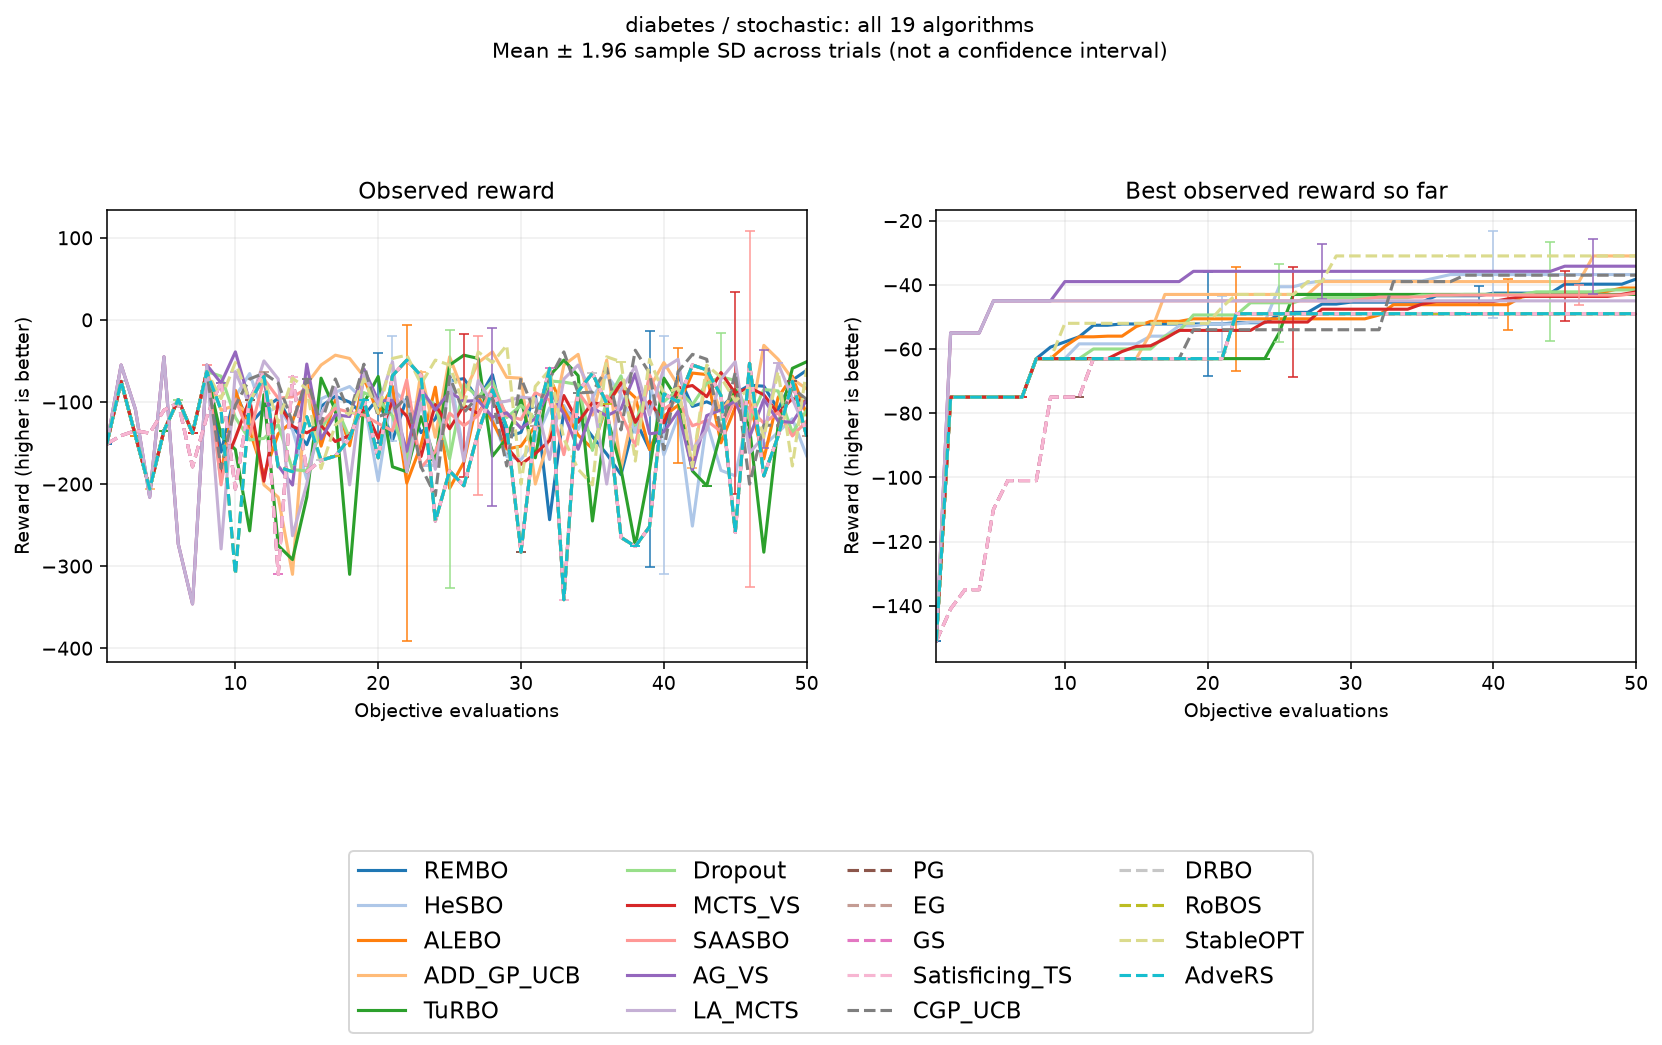

In [ ]:
import basat

seed = basat.set_seed(210, threads=1)
data_path = basat.find_path("data/stochastic/diabetes_bandit.csv")
loaded = basat.load_dataset(data_path, environment="stochastic")
print(loaded.preview(rows=3))
bounds = loaded.bounds
run_directory = basat.new_run_directory('results/last_guide/real_stochastic_agvs_aistats2027_v1')

# Fresh, fully explicit configurations for stochastic observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.0,
    initial_points=8,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.0,
    acquisition_optimizer=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=8,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=min(reduced_dimension, dimension - 1),
    sequence_length=2,
    split_groups=min(reduced_dimension + 1, dimension),
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed + 8),
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=8,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=8,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=8,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=8,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.StochasticEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="diabetes / stochastic: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

### Contextual: wine / all 19 algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_contextual/run_r5auk5rn/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | 1640 | 0
HeSBO | [50, 50, 50, 50, 50] | 1626.8 | 0
ALEBO | [50, 50, 50, 50, 50] | 1680 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 1680 | 0
TuRBO | [50, 50, 50, 50, 50] | 1619.4 | 0
Dropout | [50, 50, 50, 50, 50] | 1626.8 | 0
MCTS_VS | [50, 50, 50, 50, 50] | 1573.6 | 0
SAASBO | [50, 50, 50, 50, 50] | 1653.4 | 0
AG_VS | [50, 50, 50, 50, 50] | 1680 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 1626.8 | 0
PG | [50, 50, 50, 50, 50] | 1626.8 | 0
EG | [50, 50, 50, 50, 50] | 1626.8 | 0
GS | [50, 50, 50, 50, 50] | 1626.8 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | 1419 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 1480 | 0
DRBO | [50, 50, 50, 50, 50] | 1574 | 0
RoBOS | [50, 50, 50, 50, 50] | 1574 | 0
StableOPT | [50, 50, 50, 50, 50]

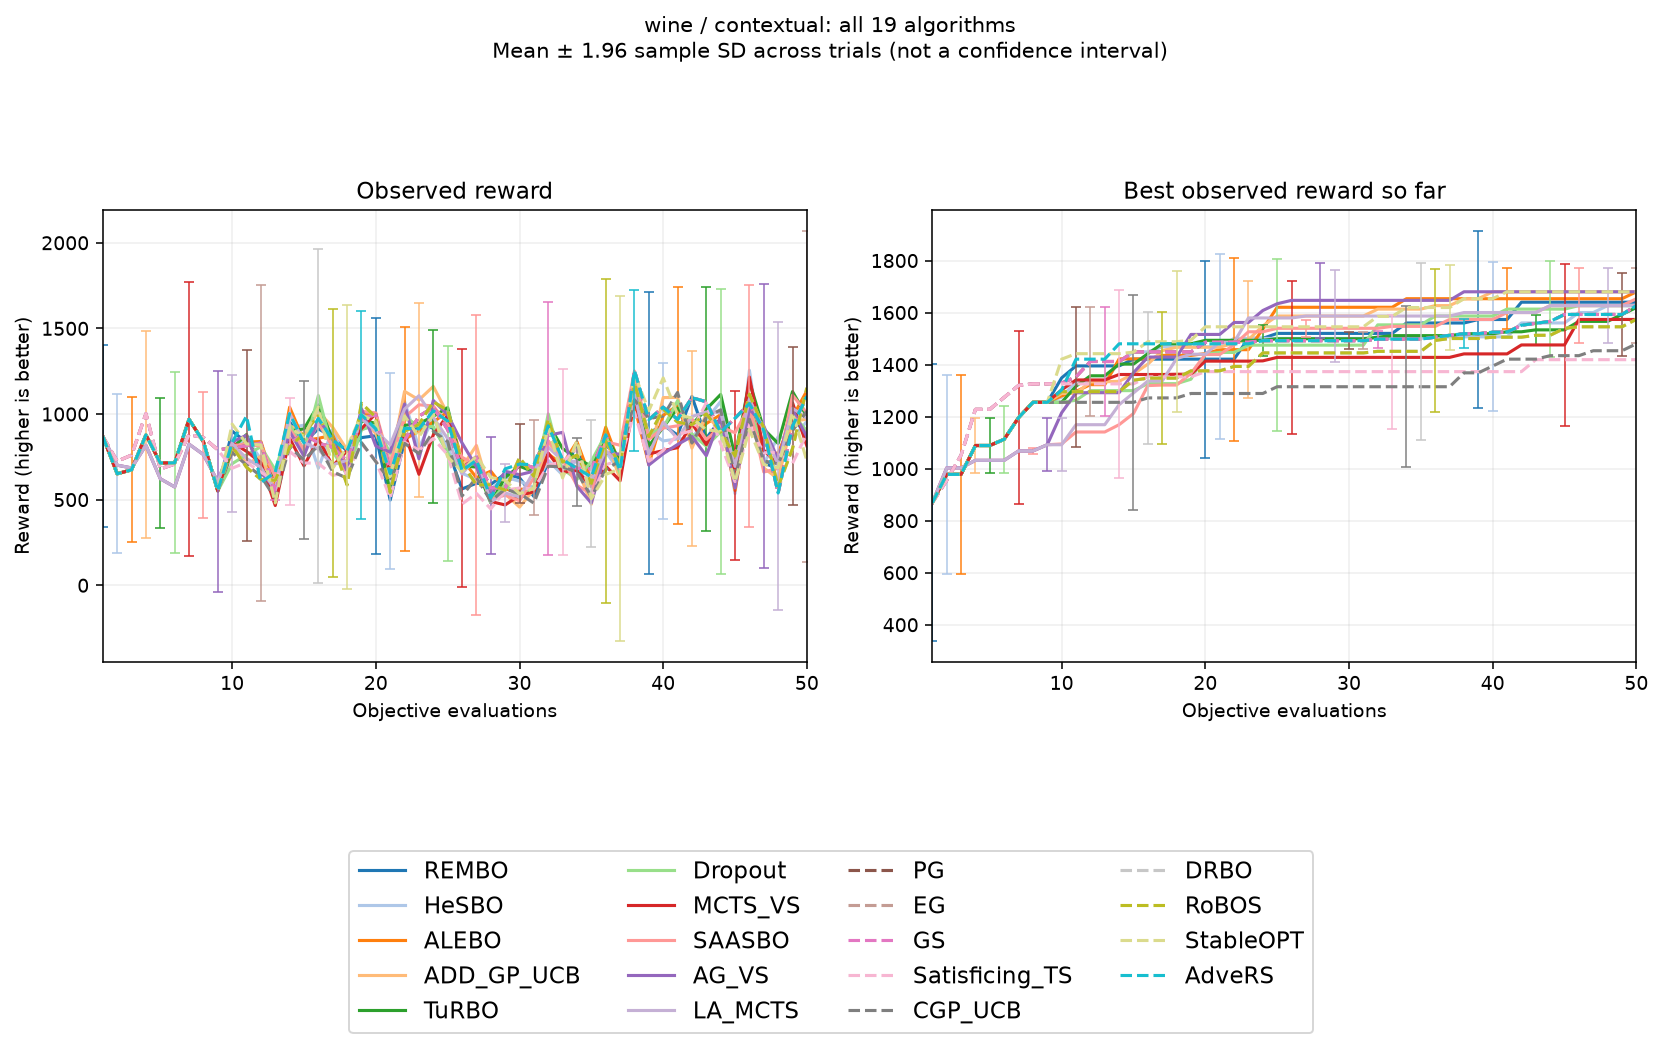

In [ ]:
import basat

seed = basat.set_seed(211, threads=1)
data_path = basat.find_path("data/contextual/wine_bandit.csv")
loaded = basat.load_dataset(data_path, environment="contextual")
print(loaded.preview(rows=3))
bounds = loaded.bounds
run_directory = basat.new_run_directory('results/last_guide/real_contextual_agvs_aistats2027_v1')

# Fresh, fully explicit configurations for contextual observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=2.5,
    initial_points=9,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=2.5,
    acquisition_optimizer=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=9,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=2.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=min(reduced_dimension, dimension - 1),
    sequence_length=2,
    split_groups=min(reduced_dimension + 1, dimension),
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed + 8),
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=9,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=2.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=9,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=2.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=9,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=2.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=9,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=2.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=2.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.ContextualEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    context_provider=None,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="wine / contextual: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

### Distributional: wind_power / 18 supported algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

### Distributional wind-power commitment: dataset and replay

This replaces the breast-cancer example with hourly wind-generation data from
[Open Power System Data, version 2019-06-05](https://data.open-power-system-data.org/time_series/2019-06-05/),
the data package cited in [DRBO, Section 4](https://proceedings.mlr.press/v108/kirschner20a/kirschner20a.pdf).
The retained source contains 98 consecutive German hourly observations from January 2013: generation, capacity, and capacity factor.

The action is promised energy as a fraction of capacity; context is realized wind generation.
The paper's revenue is `0.1*max(c-x, 0) + min(x,c) - 5*max(x-c, 0)`.
Here, a complete CSV table evaluates that formula on 101 action values and 11 context values.
These revenues are calculated from an economic model; they are not recorded electricity payments.

The guide replays 50 consecutive hours after an initial 48-hour history, rounding recorded
capacity factors to the nearest 0.1. Each round's public reference uses only its preceding 48
observations. The environment's private sampling distribution puts probability one on that
hour's recorded, quantized realization; future context is not passed to the algorithm.
The fixed ambiguity margin 0.1 is illustrative, not calibrated to guarantee coverage.
Repeated commitments are allowed. The 18 supported methods receive the same chronological trace,
with 5 independent algorithm seeds and at most 50 evaluations each.

This small replay is an adaptation of the paper's application, not a reproduction of its
annual simulator experiment or robust-regret figures. The plotted observed reward and
best-observed reward do not measure robust regret; a lucky high-wind hour can improve the
latter. Because the physical action is one-dimensional, embedding dimension is also one;
this example does not demonstrate an advantage from high-dimensional embedding.

RoBOS uses a Matern-3/2 context kernel to avoid the initially configured RBF kernel's near-singular Gram matrix on this support. Completed trials of the other 18 methods were resumed unchanged; RoBOS was rerun.


AG-VS requires at least two action coordinates in the supplied source.
This one-dimensional commitment example therefore runs 18 methods.
The archived plot retains its original 19-method measurements.


action_0,context_0,reference_probability,sampling_probability,margin,reward
0.0,0.0,0.0,0.0,0.1,0.0
0.0,0.1,0.0,0.0,0.1,0.010000000000000002
0.0,0.2,0.0,0.0,0.1,0.020000000000000004
Configured algorithms: 19 ['REMBO', 'HeSBO', 'ALEBO', 'ADD_GP_UCB', 'TuRBO', 'Dropout', 'MCTS_VS', 'SAASBO', 'AG_VS', 'LA_MCTS', 'PG', 'EG', 'GS', 'Satisficing_TS', 'CGP_UCB', 'DRBO', 'RoBOS', 'StableOPT', 'AdveRS']
Algorithms submitted: 19
Names: ['REMBO', 'HeSBO', 'ALEBO', 'ADD_GP_UCB', 'TuRBO', 'Dropout', 'MCTS_VS', 'SAASBO', 'AG_VS', 'LA_MCTS', 'PG', 'EG', 'GS', 'Satisficing_TS', 'CGP_UCB', 'DRBO', 'RoBOS', 'StableOPT', 'AdveRS']
Trial 1/5 (seed offset +0)
[REMBO] starting


basat/experiment.py:750: REMBOWarning: REMBO is outside its native environment type ['stochastic'] in the 'distributional' environment. No required inputs are missing; no internal defaults were needed. Additional environment information is ignored.
  with (
basat/experiment.py:750: REMBOWarning: REMBO compresses available finite action rows into embedding coordinates and scores those rows directly. It returns the actual recorded action; rewards are not interpolated. Context, distribution and perturbation information are not used by this stochastic policy. This finite-data extension does not inherit the original embedding guarantees. Set finite_candidate_mode='exact' to require the original embedding geometry.
  with (
basat/experiment.py:750: HeSBOWarning: HeSBO is outside its native environment type ['stochastic'] in the 'distributional' environment. No required inputs are missing; no internal defaults were needed. Additional environment information is ignored.
  with (
basat/experime

[REMBO] evaluations=50, best=0.44999999999999996
[HeSBO] starting
[HeSBO] evaluations=50, best=0.6
[ALEBO] starting
[ALEBO] evaluations=50, best=0.519
[ADD_GP_UCB] starting
[ADD_GP_UCB] evaluations=50, best=0.06
[TuRBO] starting
[TuRBO] evaluations=50, best=0.5640000000000001
[Dropout] starting
[Dropout] evaluations=50, best=0.473
[MCTS_VS] starting
[MCTS_VS] evaluations=50, best=0.591
[SAASBO] starting
[SAASBO] evaluations=50, best=0.573
[AG_VS] starting
[AG_VS] evaluations=50, best=0.519
[LA_MCTS] starting
[LA_MCTS] evaluations=50, best=0.582
[PG] starting
[PG] evaluations=50, best=0.14100000000000001
[EG] starting
[EG] evaluations=50, best=0.14100000000000001
[GS] starting
[GS] evaluations=50, best=0.14100000000000001
[Satisficing_TS] starting
[Satisficing_TS] evaluations=50, best=0.51
[CGP_UCB] starting
[CGP_UCB] evaluations=50, best=0.384
[DRBO] starting
[DRBO] evaluations=50, best=0.06
[RoBOS] starting
[RoBOS] evaluations=50, best=0.06
[StableOPT] starting
[StableOPT] evaluations

basat/trials.py:279: REMBOWarning: REMBO is outside its native environment type ['stochastic'] in the 'distributional' environment. No required inputs are missing; no internal defaults were needed. Additional environment information is ignored.
  with experiment._capture_warnings("trial runs"):
basat/trials.py:279: REMBOWarning: REMBO compresses available finite action rows into embedding coordinates and scores those rows directly. It returns the actual recorded action; rewards are not interpolated. Context, distribution and perturbation information are not used by this stochastic policy. This finite-data extension does not inherit the original embedding guarantees. Set finite_candidate_mode='exact' to require the original embedding geometry.
  with experiment._capture_warnings("trial runs"):
basat/trials.py:279: HeSBOWarning: HeSBO is outside its native environment type ['stochastic'] in the 'distributional' environment. No required inputs are missing; no internal defaults were needed

[REMBO] evaluations=50, best=0.555
[HeSBO] starting
[HeSBO] evaluations=50, best=0.6
[ALEBO] starting
[ALEBO] evaluations=50, best=0.519
[ADD_GP_UCB] starting
[ADD_GP_UCB] evaluations=50, best=0.06
[TuRBO] starting
[TuRBO] evaluations=50, best=0.5640000000000001
[Dropout] starting
[Dropout] evaluations=50, best=0.473
[MCTS_VS] starting
[MCTS_VS] evaluations=50, best=0.591
[SAASBO] starting
[SAASBO] evaluations=50, best=0.573
[AG_VS] starting
[AG_VS] evaluations=50, best=0.519
[LA_MCTS] starting
[LA_MCTS] evaluations=50, best=0.582
[PG] starting
[PG] evaluations=50, best=0.14100000000000001
[EG] starting
[EG] evaluations=50, best=0.14100000000000001
[GS] starting
[GS] evaluations=50, best=0.14100000000000001
[Satisficing_TS] starting
[Satisficing_TS] evaluations=50, best=0.51
[CGP_UCB] starting
[CGP_UCB] evaluations=50, best=0.384
[DRBO] starting
[DRBO] evaluations=50, best=0.06
[RoBOS] starting
[RoBOS] evaluations=50, best=0.06
[StableOPT] starting
[StableOPT] evaluations=50, best=0.54

basat/trials.py:279: SAASBOWarning: NUTS reported 3 divergent transitions. Finite, loadable posterior draws were retained under diagnostic_policy='warn'; source guarantees no longer apply.
  with experiment._capture_warnings("trial runs"):


[REMBO] evaluations=50, best=0.455
[HeSBO] starting
[HeSBO] evaluations=50, best=0.6
[ALEBO] starting
[ALEBO] evaluations=50, best=0.519
[ADD_GP_UCB] starting
[ADD_GP_UCB] evaluations=50, best=0.06
[TuRBO] starting
[TuRBO] evaluations=50, best=0.5640000000000001
[Dropout] starting
[Dropout] evaluations=50, best=0.473
[MCTS_VS] starting
[MCTS_VS] evaluations=50, best=0.591
[SAASBO] starting
[SAASBO] evaluations=50, best=0.573
[AG_VS] starting
[AG_VS] evaluations=50, best=0.519
[LA_MCTS] starting
[LA_MCTS] evaluations=50, best=0.582
[PG] starting
[PG] evaluations=50, best=0.14100000000000001
[EG] starting
[EG] evaluations=50, best=0.14100000000000001
[GS] starting
[GS] evaluations=50, best=0.14100000000000001
[Satisficing_TS] starting
[Satisficing_TS] evaluations=50, best=0.51
[CGP_UCB] starting
[CGP_UCB] evaluations=50, best=0.384
[DRBO] starting
[DRBO] evaluations=50, best=0.06
[RoBOS] starting
[RoBOS] evaluations=50, best=0.06
[StableOPT] starting
[StableOPT] evaluations=50, best=0.54

basat/trials.py:279: SAASBOWarning: NUTS reported 2 divergent transitions. Finite, loadable posterior draws were retained under diagnostic_policy='warn'; source guarantees no longer apply.
  with experiment._capture_warnings("trial runs"):


Basat: 5 trials
REMBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.48519999999999996
HeSBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.6
ALEBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.519
ADD_GP_UCB: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.06
TuRBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.5640000000000001
Dropout: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.473
MCTS_VS: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.591
SAASBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.573
AG_VS: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.519
LA_MCTS: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.582
PG: evaluations per trial=[50, 50, 50, 50, 50]; 

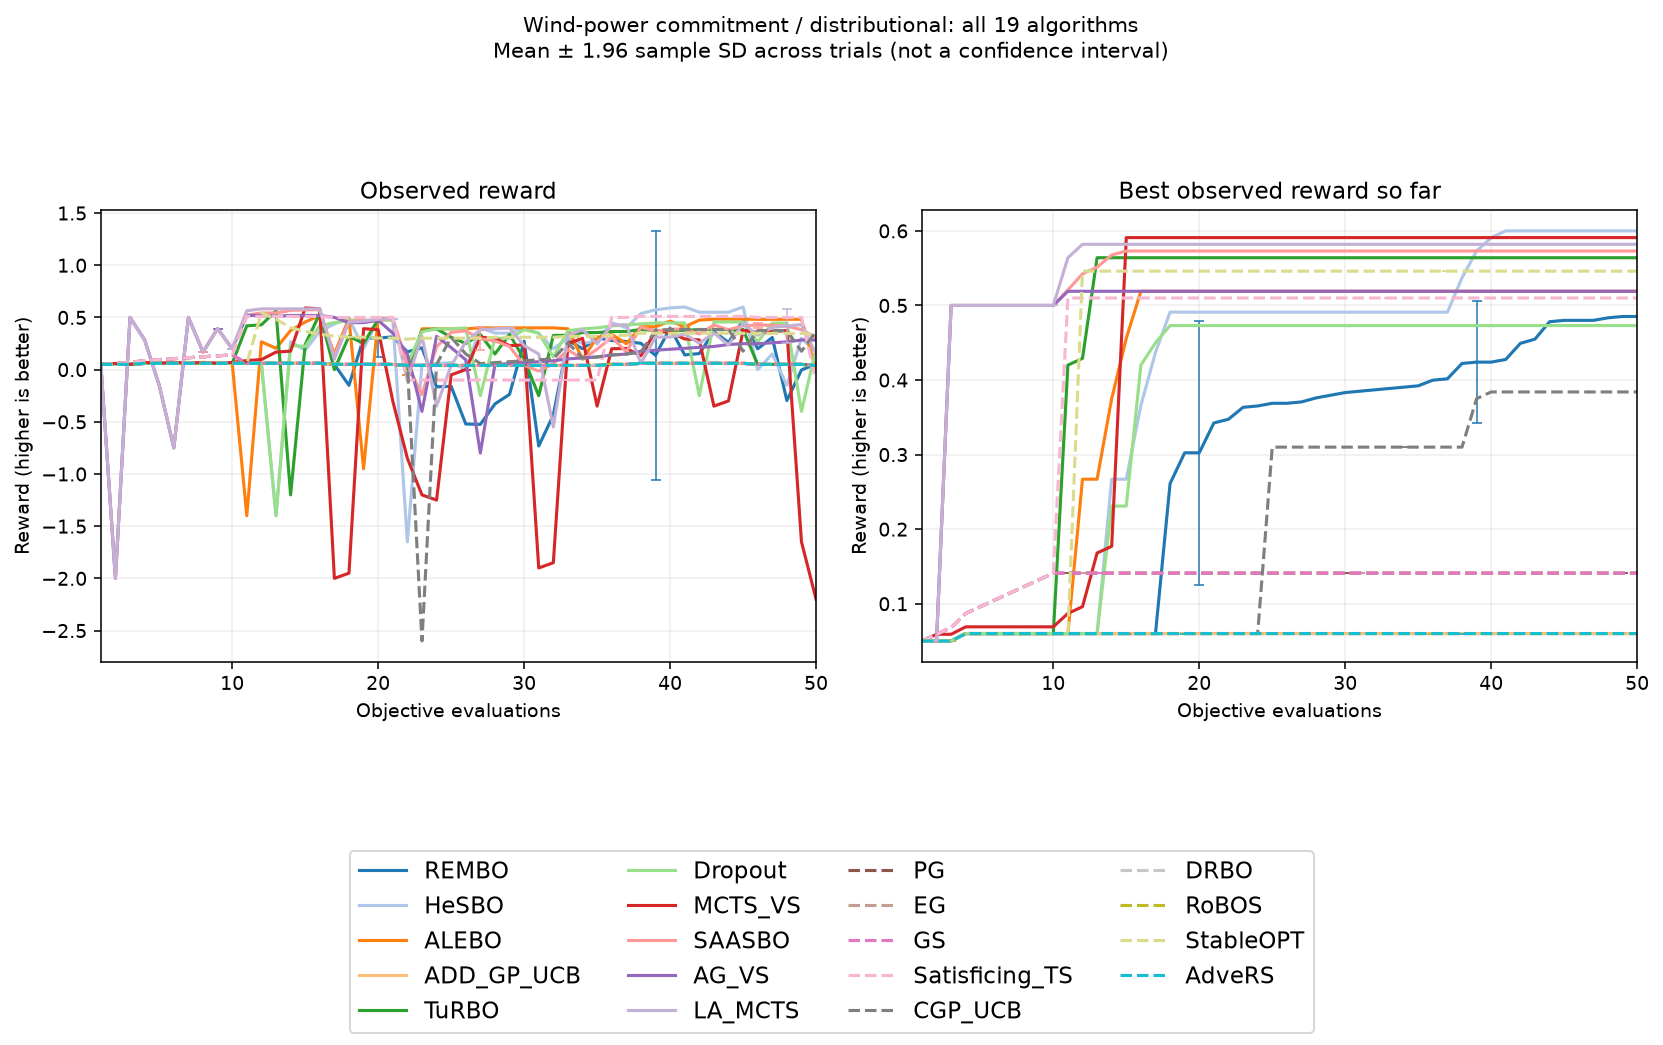

Saved results: results/last_guide/real_distributional_wind/run_matern_context


In [1]:
import basat

seed = basat.set_seed(212, threads=1)
data_path = basat.find_path("data/distributional/wind_power_bandit.csv")
loaded = basat.load_dataset(data_path, environment="distributional")
print(loaded.preview(rows=3))
bounds = loaded.bounds
# This named directory resumes saved trials. Choose another name for a fresh run.
run_directory = basat.join_path("results/last_guide/real_distributional_wind", "run_matern_context_agvs_aistats2027_v1")

# Fresh, fully explicit configurations for distributional observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern32',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.5,
    initial_points=10,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.5,
    acquisition_optimizer=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=10,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)


la_mcts_config = basat.LAMCTSConfig(
    initial_points=10,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=10,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=10,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    # Matern is numerically well-conditioned on this 11-point context grid.
    context_kernel=basat.KernelConfig(name='matern32'),
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=10,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


# Real hourly German wind generation, from the data package cited by DRBO.
# This CSV subset has no quoted fields; column 4 is recorded capacity factor.
with open(basat.find_path("data/distributional/opsd_wind_2013.csv")) as stream:
    source_lines = stream.read().splitlines()
wind_profiles = [float(line.split(",")[3]) for line in source_lines[1:99]]
# Fixed 11-point support: quantize observed capacity factors to nearest 0.1.
wind_indices = tuple(min(10, max(0, int(value * 10 + 0.5))) for value in wind_profiles)
assert len(wind_indices) == 98  # 48 history hours + 50 evaluation hours


def reference_at_round(round_index):
    # Only past observations contribute to the public 48-hour reference.
    history = wind_indices[round_index:round_index + 48]
    return [history.count(j) / len(history) for j in range(11)]


def realized_wind_at_round(round_index):
    # The environment keeps this next observation private until evaluation.
    if not 0 <= round_index < 50:
        raise ValueError("This replay contains 50 evaluation hours.")
    actual_index = wind_indices[48 + round_index]
    return [float(j == actual_index) for j in range(11)]


# Every CSV reward is calculated from the paper's revenue formula:
# def objective(x, c):
#     return 0.1 * max(c - x, 0) + min(x, c) - 5 * max(x - c, 0)
# x and c are fractions of installed capacity. Revenue is modeled, not measured.
# The initial CSV probabilities are overridden by the providers above.
environment = basat.DistributionalEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    context_support=loaded.context_support,
    reference_distribution=reference_at_round,
    sampling_distribution=realized_wind_at_round,
    margin=loaded.margin,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=True, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=True, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Wind-power commitment / distributional: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

### Adversarial: iris / all 19 algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_adversarial/run_mimnzoy_/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | 7.74 | 0
HeSBO | [50, 50, 50, 50, 50] | 7.7 | 0
ALEBO | [50, 50, 50, 50, 50] | 7.74 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 7.7 | 0
TuRBO | [50, 50, 50, 50, 50] | 7.7 | 0
Dropout | [50, 50, 50, 50, 50] | 7.7 | 0
MCTS_VS | [50, 50, 50, 50, 50] | 7.7 | 0
SAASBO | [50, 50, 50, 50, 50] | 7.74 | 0
AG_VS | [50, 50, 50, 50, 50] | 7.7 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 7.9 | 0
PG | [50, 50, 50, 50, 50] | 7.7 | 0
EG | [50, 50, 50, 50, 50] | 7.7 | 0
GS | [50, 50, 50, 50, 50] | 7.7 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | 7 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 7.7 | 0
DRBO | [50, 50, 50, 50, 50] | 7.7 | 0
RoBOS | [50, 50, 50, 50, 50] | 7.7 | 0
StableOPT | [50, 50, 50, 50, 50] | 7.9 | 0
AdveRS | [50, 50, 50, 

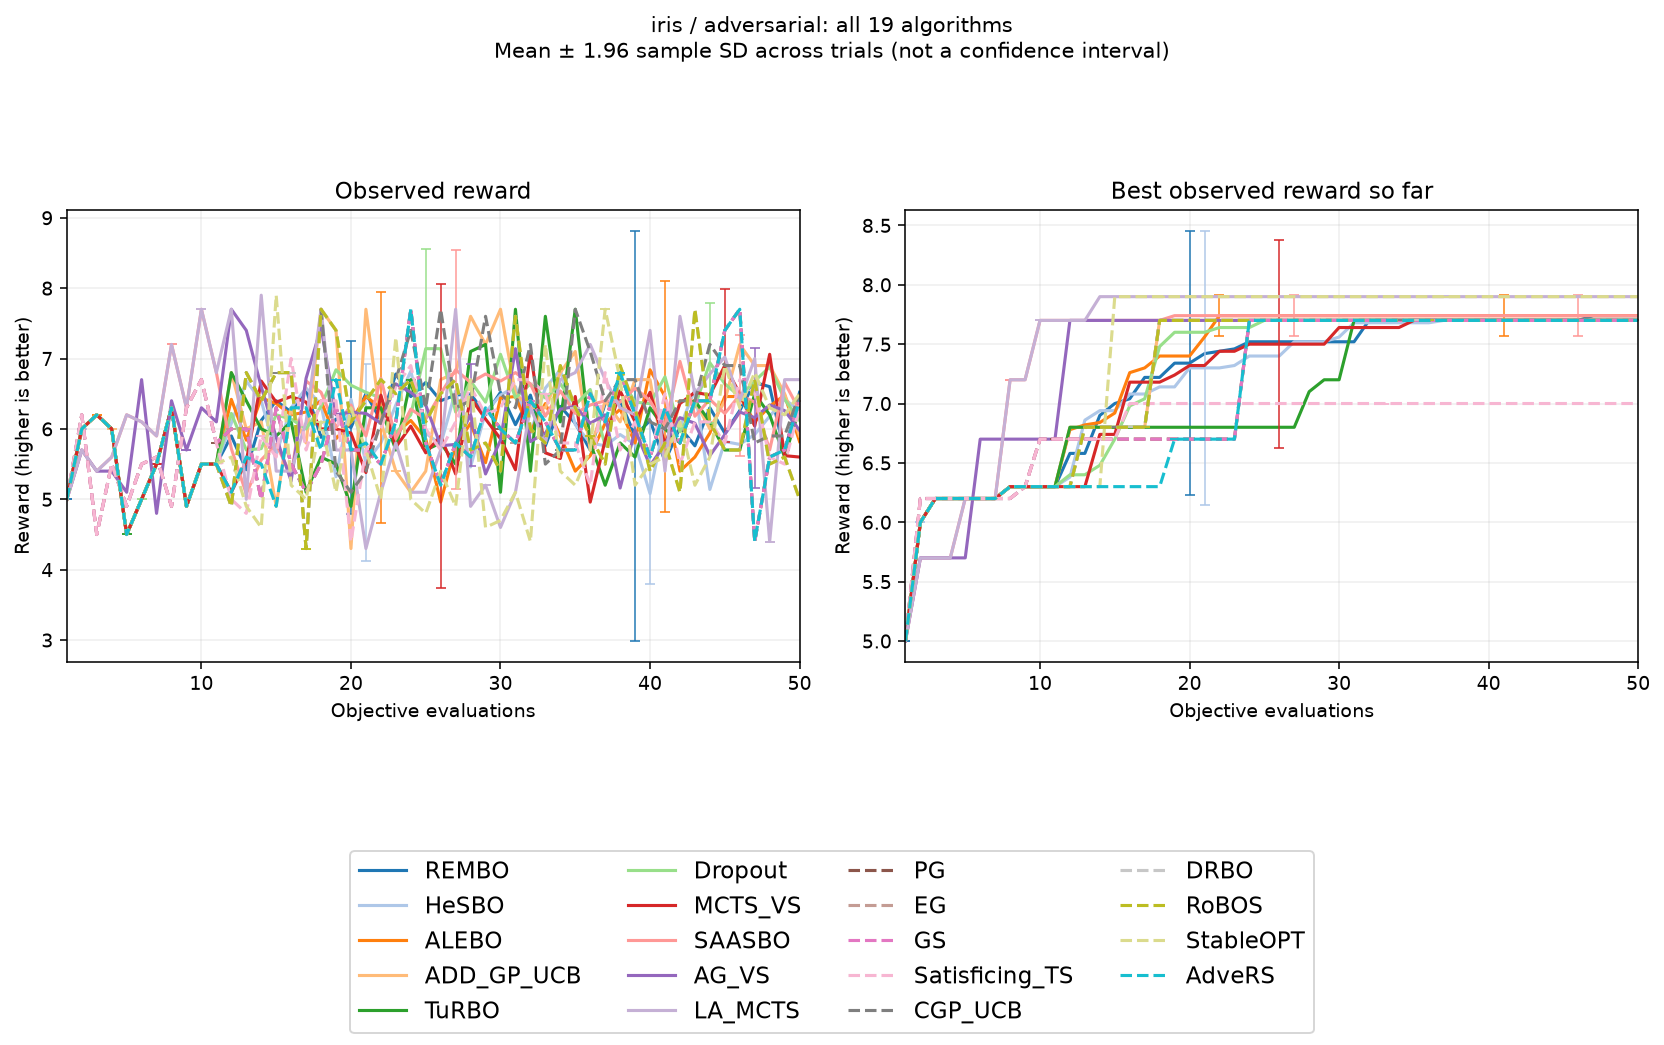

In [ ]:
import basat

seed = basat.set_seed(213, threads=1)
data_path = basat.find_path("data/adversarial/iris_bandit.csv")
loaded = basat.load_dataset(data_path, environment="adversarial")
print(loaded.preview(rows=3))
bounds = loaded.bounds
run_directory = basat.new_run_directory('results/last_guide/real_adversarial_agvs_aistats2027_v1')

# Fresh, fully explicit configurations for adversarial observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=4.0,
    initial_points=11,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=4.0,
    acquisition_optimizer=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=11,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=4.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=min(reduced_dimension, dimension - 1),
    sequence_length=2,
    split_groups=min(reduced_dimension + 1, dimension),
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed + 8),
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=11,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=4.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=11,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=4.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=11,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=4.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=11,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=2.0,
    distance=basat.L2Distance(),
    beta=4.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=4.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.AdversarialEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    attack=loaded.attack,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="iris / adversarial: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

# 3. Early Stopping

The eight preceding main comparisons used only a 50-evaluation cap. Here we
explicitly enable other stopping mechanisms. `make_stopping()` returns fresh
rule instances because patience tracks history. A multi-algorithm Experiment
clones the supplied rule for each child; progress in one method cannot stop
another. Each example below is independent.

| Rule | Meaning |
|---|---|
| MaximumEvaluationsStoppingRule | Stop after the allowed number of evaluated actions, counting initialization |
| MaximumRoundsStoppingRule | Limit ask/tell rounds; a batch can contain several evaluations |
| MaximumTimeStoppingRule | Check elapsed time between complete rounds; does not interrupt an optimizer |
| TargetValueStoppingRule | Stop when the best observed reward reaches a target |
| NoImprovementStoppingRule | Stop after patience rounds without improvement exceeding min_delta, after min_rounds |
| any_of / all_of | Compose conditions; any condition versus every condition |

`run(max_evaluations=50)` remains a separate hard safety cap. If a full batch
would exceed the remaining budget, the runner stops before that batch rather
than changing its acquisition semantics. For batch size 3, a cap of 50 can
therefore end at 48 evaluations. Rule checks occur at completed-round boundaries.
No-improvement and target rules concern observed rewards; noise can trigger
them without finding the latent optimum. AG_VS follows the supplied source with posterior stopping disabled;
leave `stopping_threshold` and `stopping_delta` as None. Its
`stagnation_patience` causes internal reinitialization, not experiment termination.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/early_patience/run_49k90o_1/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO / patience | [27, 25, 33, 37, 33] | -0.00012339228 | 0
AG_VS / patience | [39, 24, 32, 32, 20] | -0.00057300596 | 0
Total recorded evaluations: 302; failed trials: 0

Recorded stopping reasons by trial:
TuRBO / patience: ['any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement']
AG_VS / patience: ['any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement']

Recorded warnings (deduplicated per algorithm):
AG_VS / patience: BasatNumericalWarning: Basat numerical event during GP hyperparameter fitting (training-covariance Cholesky): Negative variance values detected. This is likely due to numerical ins

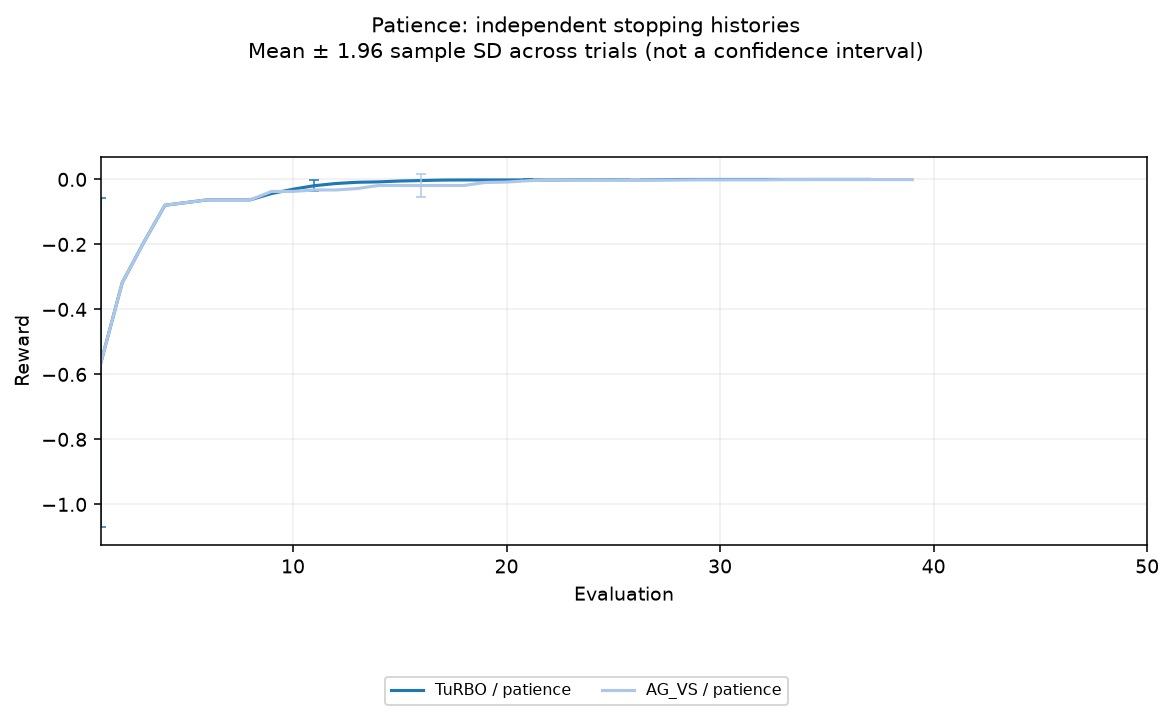

In [ ]:
import basat

seed = basat.set_seed(310, threads=1)
run_directory = basat.new_run_directory('results/last_guide/early_patience_agvs_aistats2027_v1')
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.25) ** 2 for x in values)

def make_stopping():
    return basat.any_of(
        basat.MaximumEvaluationsStoppingRule(50),
        basat.NoImprovementStoppingRule(
            10, min_rounds=20, min_delta=0.001,
        ),
    )

algorithms = {
    "TuRBO / patience": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
    "AG_VS / patience": basat.AG_VS(
        bounds=bounds, config=basat.AG_VSConfig(
            effective_dimension=2,
            split_groups=3, initial_points=8, sequence_length=2,
            acquisition_restarts=2, acquisition_raw_samples=32, seed=seed,
            stopping_threshold=None, stopping_delta=None,
            acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed),
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, stopping_rule=make_stopping(),
    output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Patience: independent stopping histories",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "patience.png"),
)

Saved-result refresh (no optimization was executed).
Source: results/last_guide/early_composition/run_ls4_mgd8/result.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO | [12, 12, 12, 12, 12] | -0.022895036 | 0
Total recorded evaluations: 60; failed trials: 0

Recorded stopping reasons by trial:
TuRBO: ['any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value']

Saved results: results/last_guide/early_composition/run_ls4_mgd8


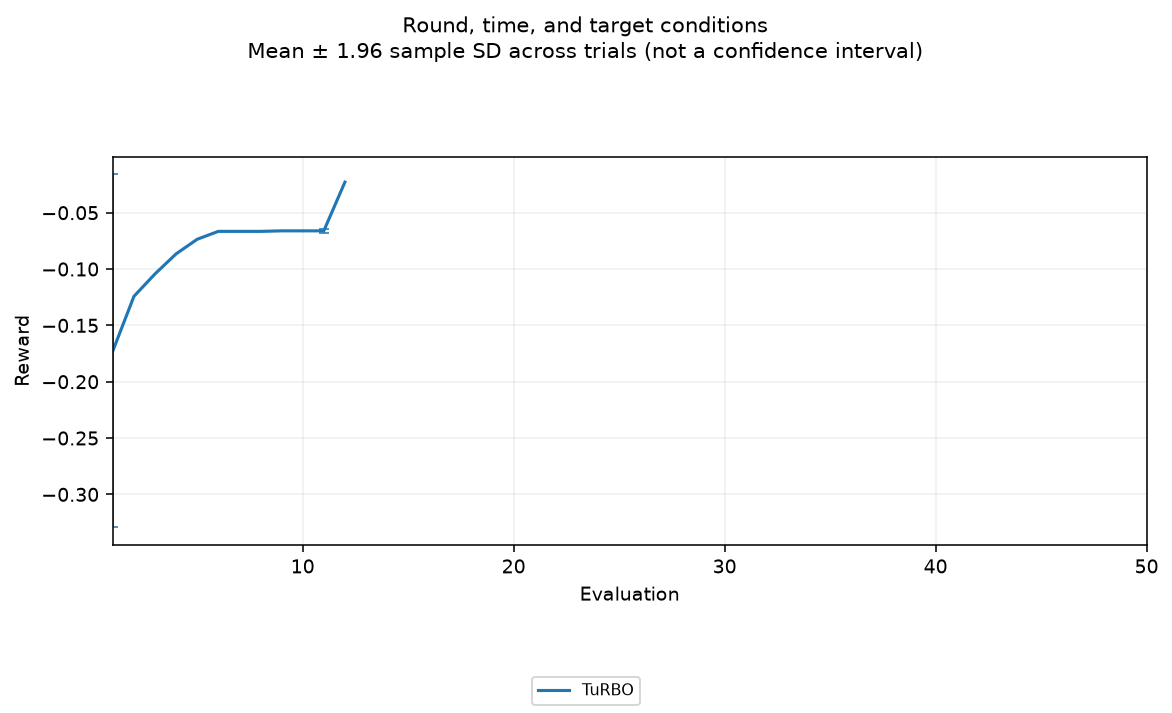

In [ ]:
import basat

seed = basat.set_seed(311, threads=1)
run_directory = basat.new_run_directory("results/last_guide/early_composition")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.5) ** 2 for x in values)

def make_stopping():
    return basat.any_of(
        basat.MaximumEvaluationsStoppingRule(50),
        basat.MaximumRoundsStoppingRule(35),
        basat.MaximumTimeStoppingRule(20.0),
        basat.all_of(
            basat.MaximumRoundsStoppingRule(12),
            basat.TargetValueStoppingRule(-0.05, maximize=True),
        ),
    )

algorithm = basat.TuRBO(
    bounds=bounds,
    config=basat.TuRBOConfig(
        initial_points=8, candidate_count=128,
        acquisition=basat.AcquisitionConfig(name="EI", xi=0.0, seed=seed),
        seed=seed,
    ), dtype="float64",
)
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithm, stopping_rule=make_stopping(),
    output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False)
print(experiment.summary())
print("Triggered conditions by trial:", [
    trial.stopping_decision for trial in experiment.trial_experiments
])
figure = basat.plot(
    experiment, kind="incumbent", title="Round, time, and target conditions",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "conditions.png"),
)

## Accuracy and interpretation of the measured results

Every large experiment reports warnings, failed contracts, actual evaluation
counts, and captured output. A common best-observed-reward trace is useful for
inspecting execution; it is not the same as every method's mathematical
objective. Contextual rewards depend on context. DRBO optimizes a worst-case
distributional value; StableOPT uses robust confidence bounds. A high noisy
observation alone does not establish robustness or global convergence.

Internal zero-context, point-mass-distribution and zero-perturbation defaults
are interoperability extensions. The original papers do not claim that these
choices recover native contextual, distributional or adversarial performance
in every environment. The environment still owns action evaluation and reward
feedback. Warnings identify the assumptions changed for execution; a curve
obtained under an adaptation must be interpreted under that adaptation.

The numerical audit found and fixed a DRBO local-search defect: an accepted
solver endpoint could be worse than the already-scored start, and flat
surfaces could make Powell drift toward a boundary. After successful solver
certification, the implementation now re-certifies and retains the start
unless refinement improves it beyond tolerance. All-failed solver cases still
raise. Focused tests cover worse endpoints, plateaus, and certification.

ALEBO's constrained acquisition optimizer could reject every local endpoint
despite having usable feasible candidates. A reproduced failure after 43
evaluations had SLSQP reporting success with constraint residuals of
3.24e-9 and 2.18e-7, above the configured 1e-9 feasibility tolerance. It now
screens the feasible candidate pool, refines its best starts with analytic
gradients when available, and independently verifies each endpoint. It
retains the best finite feasible candidate when refinement cannot improve
it; refinement diagnostics remain visible as warnings. Feasible screening
and constrained gradient refinement follow the
[official Ax ALEBO acquisition optimizer](https://github.com/facebook/Ax/blob/0.1.17/ax/models/torch/alebo.py#L470-L526)
and the [paper's constrained search domain](https://proceedings.neurips.cc/paper_files/paper/2020/file/10fb6cfa4c990d2bad5ddef4f70e8ba2-Paper.pdf).
The correction preserves the polytope and metric-inference model; it does
not relax feasibility or establish global acquisition optimality. Targeted
tests cover infeasible and worse local endpoints. The failing checkpoint
subsequently continued to 50 evaluations, and a fresh five-trial check
completed all five 50-evaluation runs with feasible actions.

This ALEBO correction concerns acquisition search only. The existing option
named `metric_inference="laplace"` records fixed-scale Gaussian perturbations
of fitted lower-factor parameters; it does not derive a Laplace covariance
from the posterior Hessian. Acquisition decisions still use the fitted GP,
rather than averaging over those recorded metric samples. The displayed
results therefore do not establish equivalence to the paper's integrated
metric inference. That separate modeling limitation remains explicit.

Checkpoint checks compare resumed actions and rewards with uninterrupted
runs, including independent trial random states and an interruption after
an environment measurement was committed but before algorithm feedback.
Restoring the GoodAction family's GP warm start and fitting cadence prevents
continuation from silently following a different numerical path. Immutable
setting mismatches and corrupt checkpoints are rejected before replacing
saved aggregate results. These checks concern Basat's state; external
simulators and side-effecting objectives need their own durable state.

A separate bounded resume audit covered all 19 methods in their native
environments with two seeds each. It checkpointed after each method's
initial design (8-11 evaluations) and continued through two model-based
choices: resumed actions and rewards
matched uninterrupted runs exactly in this audit. Its records are retained
in `results/resume_catalog/validation.json`. This small continuation check
complements the five-trial guide experiments; it is not a claim of exact
reproducibility across every device, dependency version or external system.

The frozen implementation passed 694 automated tests, Ruff checks and Mypy
checks. The built wheel was checked against all 72 library source files and
contains no datasets. This evidence establishes the checked behavior and
packaging scope, rather than an exhaustive proof of every possible setting.

The audit checked DRBO's max-min expected UCB, StableOPT's UCB/LCB ordering,
and CGP_UCB's joint action-context predictions against their primary sources:
[DRBO](https://proceedings.mlr.press/v108/kirschner20a/kirschner20a.pdf),
[StableOPT](https://arxiv.org/html/1810.10775v2), and
[CGP_UCB](https://proceedings.neurips.cc/paper/2011/file/f3f1b7fc5a8779a9e618e1f23a7b7860-Paper.pdf).
[SAASBO](https://proceedings.mlr.press/v161/eriksson21a.html) uses genuine NUTS
inference here, but the short displayed chains do not establish convergence.

A warning such as “NUTS reported 4 divergent transitions” concerns four
numerical integration trajectories in that GP fit, not four failed objective
evaluations. A later warning reporting one divergence belongs to a later fit.
Finite posterior draws can still be biased. `diagnostic_policy="warn"` retains
usable draws and continues with source guarantees invalidated;
`diagnostic_policy="raise", allow_divergences=False` rejects the fit instead.
The line in `experiment.py` identifies where the warning is surfaced.

The main SAASBO configurations expose `target_accept_prob=0.8`. To investigate
divergences, edit it to `0.95` and increase `warmup_steps` (for example 512).
Larger `posterior_samples` and multiple `num_chains` can improve assessment
of ESS and R-hat, but extra samples alone do not cure divergences. These
changes cost time and do not guarantee reliable inference. Do not suppress
warnings to claim convergence. See the
[Stan NUTS diagnostic guidance](https://mc-stan.org/docs/2_39/cmdstan-guide/diagnose_utility.html).

For `AcquisitionConfig`, CGP_UCB and DRBO, UCB is mean + sqrt(beta) *
standard deviation; a paper using
coefficient b * standard deviation needs beta=b*b for a numeric match.
MCTS_VS uses its separate `acquisition_beta` as a direct multiplier.

AG_VS now follows the supplied AISTATS2027 anonymous source, including
EI with xi=1e-4 and at least effective_dimension+1 split groups. The saved
outputs in Sections 1–4 predate this correction. Their updated example code
uses fresh output directories; rerun it to measure the corrected algorithm.
Finite runs and targeted checks do not prove every possible configuration.
Numerical negative-variance warnings can arise from cancellation or ill-conditioned
covariance matrices. Finite precision, variance floors, jitter and explicit
fit-failure diagnostics remain visible; a warning is not hidden by the guide.

# 4. Different Settings Examples

These shorter examples show selected changes without repeating all optional
fields. Omitted values use the public configuration class defaults. Each block
still defines its own input, algorithms, environment, and output directory.
Each run goes through `Experiment.run` and stays within 50 evaluations.

## Defaults and a list of algorithms

This example passes a Python list of algorithm instances. `TuRBOConfig`
uses its defaults except for the displayed seed: initialization and candidate
count are resolved from dimension, and its default acquisition is Thompson
sampling. The printed config shows None for dimension-resolved defaults.
Required AG_VS effective dimension remains an explicit scientific choice.
Passing just `algorithms[0]` instead of the list uses the same runner for one
algorithm. There is no second comparison interface and no profile variable.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/defaults/run_lnhzix6f/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO | [50, 50, 50, 50, 50] | -4.0088652e-05 | 0
AG_VS | [50, 50, 50, 50, 50] | -0.0013197799 | 0
Total recorded evaluations: 500; failed trials: 0

Recorded stopping reasons by trial:
TuRBO: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
AG_VS: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Recorded warnings (deduplicated per algorithm):
TuRBO: BasatJitterWarning: Basat added diagonal jitter=1.0e-06 during GP posterior sampling because the covariance matrix was not positive definite.
AG_VS: BasatNumericalWarning: Basat numerical event during GP hyperparameter fitting (training-covariance Cholesky): Neg

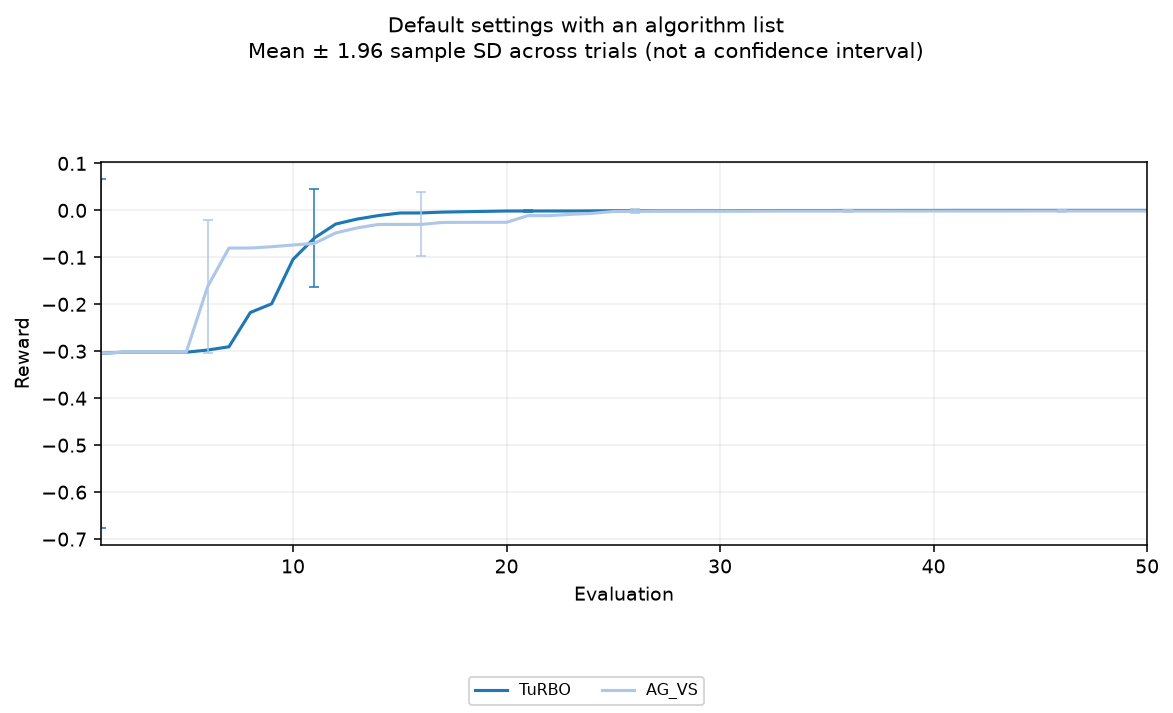

In [ ]:
import basat

seed = basat.set_seed(410, threads=1)
run_directory = basat.new_run_directory('results/last_guide/defaults_agvs_aistats2027_v1')
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.3) ** 2 for x in values)

algorithms = [
    basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(seed=seed), dtype="float64",
    ),
    basat.AG_VS(
        bounds=bounds,
        config=basat.AG_VSConfig(effective_dimension=2, split_groups=3, seed=seed, acquisition=basat.AcquisitionConfig(name="EI", xi=1e-4, seed=seed)),
        dtype="float64",
    ),
]
print("TuRBO defaults:", algorithms[0].config)
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Default settings with an algorithm list",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "defaults.png"),
)

## Acquisition settings: UCB beta and EI offset

The three named configurations below all use TuRBO, with explicit EI/UCB
extensions. UCB beta=9 has uncertainty multiplier 3; beta=3 has multiplier
sqrt(3). `xi=0.01` changes EI's improvement threshold. These are comparisons
of acquisition settings within the displayed trust-region implementation,
not three separate algorithm families.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/acquisitions/run_2zxmczxf/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
UCB beta=3 | [50, 50, 50, 50, 50] | -1.738164e-05 | 0
UCB beta=9 | [50, 50, 50, 50, 50] | -3.4245462e-05 | 0
EI xi=0.01 | [50, 50, 50, 50, 50] | -3.6684806e-05 | 0
Total recorded evaluations: 750; failed trials: 0

Recorded stopping reasons by trial:
UCB beta=3: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
UCB beta=9: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
EI xi=0.01: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Saved results: results/last_guide/acquisitions/run_2zxmczxf


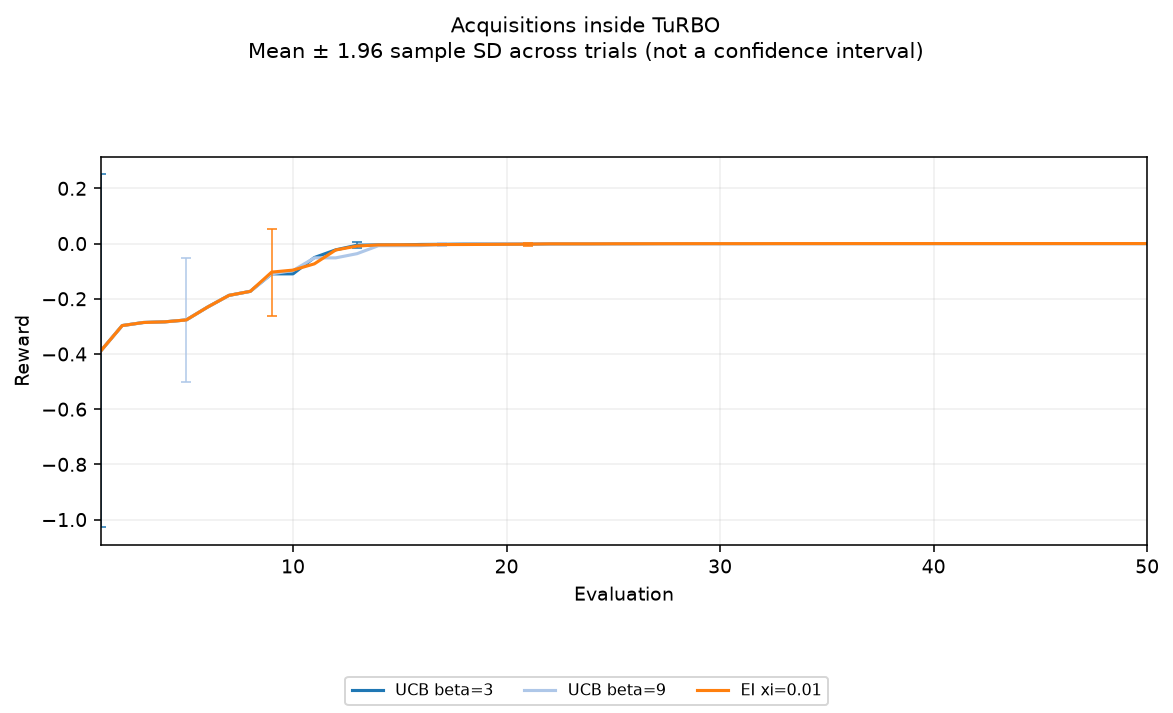

In [ ]:
import basat

seed = basat.set_seed(411, threads=1)
run_directory = basat.new_run_directory("results/last_guide/acquisitions")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.4) ** 2 for x in values)

algorithms = {
    "UCB beta=3": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            acquisition=basat.AcquisitionConfig(name="UCB", beta=3.0, seed=seed),
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
    "UCB beta=9": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            acquisition=basat.AcquisitionConfig(name="UCB", beta=9.0, seed=seed),
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
    "EI xi=0.01": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            acquisition=basat.AcquisitionConfig(name="EI", xi=0.01, seed=seed),
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Acquisitions inside TuRBO",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "acquisitions.png"),
)

## GP kernels inside a contextual real-data experiment

Here the kernel changes the surrogate used to choose measured Wine rows.
We compare three CGP_UCB configurations on the same dataset and seed, with
the same fixed beta and optimizer budgets. The context kernel operates on
one-hot cultivar, while the action kernel operates on the three scaled
descriptors. These are optimization runs, not drawings of kernel functions.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_kernels/run_azy89pl6/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
CGP_UCB / RBF | [50, 50, 50, 50, 50] | 1586.8 | 0
CGP_UCB / Matern32 | [50, 50, 50, 50, 50] | 1586.8 | 0
CGP_UCB / Matern52 | [50, 50, 50, 50, 50] | 1560 | 0
Total recorded evaluations: 750; failed trials: 0

Recorded stopping reasons by trial:
CGP_UCB / RBF: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
CGP_UCB / Matern32: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
CGP_UCB / Matern52: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Recorded warnings (deduplicated per algorithm):
CGP_UCB / RBF: BasatNumericalWarning: Basat numer

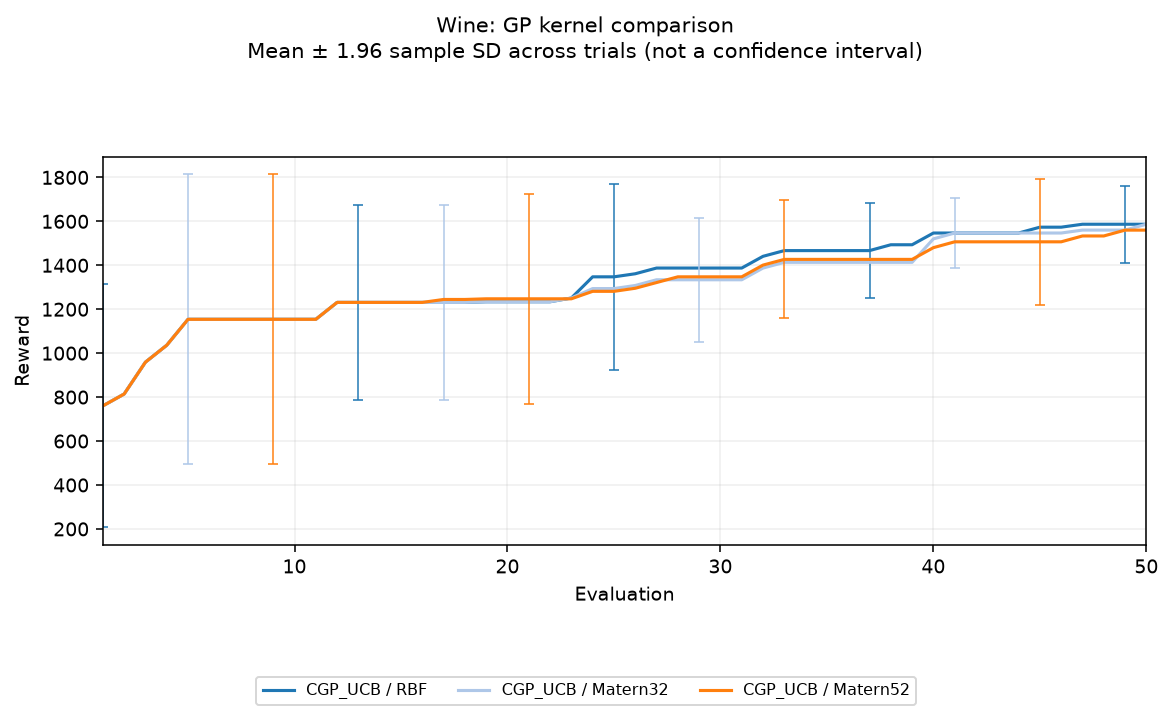

In [ ]:
import basat

seed = basat.set_seed(412, threads=1)
run_directory = basat.new_run_directory("results/last_guide/real_kernels")
loaded = basat.load_dataset(
    basat.find_path("data/contextual/wine_bandit.csv"), environment="contextual",
)
bounds = loaded.bounds
optimizer = basat.AcquisitionOptimizerSpec(
    raw_samples=32, restarts=2, maxiter=50, fit_maxiter=50,
)
algorithms = {
    "CGP_UCB / RBF": basat.CGP_UCB(
        bounds=bounds, config=basat.CGPUCBConfig(
            action_bounds=bounds, action_kernel=basat.KernelConfig(name="rbf"),
            context_kernel=basat.KernelConfig(name="rbf"), beta=3.0,
            initial_points=8, acquisition_optimizer=optimizer, seed=seed,
        ), dtype="float64",
    ),
    "CGP_UCB / Matern32": basat.CGP_UCB(
        bounds=bounds, config=basat.CGPUCBConfig(
            action_bounds=bounds, action_kernel=basat.KernelConfig(name="matern32"),
            context_kernel=basat.KernelConfig(name="rbf"), beta=3.0,
            initial_points=8, acquisition_optimizer=optimizer, seed=seed,
        ), dtype="float64",
    ),
    "CGP_UCB / Matern52": basat.CGP_UCB(
        bounds=bounds, config=basat.CGPUCBConfig(
            action_bounds=bounds, action_kernel=basat.KernelConfig(name="matern52"),
            context_kernel=basat.KernelConfig(name="rbf"), beta=3.0,
            initial_points=8, acquisition_optimizer=optimizer, seed=seed,
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.ContextualEnvironment(
        bounds=bounds, dataset=loaded.dataset, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="incumbent", title="Wine: GP kernel comparison",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "kernels.png"),
)

## Sampling and batches

Sampling overrides are attached to the experiment by algorithm label.
The two TuRBO instances below compare Sobol and uniform sampling. Both
request batches of 2, so 25 completed rounds consume 50 evaluations.
`batch_size=2` uses the method's independent batch behavior. For a supported
joint Monte Carlo acquisition, use `batch_size=None, q_batch=2` instead;
the third configuration demonstrates joint EI. The budget applies to actions,
not rounds. Change a sampler only if that method supports the phase.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/sampling_batches/run_3q5zetrd/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
Sobol / batch2 | [50, 50, 50, 50, 50] | -5.3890733e-05 | 0
Uniform / batch2 | [50, 50, 50, 50, 50] | -0.019207686 | 0
Joint EI / q2 | [50, 50, 50, 50, 50] | -4.6761665e-06 | 0
Total recorded evaluations: 750; failed trials: 0

Recorded stopping reasons by trial:
Sobol / batch2: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
Uniform / batch2: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
Joint EI / q2: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Recorded warnings (deduplicated per algorithm):
Sobol / batch2: BasatJitterWarnin

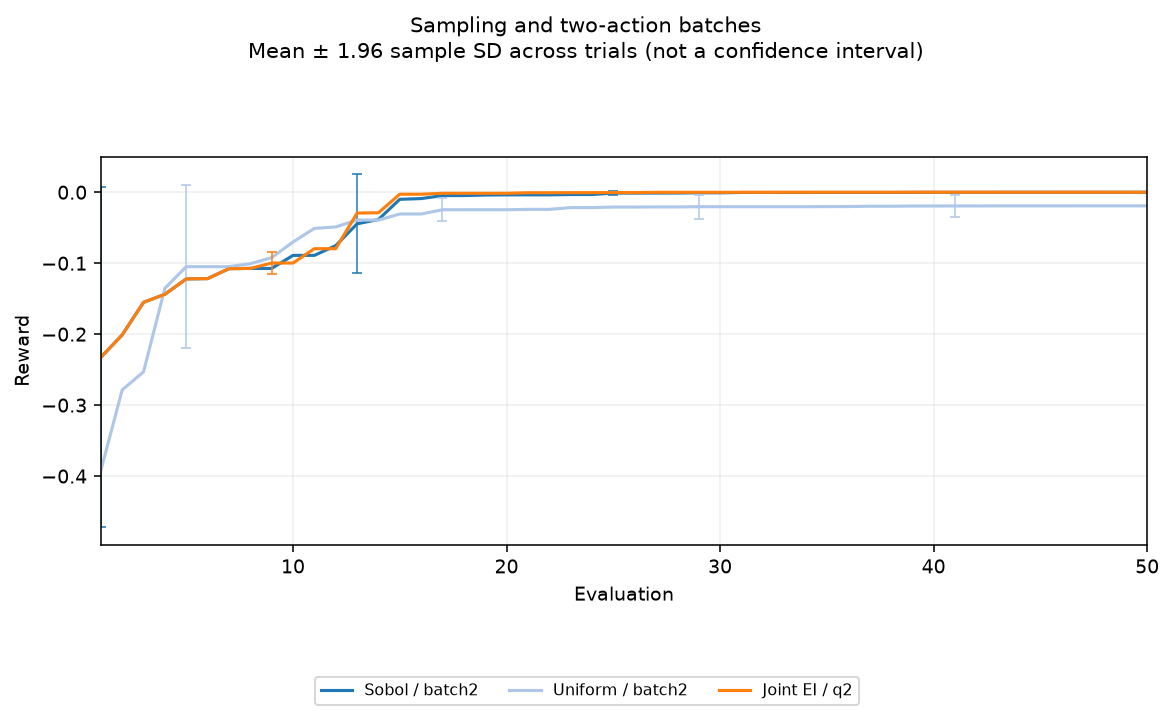

In [ ]:
import basat

seed = basat.set_seed(413, threads=1)
run_directory = basat.new_run_directory("results/last_guide/sampling_batches")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.6) ** 2 for x in values)

algorithms = {
    "Sobol / batch2": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, batch_size=2, seed=seed,
        ), dtype="float64",
    ),
    "Uniform / batch2": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, batch_size=2, seed=seed,
        ), dtype="float64",
    ),
    "Joint EI / q2": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, batch_size=None, q_batch=2,
            acquisition=basat.AcquisitionConfig(
                name="EI", mc_samples=64, seed=seed,
            ), seed=seed,
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
    initial_points_sampling_method={
        "Sobol / batch2": "sobol", "Uniform / batch2": "uniform",
        "Joint EI / q2": "sobol",
    },
    acquisition_sampling_method={
        "Sobol / batch2": "sobol", "Uniform / batch2": "uniform",
        "Joint EI / q2": "sobol",
    },
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Sampling and two-action batches",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "batches.png"),
)

## Save, resume, and explicit display

A single run writes into its chosen directory. A collection adds readable
`algorithms/NN-label/` subdirectories and a combined `results.json`. Each
method's settings, observations, diagnostics, and checkpoints remain separate.
The runner saves final records even if a periodic `save_every` checkpoint is
not due. Repeated experiments add `trials/trial-001/` through
`trials/trial-005/`; each trial contains its own method directories.
Resuming uses total ceilings: resuming 10 evaluations with a cap of 50 adds
at most 40 per trial. A fresh object must match the saved configuration.

`plot=False` disables the automatic progress plot. `plot=True, show=False`
creates it without displaying it. `show=True` displays it on a capable backend.
None of these settings change rewards or warning output. `basat.plot` controls
title, axes, limits, legends, file saving, and display; assign its result to
avoid notebook final-expression display when show=False. `basat.show` can
display the retained plot explicitly.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/resume/run_4gsf9_g4/result.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO | [50, 50, 50, 50, 50] | -1.8840406e-05 | 0
Total recorded evaluations: 250; failed trials: 0

Recorded stopping reasons by trial:
TuRBO: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
This is the final saved state after continuation. The earlier 10-evaluation stage was not rerun.

Recorded warnings (deduplicated per algorithm):
TuRBO: BasatJitterWarning: Basat added diagonal jitter=1.0e-06 during GP posterior sampling because the covariance matrix was not positive definite.

Saved results: results/last_guide/resume/run_4gsf9_g4


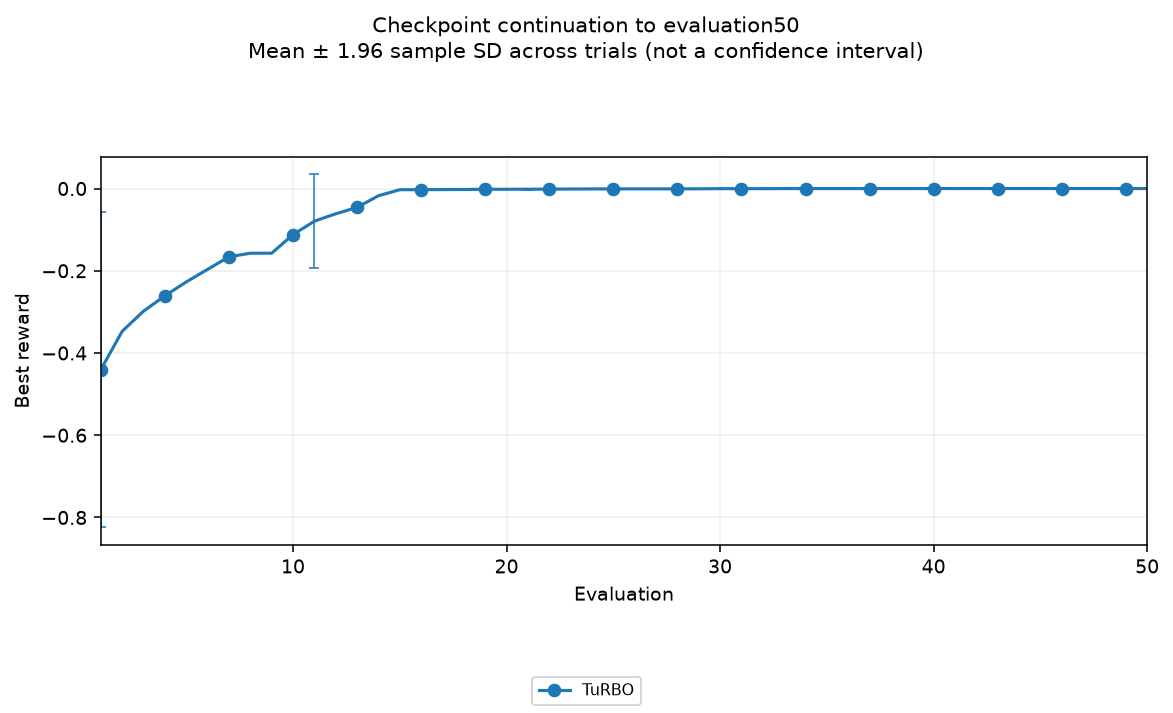

In [ ]:
import basat

seed = basat.set_seed(414, threads=1)
run_directory = basat.new_run_directory("results/last_guide/resume")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.45) ** 2 for x in values)

def make_experiment(resume):
    return basat.Experiment(
        environment=basat.StochasticEnvironment(
            bounds=bounds, function=objective, dtype="float64", seed=seed,
        ),
        algorithm=basat.TuRBO(
            bounds=bounds, config=basat.TuRBOConfig(
                initial_points=8, candidate_count=128, seed=seed,
            ), dtype="float64",
        ), output_directory=run_directory, resume=resume, save_every=5,
    )

first = make_experiment(False)
first_result = first.run(trials=5, max_evaluations=10, plot=True)
resumed = make_experiment(True)
resumed_result = resumed.run(trials=5, max_evaluations=50, plot=True, show=False)
print("Before:", first_result.evaluations, "After:", resumed_result.evaluations)
print(resumed.summary())
figure = basat.plot(
    resumed, kind="incumbent", title="Checkpoint continuation to evaluation50",
    xlabel="Evaluation", ylabel="Best reward", xlim=(1, 50),
    grid=True, legend=True, legend_columns=1, marker="o",
    save_path=basat.join_path(run_directory, "resumed.png"), show=False,
)
print("show=False retained the plot. Display it explicitly next:")
basat.show(figure)

# 5. Reproducibility

## 5.1 Hartmann6_300: Song et al. (2022)

In [ ]:
import basat

OUTPUT_DIRECTORY = "./results/reproducibility/hartmann6_300_song2022_sampling_v3"
SEEDS = (2021, 2022, 2023, 2024, 2025)
NAMES = (
    "MCTS-VS-BO",
    "MCTS-VS-TuRBO",
    "TuRBO",
    "LA-MCTS-TuRBO",
    "SAASBO",
    "ALEBO",
    "HeSBO",
    "AG-VS-BO",
    "AG-VS-TuRBO",
)
BUDGETS = {
    "MCTS-VS-BO": 600,
    "MCTS-VS-TuRBO": 600,
    "TuRBO": 600,
    "LA-MCTS-TuRBO": 600,
    "SAASBO": 200,
    "ALEBO": 200,
    "HeSBO": 600,
    "AG-VS-BO": 600,
    "AG-VS-TuRBO": 600,
}
COLORS = {
    "MCTS-VS-BO": "#DC143C",
    "MCTS-VS-TuRBO": "#4169E1",
    "TuRBO": "#ABC5E7",
    "LA-MCTS-TuRBO": "#00BEBE",
    "SAASBO": "#FF9933",
    "ALEBO": "#8D5447",
    "HeSBO": "#7C8806",
    "AG-VS-BO": "#8A2BE2",
    "AG-VS-TuRBO": "#228B22",
}
BOUNDS = basat.Bounds(lower=basat.array([0.0] * 300), upper=basat.array([1.0] * 300))


def hartmann6_300(x):
    alpha = x.new_tensor([1., 1.2, 3., 3.2])
    a = x.new_tensor([
        [10., 3., 17., 3.5, 1.7, 8.], [.05, 10., 17., .1, 8., 14.],
        [3., 3.5, 1.7, 10., 17., 8.], [17., 8., .05, 10., .1, 14.]])
    p = 1e-4 * x.new_tensor([
        [1312., 1696., 5569., 124., 8283., 5886.],
        [2329., 4135., 8307., 3736., 1004., 9991.],
        [2348., 1451., 3522., 2883., 3047., 6650.],
        [4047., 8828., 8732., 5743., 1091., 381.]])
    return (alpha * (-(a * (x[:6] - p).square()).sum(-1)).exp()).sum()


optimum = basat.array([0.20169, 0.150011, 0.476874, 0.275332, 0.311652, 0.6573] + [0.0] * 294)
assert abs(float(hartmann6_300(optimum)) - 3.322368011391339) < 1e-07
inactive_check = optimum.clone()
inactive_check[6:] = 1.0
assert float(hartmann6_300(inactive_check)) == float(hartmann6_300(optimum))


def make_algorithm(name, seed):
    common = dict(
        bounds=BOUNDS,
        maximize=True,
        dtype="float64",
        device="cpu",
        plot=False,
        verbose=False,
        verbose_setting=False,
        verbose_iter_by_iter=False,
    )
    ei = basat.AcquisitionConfig(name="EI", beta=2.0, xi=0.0, mc_samples=512, seed=seed)
    if name == "TuRBO":
        return basat.TuRBO(
            **common,
            config=basat.TuRBOConfig(
                source_protocol="mcts_vs_2022",
                initial_points=20,
                initial_points_sampling_method="paper",
                batch_size=10,
                acquisition="TS",
                candidate_count=5000,
                gp_training_steps=50,
                length_init=0.8,
                length_min=2 ** (-7),
                length_max=1.6,
                success_tolerance=3,
                failure_tolerance=30,
                perturbation_cap=20.0,
                noisy_center="best_observation",
                seed=seed,
            ),
        )
    if name in ("MCTS-VS-BO", "MCTS-VS-TuRBO"):
        return basat.MCTS_VS(
            **common,
            config=basat.MCTSVSConfig(
                source_protocol="mcts_vs_2022",
                Nv=2,
                Ns=3,
                archive_size=20,
                initial_points=12,
                initial_points_sampling_method="paper",
                bad_count_limit=5,
                split_threshold=3,
                exploration_constant=0.1,
                inner_optimizer="bo" if name == "MCTS-VS-BO" else "turbo",
                inner_max_evaluations=50,
                candidate_pool_size=1024,
                kernel_lengthscale=1.0,
                gp_maxiter=50,
                batch_size=1,
                seed=seed,
            ),
        )
    if name == "LA-MCTS-TuRBO":
        return basat.LA_MCTS(
            **common,
            config=basat.LAMCTSConfig(
                source_protocol="mcts_vs_2022",
                initial_points=20,
                initial_points_sampling_method="paper",
                exploration_constant=0.1,
                split_threshold=21,
                min_child_size=1,
                max_depth=500,
                classifier="svm_rbf",
                classifier_gamma="auto",
                local_sampler="turbo",
                inner_max_evaluations=50,
                candidate_pool_size=1024,
                gp_maxiter=50,
                batch_size=1,
                seed=seed,
            ),
        )
    if name == "SAASBO":
        return basat.SAASBO(
            **common,
            config=basat.SAASBOConfig(
                initial_points=10,
                initial_points_sampling_method="paper",
                shrinkage_scale=0.1,
                warmup_steps=512,
                posterior_samples=256,
                thinning=16,
                num_chains=1,
                max_tree_depth=6,
                acquisition="EI",
                source_protocol="mcts_vs_2022",
                inference_backend="numpyro",
                batch_size=1,
                seed=seed,
            ),
            diagnostic_policy="warn",
            jit_compile=False,
            mcmc_num_threads=1,
            release_inference_cache=True,
        )
    if name == "ALEBO":
        return basat.ALEBO(
            **common,
            config=basat.ALEBOConfig(
                embedding_dimension=6,
                source_protocol="ax_0_2_2",
                initial_points=10,
                initial_points_sampling_method="paper",
                acquisition=ei,
                metric_inference="laplace",
                metric_posterior_samples=25,
                fit_restarts=10,
                noise_variance=1e-07,
                raw_feasible_samples=1000,
                num_restarts=10,
                batch_size=1,
                seed=seed,
            ),
        )
    if name == "HeSBO":
        return basat.HeSBO(
            **common,
            config=basat.HeSBOConfig(
                embedding_dimension=6,
                initial_points=2,
                initial_points_sampling_method="paper",
                acquisition=ei,
                batch_size=1,
                seed=seed,
                source_protocol="ax_0_2_2",
            ),
        )
    if name in ("AG-VS-BO", "AG-VS-TuRBO"):
        return basat.AG_VS(
            **common,
            config=basat.AG_VSConfig(
                effective_dimension=6,
                sequence_length=2,
                split_groups=7,
                initial_points=12,
                initial_points_sampling_method="paper",
                acquisition=basat.AcquisitionConfig(
                    name="EI", beta=2.0, xi=0.0001, mc_samples=512, seed=seed
                ),
                stopping_threshold=None,
                stopping_delta=None,
                stagnation_patience=28,
                gp_fit_method="mle",
                gp_maxiter=None,
                acquisition_restarts=10,
                acquisition_raw_samples=1024,
                batch_size=3,
                q_batch=None,
                inner_optimizer="bo" if name == "AG-VS-BO" else "turbo",
                seed=seed,
            ),
        )
    raise ValueError(f"Unknown algorithm: {name}")


def json_config(value):
    if callable(value):
        return {"callable": value.__module__ + "." + value.__qualname__}
    if hasattr(value, "__dataclass_fields__"):
        return {key: json_config(getattr(value, key)) for key in value.__dataclass_fields__}
    if isinstance(value, dict):
        return {key: json_config(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_config(item) for item in value]
    return basat.to_list(value)


TURBO_DIRECTORY = "results/reproducibility/turbo_corrected_sampling_v3_klb84zz2"
AGVS_DIRECTORIES = {
    "AG-VS-BO": "results/reproducibility/hartmann6_300_agvs_aistats2027_v1",
    "AG-VS-TuRBO": "results/reproducibility/hartmann6_300_agvs_aistats2027_v3",
}
AGVS_REVISIONS = {"AG-VS-BO": "agvs-aistats2027-v1", "AG-VS-TuRBO": "agvs-aistats2027-v3"}
AGVS_DIRECTORY = "./results/reproducibility/hartmann6_300_agvs_aistats2027_v1"
ARCHIVED_DIRECTORY = "./results/reproducibility/hartmann6_300_song2022_paper_v2"
validated_agvs = set()
for name, directory in AGVS_DIRECTORIES.items():
    source_store = basat.ArtifactStore(directory)
    backend = "bo" if name == "AG-VS-BO" else "turbo"
    seen = False
    valid = (
        source_store.exists("protocol.json")
        and source_store.read_json("protocol.json").get("revision") == AGVS_REVISIONS[name]
    )
    for validation_seed in SEEDS:
        report_path = f"source_validation/{backend}-seed-{validation_seed}.json"
        if source_store.exists(report_path):
            seen = True
            report = source_store.read_json(report_path)
            measured_path = f"{name}/seed-{validation_seed}/trajectory.npz"
            source_path = f"source_validation/{backend}-seed-{validation_seed}.npz"
            valid = valid and (
                report.get("status") == "passed"
                and report.get("method") == name
                and (report.get("seed") == validation_seed)
                and (report.get("evaluations") == 600)
                and source_store.exists(measured_path)
                and source_store.exists(source_path)
                and (report.get("measured_trajectory_sha256") == source_store.sha256(measured_path))
                and (report.get("source_trajectory_sha256") == source_store.sha256(source_path))
                and (
                    report.get("archive_sha256")
                    == source_store.read_json("protocol.json").get("archive_sha256")
                )
            )
            if report.get("full_trajectory_match") is False:
                valid = False
    complete_cohort = all(
        (
            source_store.exists(f"{name}/seed-{s}/status.json")
            and source_store.read_json(f"{name}/seed-{s}/status.json").get("status") == "complete"
            for s in SEEDS
        )
    )
    if seen and valid and complete_cohort:
        validated_agvs.add(name)
runs = {name: [] for name in NAMES}
for seed in SEEDS:
    for name in NAMES:
        basat.set_seed(seed, threads=1)
        directory = (
            basat.join_path(AGVS_DIRECTORIES[name], name)
            if name.startswith("AG-VS")
            else TURBO_DIRECTORY
            if name == "TuRBO"
            else basat.join_path(ARCHIVED_DIRECTORY, name)
        )
        store = basat.ArtifactStore(directory)
        prefix = f"seed-{seed}"
        budget = BUDGETS[name]
        complete = (
            store.exists(prefix + "/status.json")
            and store.read_json(prefix + "/status.json").get("status") == "complete"
        )
        if not complete and (not name.startswith("AG-VS")):
            current_store = basat.ArtifactStore(basat.join_path(OUTPUT_DIRECTORY, name))
            if (
                current_store.exists(prefix + "/status.json")
                and current_store.read_json(prefix + "/status.json").get("status") == "complete"
            ):
                store, complete = (current_store, True)
        if complete:
            data = store.read_arrays(prefix + "/trajectory.npz")
            if data["actions"].shape[1:] != (300,) or len(data["reward"]) < budget:
                raise ValueError("Saved trajectory does not meet the declared benchmark budget.")
            expected = basat.array([hartmann6_300(x) for x in data["actions"]])
            if not bool((expected - data["reward"]).abs().le(1e-07).all()):
                raise ValueError("Saved rewards do not match the Hartmann objective.")
            if name.startswith("AG-VS"):
                saved = store.read_json(prefix + "/settings.json")
                config = saved.get("config", saved.get("configuration", saved))
                expected_config = json_config(make_algorithm(name, seed).config)
                if config != expected_config:
                    raise ValueError("Saved AG-VS configuration does not match this experiment.")
                revision = saved.get("protocol", {}).get("revision")
                if revision != AGVS_REVISIONS[name]:
                    raise ValueError("Saved AG-VS source revision differs from this experiment.")
                if (
                    name not in validated_agvs
                    and saved.get("execution_origin") != "fresh_guide_execution"
                ):
                    raise ValueError(
                        "Saved AG-VS results are not validated; select a fresh output directory."
                    )
            reward = data["reward"]
        else:
            store = basat.ArtifactStore(
                basat.join_path(
                    AGVS_DIRECTORIES[name] if name.startswith("AG-VS") else OUTPUT_DIRECTORY, name
                )
            )
            algorithm = make_algorithm(name, seed)
            settings = {
                "config": json_config(algorithm.config),
                "seed": seed,
                "nominal_evaluations": budget,
            }
            if name.startswith("AG-VS"):
                campaign_store = basat.ArtifactStore(AGVS_DIRECTORIES[name])
                if campaign_store.exists("protocol.json"):
                    protocol = campaign_store.read_json("protocol.json")
                    if protocol.get("revision") != AGVS_REVISIONS[name]:
                        raise ValueError("AG-VS protocol changed; select a fresh output directory.")
                else:
                    protocol = {"revision": AGVS_REVISIONS[name]}
                    campaign_store.write_json("protocol.json", protocol)
                settings["protocol"] = protocol
                settings["execution_origin"] = "fresh_guide_execution"
            if store.exists(prefix + "/settings.json"):
                saved = store.read_json(prefix + "/settings.json")
                saved_config = saved.get("config", saved.get("configuration", saved))
                if saved_config != settings["config"]:
                    raise ValueError(
                        "Saved configuration changed; select a fresh output directory."
                    )
            else:
                store.write_json(prefix + "/settings.json", settings)
            environment = basat.StochasticEnvironment(
                bounds=BOUNDS,
                function=hartmann6_300,
                noise_std=0.0,
                allow_repeated_actions=True,
                dtype="float64",
                device="cpu",
                seed=seed,
            )
            experiment = basat.Experiment(
                environment=environment,
                algorithm=algorithm,
                output_directory=store.path(prefix + "/checkpoint"),
                resume=True,
                save_every=10,
                checkpoint_policy="periodic",
                initial_sampling_method="paper",
                acquisition_sampling_method="paper",
            )
            result = experiment.run(
                max_rounds=None,
                max_evaluations=budget,
                budget_policy="finish_iteration",
                plot=False,
                show=False,
                progress=False,
            )
            if result.evaluations < budget:
                raise RuntimeError("The requested evaluation budget is incomplete.")
            if name.startswith("AG-VS") and (not algorithm.source_iteration_complete):
                raise RuntimeError("The requested source iteration is incomplete.")
            reward = algorithm.observed_values
            store.write_arrays(
                prefix + "/trajectory.npz", actions=algorithm.observed_actions, reward=reward
            )
            store.write_json(
                prefix + "/status.json",
                {
                    "status": "complete",
                    "actual_evaluations": result.evaluations,
                    "nominal_evaluations": budget,
                    "source_iteration_complete": algorithm.source_iteration_complete
                    if name.startswith("AG-VS")
                    else None,
                },
            )
        runs[name].append(reward[:budget])
publish_agvs = all((len(runs[name]) == len(SEEDS) for name in AGVS_DIRECTORIES))
series = {
    name + (" (additional)" if name.startswith("AG-VS") else ""): basat.PlotSeries.from_runs(
        values,
        transform="incumbent",
        maximize=True,
        uncertainty="sem",
        ddof=0,
        resample=512,
        smoothing="symmetric_ema",
        decay_steps=1.0,
        error_every=64,
        color=COLORS[name],
        linewidth=2.0,
        capsize=0.0,
    )
    for name, values in runs.items()
    if values and (not name.startswith("AG-VS") or publish_agvs)
}
figure = basat.plot_panels(
    [
        basat.PlotPanel(
            series,
            title="Hartmann6_300",
            xlabel="Number of evaluations",
            ylabel="Value",
            xlim=(0, 600),
            ylim=(0.0, 3.5),
            grid=False,
            legend_columns=2,
        )
    ],
    figsize=(11.0, 7.0),
    show=False,
    save_path=basat.join_path(AGVS_DIRECTORY, "guide_comparison.png"),
    dpi=200,
)


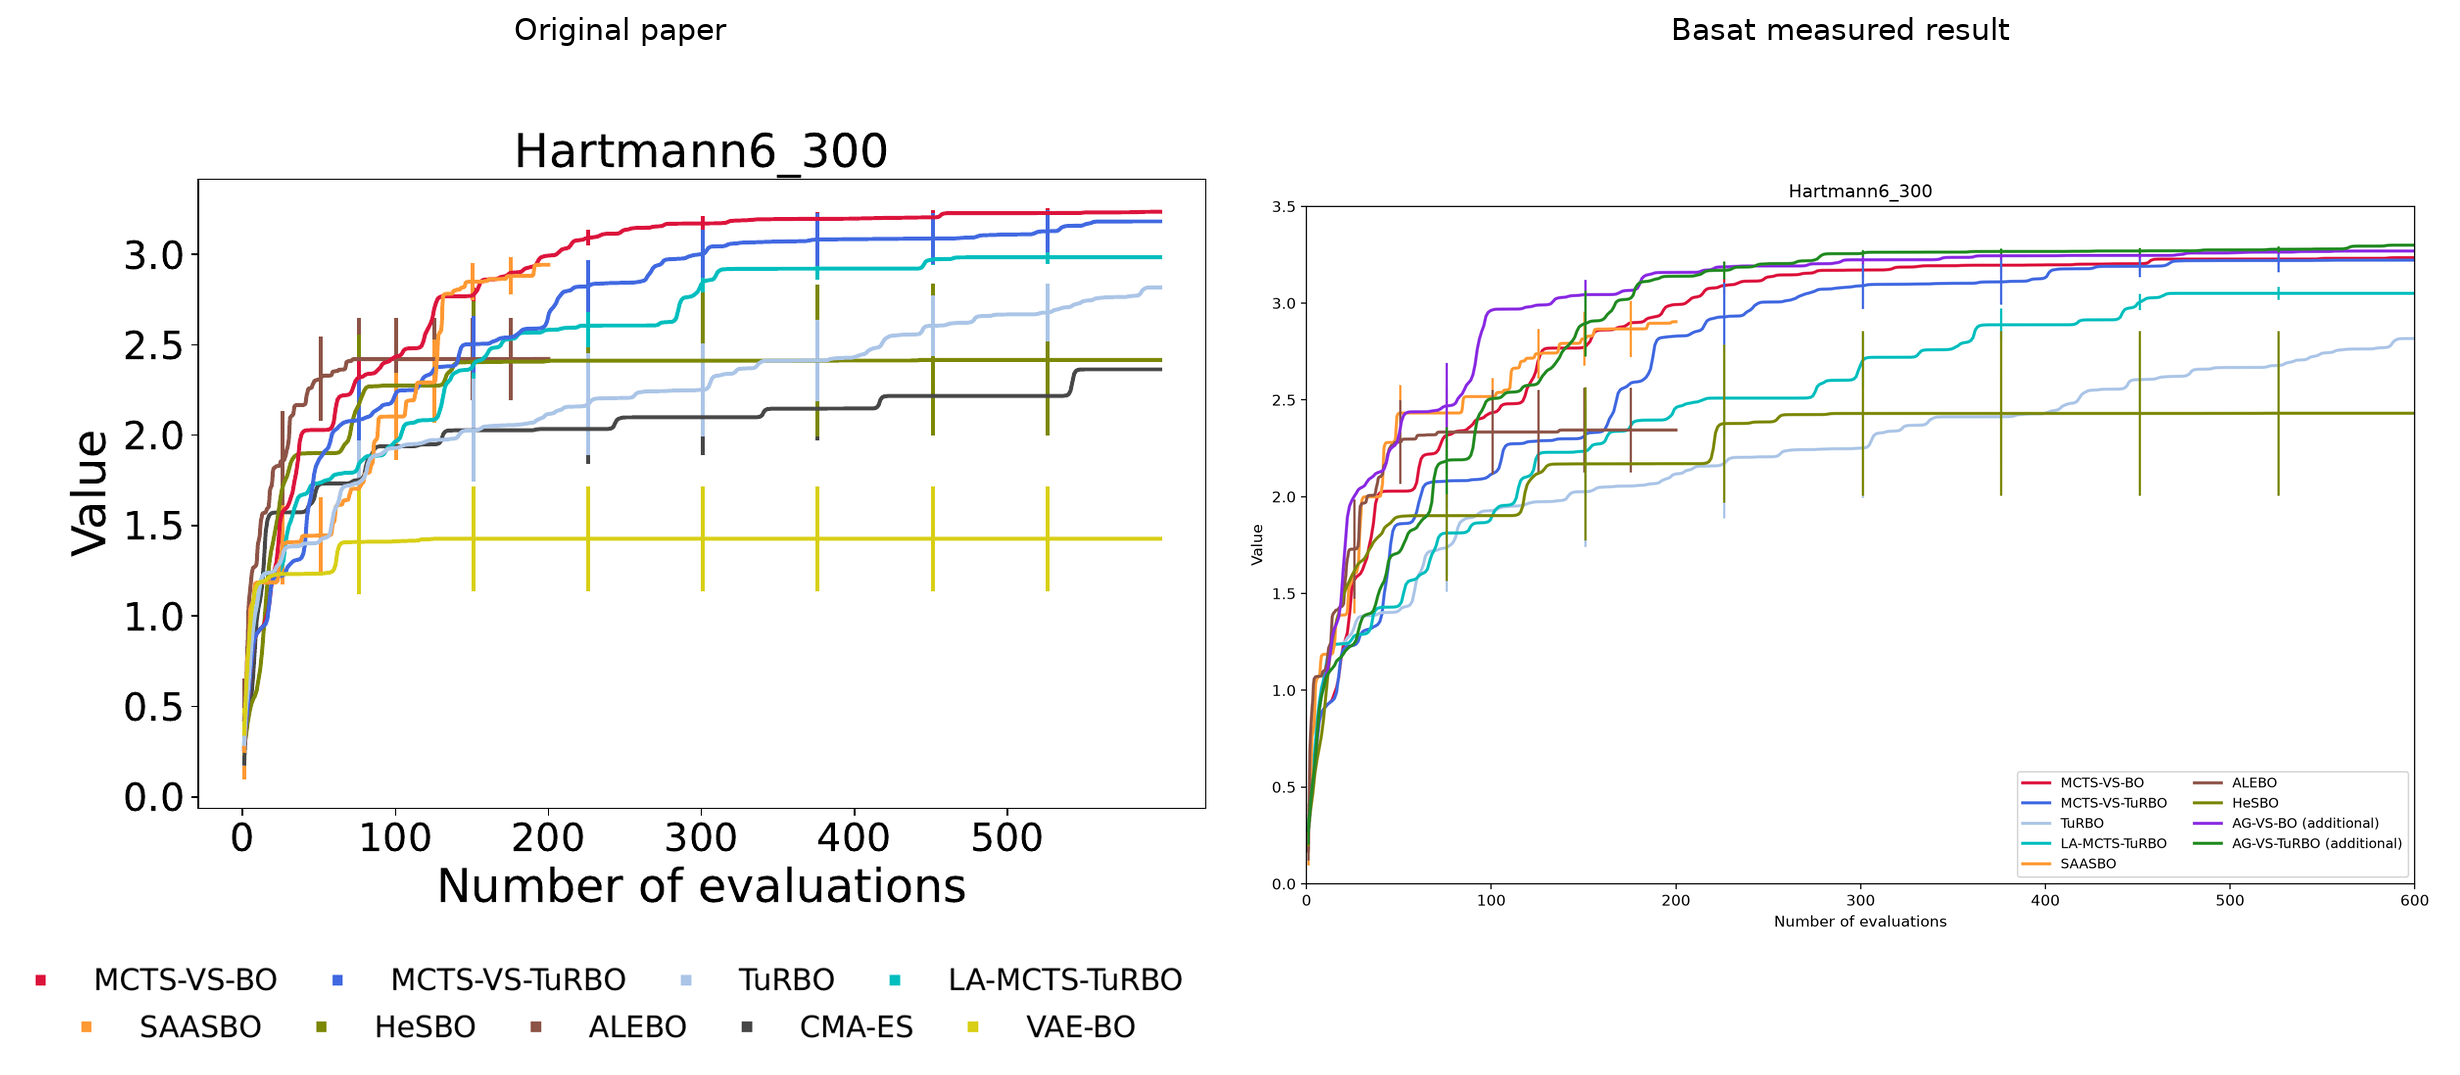

## 5.2 Shifted Dropwave: Cai et al. (2021)

In [ ]:
import basat

def shifted_dropwave(x, xp):
    """Positive 2D Dropwave, shifted to (-5.12, 5.12); input dtype is retained."""
    u, v = x[..., 0] + 5.12, x[..., 1] - 5.12
    radius_squared = u**2 + v**2
    return (1 + xp.cos(12 * xp.sqrt(radius_squared))) / (0.5 * radius_squared + 2)

def run_shifted_dropwave(
    output_directory="./results/reproducibility/shifted_dropwave_cai2021_v1",
    *,
    max_groups=None,
    show=True,
):
    basat.set_seed(2021, threads=1)
    store = basat.ArtifactStore(output_directory)
    objective = basat.NumericalFunction(shifted_dropwave, backend="numpy")
    bounds = basat.Bounds(basat.array([-5.12, -5.12]), basat.array([5.12, 5.12]))
    has_protocol = store.exists("protocol.json")
    has_calibration = store.exists("calibration.npz")
    if has_protocol != has_calibration:
        raise ValueError(
            "Calibration/protocol pair is incomplete; restore the matching artifacts or use a fresh output directory. Existing evidence is not overwritten."
        )
    saved_protocol = store.read_json("protocol.json") if has_protocol else None
    if has_calibration:
        calibration = store.read_arrays("calibration.npz")
        if set(calibration) != {"actions", "rewards"}:
            raise ValueError("Calibration archive must contain exactly actions and rewards.")
        calibration_x, calibration_y = (calibration["actions"], calibration["rewards"])
    else:
        calibration_x = basat.RandomStream(2021, engine="mt19937").uniform(
            -5.12, 5.12, size=(10000, 2)
        )
        calibration_y = basat.array(objective(calibration_x))
    if (
        tuple(calibration_x.shape) != (10000, 2)
        or tuple(calibration_y.shape) != (10000,)
        or calibration_x.dtype != bounds.dtype
        or (calibration_y.dtype != bounds.dtype)
    ):
        raise ValueError("Calibration must have float64 actions (10000, 2) and rewards (10000,).")
    if not bool(calibration_x.isfinite().all() and calibration_y.isfinite().all()):
        raise ValueError("Calibration values must be finite.")
    if not bool(((calibration_x >= bounds.lower) & (calibration_x <= bounds.upper)).all()):
        raise ValueError("Calibration actions lie outside the benchmark bounds.")
    if not bool(((calibration_y >= 0.0) & (calibration_y <= 1.0)).all()):
        raise ValueError("Positive Shifted Dropwave calibration rewards must lie in [0, 1].")
    threshold = float(calibration_y.quantile(0.99))
    protocol = {
        "version": "shifted_dropwave_cai2021_v1",
        "source_revision": "ff0ffe18a72e5eef824254ab630929708dd80455",
        "source_url": "https://github.com/caitree/GoodAction/tree/ff0ffe18a72e5eef824254ab630929708dd80455",
        "benchmark": "positive Dropwave(x1+5.12,x2-5.12)",
        "bounds": [[-5.12, -5.12], [5.12, 5.12]],
        "trials": 25,
        "seeds": list(range(2021, 2046)),
        "repetitions": 10,
        "seed_provenance": "user-selected new seeds; historical seeds unavailable",
        "method_order": ["PG", "EG", "GS", "STS"],
        "initial_points": 3,
        "initial_design": "one uniform design per trial; separately evaluated in every run",
        "random_streams": "seed NumPy/Torch per trial; continue algorithm then repetition",
        "total_query_budget": 200,
        "observation_noise": 0.0,
        "threshold": threshold,
        "calibration_seed": 2021,
        "calibration_engine": "independent MT19937",
        "calibration_samples": 10000,
        "calibration_quantile": 0.99,
        "quantile_method": "linear",
        "evaluation_precision": "source proposal float32/float64; float64 stored history",
        "numerical_protocol": "cai_2021_released; discarded fits and prior-covariance sampling retained",
        "runtime": basat.runtime_info(include_source_hash=True),
    }
    if has_protocol and saved_protocol != protocol:
        raise ValueError("Protocol, code or runtime changed; use a fresh output directory.")
    if not has_calibration:
        store.write_arrays("calibration.npz", actions=calibration_x, rewards=calibration_y)
        store.write_json("protocol.json", protocol)
    model = basat.GoodActionGPConfig(
        initial_bandwidth=0.04,
        initial_amplitude=1.0,
        bandwidth_bounds=(0.001, 1.0),
        amplitude_bounds=(0.05, 1.5),
        regularizer=1e-08,
        fit_restarts=10,
        fit_maxfun=200,
        apply_fitted_parameters=False,
        sampling_covariance="prior",
    )
    methods = {"PG": basat.PG, "EG": basat.EG, "GS": basat.GS, "STS": basat.Satisficing_TS}
    algorithms = {
        name: method(
            bounds=bounds,
            config=basat.GoodActionConfig(
                threshold=threshold,
                candidate_domain=None,
                reference_point=None,
                initial_points=3,
                initial_points_sampling_method="uniform",
                hyperparameter_refit_cycle=3,
                acquisition_restarts=10,
                source_acquisition_protocol="cai_2021_released",
                lookahead_samples=100,
                maximum_value_samples=1,
                candidate_samples=1000 if name in {"PG", "EG"} else 200,
                fit_maxiter=200,
                posterior_std_floor=1e-08,
                gp_config=None,
                source_gp=model,
                batch_size=1,
                q_batch=None,
                seed=2021,
            ),
            maximize=True,
            dtype="float64",
            device="cpu",
            plot=False,
            verbose=False,
            verbose_setting=False,
            verbose_iter_by_iter=False,
        )
        for name, method in methods.items()
    }
    environment = basat.StochasticEnvironment(
        bounds=bounds,
        function=objective,
        dataset=None,
        previous_data=None,
        noise_std=0.0,
        noise_fn=None,
        add_noise_to_data=False,
        allow_repeated_actions=True,
        data_row_selection="first",
        dtype="float64",
        device="cpu",
        seed=2021,
        evaluation_dtype="proposal",
    )
    experiment = basat.Experiment(
        environment=environment,
        algorithm=algorithms,
        stopping_rule=basat.TargetValueStoppingRule(threshold, maximize=True),
        output_directory=store.path("experiment"),
        resume=True,
        save_every=1,
        checkpoint_policy="transactional",
        initial_points_sampling_method=None,
        acquisition_sampling_method="paper",
    )
    result = experiment.run(
        grouped_trials=basat.GroupedTrialConfig(
            groups=25,
            repetitions=10,
            initial_points=3,
            seed=2021,
            order="group_algorithm_repeat",
            rng_policy="shared",
        ),
        max_evaluations=200,
        max_groups=max_groups,
        budget_policy="strict",
        plot=False,
        show=False,
        progress=False,
    )
    statistics_options = dict(
        threshold=threshold,
        max_evaluations=200,
        query_grid=list(range(0, 201, 20)),
        initial_points=3,
        incomplete="error" if max_groups is None else "complete_groups",
    )
    actual = basat.success_statistics(result, **statistics_options)
    source_plot = basat.success_statistics(
        result, source_exclude_exact_budget=True, **statistics_options
    )
    store.write_json("actual_success_statistics.json", actual.to_dict())
    store.write_json("source_plot_statistics.json", source_plot.to_dict())
    styles = {
        "PG": {"color": "#AC0026", "linestyle": "-", "marker": "s"},
        "EG": {"color": "#03517E", "linestyle": "--", "marker": "^"},
        "GS": {"color": "#502382", "linestyle": "-.", "marker": ">"},
        "STS": {"color": "#006227", "linestyle": ":", "marker": "d"},
    }
    figure = basat.plot(
        source_plot,
        styles=styles,
        error_scale=0.5,
        xlabel="Queries",
        ylabel="Success Fraction",
        title="Shifted Dropwave",
        xticks=source_plot.queries,
        figsize=(4.5, 3),
        xlim=(-10, 210),
        ylim=(-0.1, 1.1),
        grid=False,
        legend_columns=1,
        legend_fontsize=8,
        linewidth=1.5,
        capsize=2,
        save_path=store.path("basat_result.png"),
        dpi=200,
        show=False,
    )
    return (result, actual, source_plot, figure)

# Reuse the completed measurements read-only; the comparison figure is below.
# For a new campaign, set False and choose a fresh experiment output directory.
READ_COMPLETED_RESULTS = True
_completed_artifacts = {'results/reproducibility/shifted_dropwave_cai2021_v1/protocol.json': '9ceb7a3a05246d7f37691077e6d30f0e2470df16b05abe27af06d2857b4478ff', 'results/reproducibility/shifted_dropwave_cai2021_v1/calibration.npz': '4b9d3405b8cdc31f0393df4513dc53f486b31543d655c79125f02709802551c4', 'results/reproducibility/shifted_dropwave_cai2021_v1/actual_success_statistics.json': '29eed99d4b3eb35866df7d6cf4ad420d6e1e73209b78e355468b0049328dc750', 'results/reproducibility/shifted_dropwave_cai2021_v1/source_plot_statistics.json': 'e43b89dc44eb8b35101acd816a476b243d1596027f02a863bb5a406d26d4684f', 'results/reproducibility/shifted_dropwave_cai2021_v1/basat_result.png': '2811d6cd9e3485e897800b5399b1beef2b914d51cfa7406680cfbc0ff718ed3f'}
_project_store = basat.ArtifactStore(
    basat.find_path('pyproject.toml')[:-len('pyproject.toml')])
_completed_results_match = READ_COMPLETED_RESULTS and all(
    _project_store.exists(path) and _project_store.sha256(path) == checksum
    for path, checksum in _completed_artifacts.items())
if not _completed_results_match:
    if __name__ == "__main__":
        shifted_dropwave_result = run_shifted_dropwave()


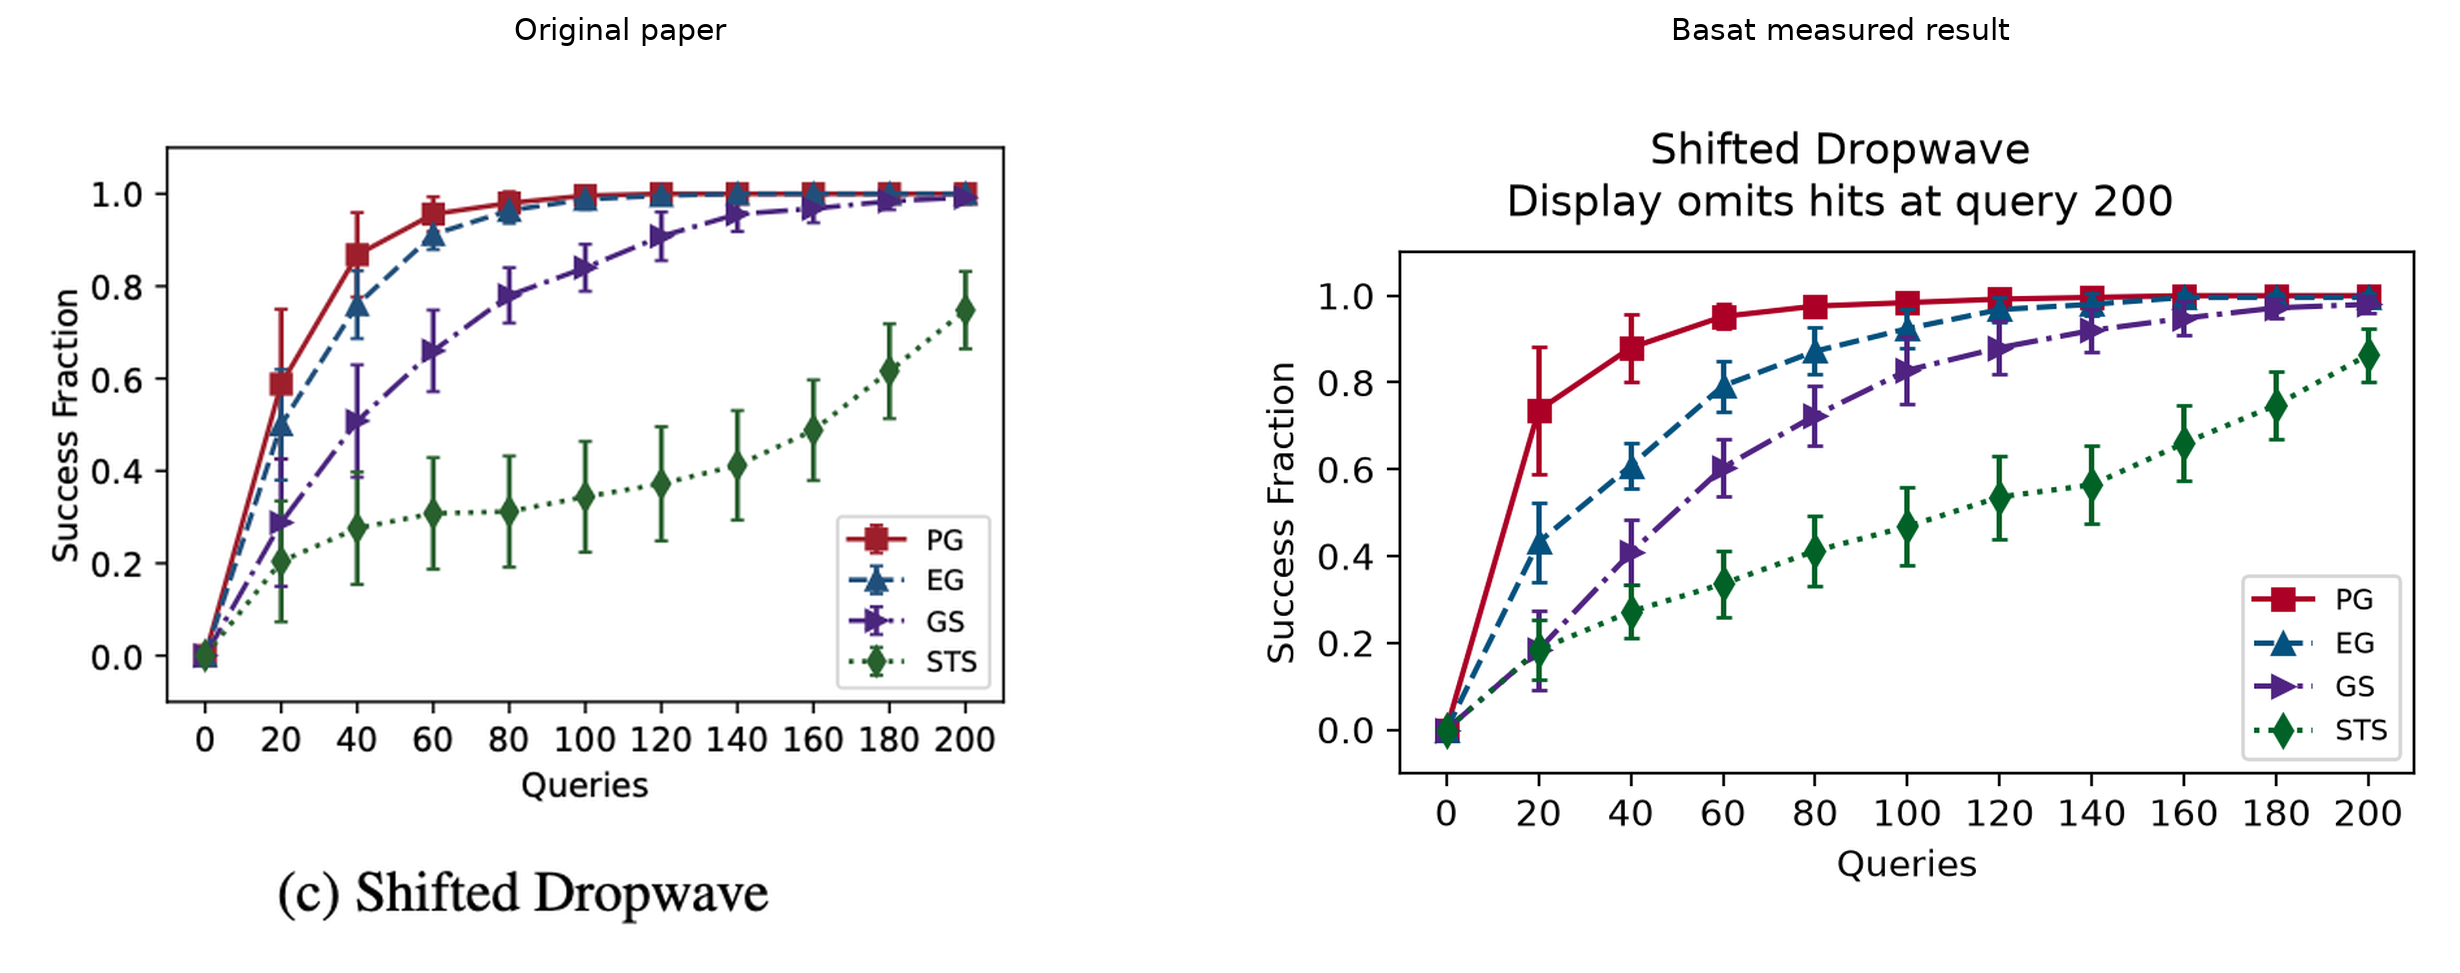

## 5.3 Branin: Letham et al. (2020)

In [ ]:
import basat

OUTPUT_DIRECTORY = "./results/reproducibility/branin_alebo2020_source_v1/run-v3"

SOURCE_REVISION = "403bbc1fb5fd895fee58789eafa6ca581a9653bd"

REFERENCE_SHA256 = "5b2d00e2029c4562168dda43fc38174987718b9c924aad23d366ddf080b9a4a0"

METHODS = {
    "ALEBO": ("alebo", "#1F77B4", "ALEBO"),
    "REMBO": ("rembo", "#AEC7E8", "REMBO"),
    "HeSBO, de=4": ("hesbo-d4", "#FFBB78", "HeSBO, d=2d"),
    "HeSBO, de=2 (addition)": ("hesbo-d2", "#FF7F0E", None),
    "ADD-GP-UCB": ("add-gp-ucb", "#FF9896", "addgpucb"),
    "TuRBO": ("turbo", "#8C564B", "turbo"),
}

def branin_algorithms(bounds):
    common = dict(
        bounds=bounds,
        maximize=False,
        dtype="float64",
        device="cpu",
        plot=True,
        verbose=False,
        verbose_setting=False,
        verbose_iter_by_iter=False,
    )
    return {
        "ALEBO": basat.ALEBO(
            **common,
            config=basat.ALEBOConfig(
                embedding_dimension=4,
                source_protocol="ax_0_1_17",
                initial_points=10,
                initial_points_sampling_method="paper",
                acquisition=basat.AcquisitionConfig(name="EI"),
                metric_inference="laplace",
                metric_posterior_samples=25,
                fit_restarts=10,
                raw_feasible_samples=1000,
                num_restarts=10,
                acquisition_solver="slsqp",
                noise_variance=1e-07,
                batch_size=1,
                q_batch=None,
                seed=2021,
            ),
        ),
        "REMBO": basat.InterleavedAlgorithm(
            {
                f"projection-{i + 1}": basat.REMBO(
                    **common,
                    config=basat.REMBOConfig(
                        embedding_dimension=2,
                        source_protocol="ax_0_1_17",
                        kernel_type="low_dimensional",
                        initial_points=2,
                        initial_points_sampling_method="paper",
                        acquisition="EI",
                        batch_size=1,
                        q_batch=None,
                        seed=2021,
                    ),
                )
                for i in range(4)
            },
            seed=2021,
            rng_policy="shared",
            plot=True,
        ),
        **{
            label: basat.HeSBO(
                **common,
                config=basat.HeSBOConfig(
                    embedding_dimension=dimension,
                    source_protocol="ax_0_1_17",
                    initial_points=10,
                    initial_points_sampling_method="paper",
                    acquisition=basat.AcquisitionConfig(name="EI"),
                    hash_family="paper",
                    batch_size=1,
                    q_batch=None,
                    seed=2021,
                ),
            )
            for label, dimension in (("HeSBO, de=4", 4), ("HeSBO, de=2 (addition)", 2))
        },
        "ADD-GP-UCB": basat.ADD_GP_UCB(
            **common,
            config=basat.AddGPUCBConfig(
                implementation="basat-alebo-2020",
                source_max_capital=49,
                batch_size=1,
                q_batch=None,
                seed=2021,
            ),
        ),
        "TuRBO": basat.TuRBO(
            **common,
            config=basat.TuRBOConfig(
                source_protocol="alebo_2020",
                initial_points=10,
                initial_points_sampling_method="paper",
                batch_size=1,
                q_batch=None,
                candidate_count=5000,
                acquisition="TS",
                gp_training_steps=50,
                max_cholesky_size=2000,
                noisy_center="best_observation",
                length_init=0.8,
                length_min=0.5**7,
                length_max=1.6,
                success_tolerance=3,
                failure_tolerance=100,
                perturbation_cap=20.0,
                success_relative_tolerance=0.001,
                seed=2021,
            ),
        ),
    }

def run_branin(*, methods=None, max_trials=None, output_directory=OUTPUT_DIRECTORY, show=True):
    basat.set_seed(2021, threads=1)
    bounds = basat.Bounds(lower=[-5.0] * 50 + [0.0] * 50, upper=[10.0] * 50 + [15.0] * 50)
    objective = basat.Branin(
        dimension=100, active_dimensions=(19, 64), bounds=bounds, dtype="float64", device="cpu"
    )
    algorithms = branin_algorithms(bounds)
    selected = tuple(METHODS) if methods is None else tuple(methods)
    if not selected or len(set(selected)) != len(selected) or set(selected) - set(METHODS):
        raise ValueError("Select distinct declared method labels.")
    store = basat.ArtifactStore(output_directory)
    protocol = {
        "protocol": "branin-alebo2020-source-v1",
        "benchmark": objective.metadata,
        "source_revision": SOURCE_REVISION,
        "source_baseline": {"ax": "0.1.17", "botorch": "0.3.1"},
        "turbo_revision": "8461f9c",
        "additive_source": "dragonfly-0.1.4",
        "seeds": list(range(2021, 2071)),
        "trials_per_method": 50,
        "evaluations_per_run": 50,
        "total_comparison_runs": 300,
        "total_objective_evaluations": 15000,
        "methods": METHODS,
        "historical_seeds_recovered": False,
        "initializer_entropy_reconstruction": "separate recorded MT19937 seed stream",
        "evaluation_protocol": "ax_0_1_17",
        "reference_sha256": REFERENCE_SHA256,
        "endpoint_tolerance": 0.1,
        "runtime": basat.runtime_info(include_source_hash=True),
    }
    protocol = basat.to_list(protocol)
    if store.exists("protocol.json"):
        if store.read_json("protocol.json") != protocol:
            raise ValueError(
                "Scientific configuration or runtime changed; select a fresh output directory."
            )
    else:
        store.write_json("protocol.json", protocol)
    results = {}
    for label in selected:
        slug = METHODS[label][0]
        environment = basat.StochasticEnvironment(
            bounds=bounds,
            function=objective,
            dataset=None,
            previous_data=None,
            noise_std=0.0,
            noise_fn=None,
            add_noise_to_data=False,
            allow_repeated_actions=True,
            data_row_selection="first",
            dtype="float64",
            device="cpu",
            seed=2021,
        )
        experiment = basat.Experiment(
            environment=environment,
            algorithm={label: algorithms[label]},
            stopping_rule=None,
            output_directory=store.path(slug),
            resume=True,
            save_every=1,
            checkpoint_policy="transactional",
            evaluation_protocol="ax_0_1_17",
            initial_points_sampling_method="paper",
            acquisition_sampling_method="paper",
        )
        result = experiment.run(
            trials=50,
            max_trials=max_trials,
            max_evaluations=50,
            budget_policy="strict",
            fail_fast=True,
            progress=False,
            plot=False,
            show=False,
        )
        results[label] = result
        method_store = basat.ArtifactStore(store.path(slug))
        method_store.write_json("raw_trials.json", result.to_dict())
    figure = (
        report_branin(output_directory=output_directory, show=False)[1]
        if len(selected) == 6
        else None
    )
    return (results, figure)

def _validated_branin_records(document, label, slug):
    records = document.get("records", [])
    count = document.get("completed_trials")
    if (
        document.get("package") != "basat"
        or document.get("mode") != "trials"
        or document.get("schema_version") != 1
        or (document.get("planned_trials") != 50)
        or (type(count) is not int)
        or (not 1 <= count <= 50)
        or (count != len(records))
    ):
        raise ValueError(label + ": invalid saved trial coverage or schema.")
    checked, paths = ([], set())
    for index, trial in enumerate(records):
        if trial.get("algorithm_order") != [label] or set(trial.get("algorithms", {})) != {label}:
            raise ValueError(label + ": saved method identity does not match.")
        if trial.get("limits") != {
            "max_rounds": None,
            "max_evaluations": 50,
            "budget_policy": "strict",
        }:
            raise ValueError(label + ": saved budget policy does not match.")
        persistence = trial.get("persistence", {})
        if (
            persistence.get("checkpoint_policy") != "transactional"
            or persistence.get("evaluation_protocol") != "ax_0_1_17"
        ):
            raise ValueError(label + ": saved evaluation/checkpoint protocol does not match.")
        row = trial["algorithms"][label]
        if (
            row.get("failure") is not None
            or row.get("maximize") is not False
            or row.get("initial_observation_count") != 0
            or any(
                (
                    type(row.get(key)) is not int or row[key] != 50
                    for key in ("environment_evaluations", "completed_rounds")
                )
            )
            or (row.get("result", {}).get("evaluations") != 50)
            or (row.get("stopping_reason") != "maximum_evaluations")
            or (len(row.get("observations", [])) != 50)
        ):
            raise ValueError(
                label
                + ": each saved trial must have exactly 50 evaluations and no warm start/failure."
            )
        path = str(row.get("output_directory", "")).replace("\\", "/")
        marker = f"/{slug}/trials/trial-{index + 1:03d}/algorithms/"
        if marker not in path or not path.rsplit("/", 1)[-1] or path in paths:
            raise ValueError(label + ": saved trial ordering or identity does not match.")
        paths.add(path)
        if label != "REMBO" and (row.get("configuration") or {}).get("seed") != 2021 + index:
            raise ValueError(label + ": saved trial seed does not match the predeclared sequence.")
        checked.append(row)
    return checked

def report_branin(*, output_directory=OUTPUT_DIRECTORY, show=True, allow_partial=True):
    store = basat.ArtifactStore(output_directory)
    observations = {}
    for label, (slug, _, _) in METHODS.items():
        document = store.read_json(slug + "/raw_trials.json")
        records = _validated_branin_records(document, label, slug)
        observations[label] = [row["observations"] for row in records]
    series = {
        label: basat.PlotSeries.from_runs(
            observations[label],
            transform="incumbent",
            maximize=False,
            uncertainty=None,
            smoothing="none",
            color=METHODS[label][1],
            linestyle="-",
            linewidth=2.0,
        )
        for label in METHODS
    }
    figure = basat.plot_panels(
        [
            basat.PlotPanel(
                series,
                title="Branin, d=2, D=100",
                xlabel="Function evaluations",
                ylabel="Best Value Found",
                xlim=(0, 51),
                ylim=(0, 7),
                xscale="linear",
                yscale="linear",
                grid=True,
                horizontal_lines=(0.397887,),
                legend_columns=2,
            )
        ],
        figsize=(8.0, 5.5),
        font_family="serif",
        show=False,
        save_path=store.path("basat_result.png"),
    )
    return (None, figure)

# Reuse the completed measurements read-only; the comparison figure is below.
# For a new campaign, set False and choose a fresh experiment output directory.
READ_COMPLETED_RESULTS = True
_completed_artifacts = {'results/reproducibility/branin_alebo2020_source_v1/run-v3/protocol.json': '9fecd1104492b405b42edb430175e88a6423784742cc915ca51a20fa19b40e8b', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/alebo/raw_trials.json': 'eb674d181eba05d8d5a5909dbcf7d389f1e9a566c2def4fbd2c9cfc240905691', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/rembo/raw_trials.json': 'b2b9295c4fb5b296d59f76cfd9c4f3fca9d8fd23dad1f7c4323f60a3eebf3b9e', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/hesbo-d4/raw_trials.json': '8f6e9c8088904331ef6069485096773c9a8a473008d5fedcfb7e5d01678d6d3e', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/hesbo-d2/raw_trials.json': '4ca750197462653a6cb9594d0adf099a98d6a966b3aa055d1e158a61d7a2cc8c', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/add-gp-ucb/raw_trials.json': '207ae038b0e6c9092b0066abb60a6d414e18330f0e2dbddc320baebd8d6f02de', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/turbo/raw_trials.json': '3513e92019ca4c5f30eb5d92ef54076c0fc85054aeb53b9c2ca4004f6200ab2b', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/published_results.json': '5b2d00e2029c4562168dda43fc38174987718b9c924aad23d366ddf080b9a4a0', 'results/reproducibility/branin_alebo2020_source_v1/run-v3/basat_result.png': '1d6ab6eccd1e18bb15e399b6df67a2341931b25c47e43875e198db89e8f361aa'}
_project_store = basat.ArtifactStore(
    basat.find_path('pyproject.toml')[:-len('pyproject.toml')])
_completed_results_match = READ_COMPLETED_RESULTS and all(
    _project_store.exists(path) and _project_store.sha256(path) == checksum
    for path, checksum in _completed_artifacts.items())
if not _completed_results_match:
    if __name__ == "__main__":
        results, figure = run_branin()


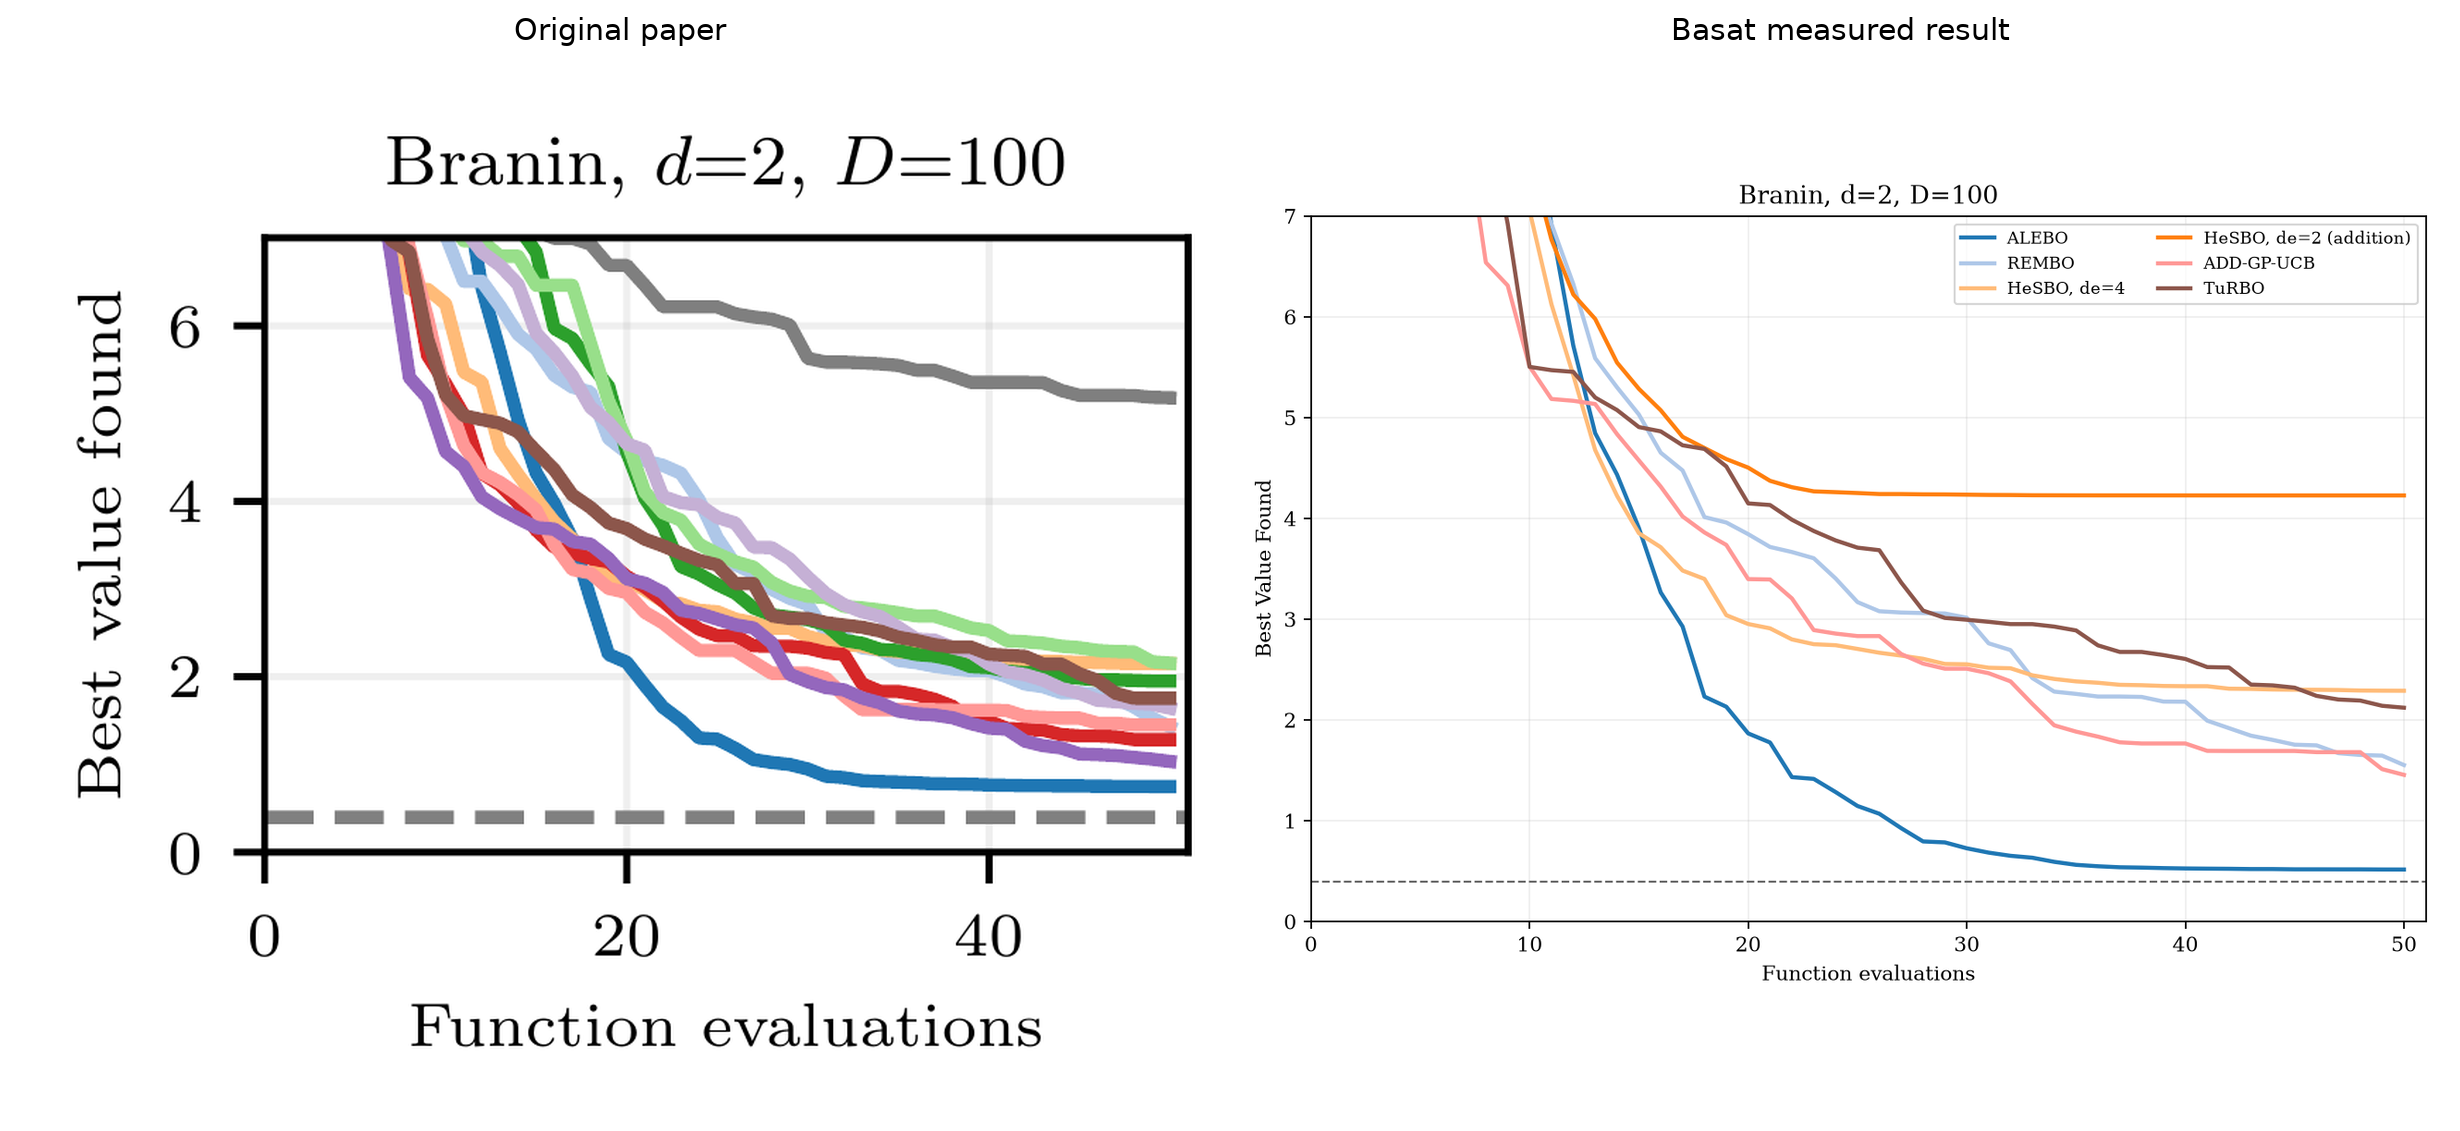

## 5.4 AdveRS: LCB attack

In [ ]:
import basat

TRIALS, ONLINE_ROUNDS = (100, 100)

MAX_SOURCE_RUNS = None

required_versions = {"numpy": "1.26.4", "scipy": "1.12.0", "scikit-learn": "1.7.2"}

metric_preparation_queries = 0

labels = (
    "RS-G, p = 1 (RS-1)",
    "RS-G, p = ∞ (RS-2)",
    "RS-G, p = 2",
    "RO r = εₜ",
    "RO r = 0.5 · εₜ",
    "RO r = 4 · εₜ",
)

roles = ("RS1", "RS2", "RSG", "RO_true", "RO_small", "RO_large")

colors = ("#FF0000", "#BF00BF", "#FFA500", "#0000FF", "#008000", "#8B0000")

algorithms, environments = ({}, {})

error_indices = (0, 16, 32, 48, 64, 80, 96)

# Reuse the completed measurements read-only; the comparison figure is below.
# For a new campaign, set False and choose a fresh experiment output directory.
READ_COMPLETED_RESULTS = True
_completed_artifacts = {'results/reproducibility/advers2026_lcb_serial_readme_v1/native/protocol.json': '7ca5d924bf203dda8f17912ffd4a19b7e445e5cdee17dc5e9164e7816bd83791', 'results/reproducibility/advers2026_lcb_serial_readme_v1/native/runtime.json': 'f2965a63f61ec6bac957f708363154c372deb9494e2109b337d6f66a19f5b4af', 'results/reproducibility/advers2026_lcb_serial_readme_v1/native/statistics.json': '51a49a20dced791ffb245ed40d09b2252c16a44bca8e2ae75c6a570b4dece88a', 'results/reproducibility/advers2026_lcb_serial_readme_v1/native/trial-results.json': '17b4eacb57bc4c26c340d818b709707fceeedbb138a85f19a9467fdf88c3649d', 'results/reproducibility/advers2026_lcb_serial_readme_v1/native/metric-grid.json': 'b21e0c18103c59d1c5e72e5b3d22b067887c920beec54b18ecc83960f8699f05', 'results/reproducibility/advers2026_lcb_serial_readme_v1/native/metric-grid.npz': '222a13cbcd60bbbca800d87f4af9003acd6cea13229f82ce3cef4dec86c2cbe3', 'results/reproducibility/advers2026_lcb_serial_readme_v1/native/lcb_regret.png': '66cd17ee496ce2b64172a4ef224c5b2edee1e9382c9f810d860dac417c7e5340'}
_project_store = basat.ArtifactStore(
    basat.find_path('pyproject.toml')[:-len('pyproject.toml')])
_completed_results_match = READ_COMPLETED_RESULTS and all(
    _project_store.exists(path) and _project_store.sha256(path) == checksum
    for path, checksum in _completed_artifacts.items())
if not _completed_results_match:
    runtime = basat.runtime_info(include_source_hash=True)

    if any((runtime.get(package) != version for package, version in required_versions.items())):
        raise RuntimeError(
            "Use a separate Python 3.11 environment installed with .[advers-source]; see docs/reproduction.md."
        )

    PROJECT_DIRECTORY = basat.find_path("pyproject.toml")[: -len("pyproject.toml")]

    OUTPUT_DIRECTORY = basat.ArtifactStore(PROJECT_DIRECTORY).path(
        "results/reproducibility/advers2026_lcb_serial_readme_v1/native"
    )

    basat.set_seed(0, threads=1)

    store = basat.ArtifactStore(OUTPUT_DIRECTORY)

    if store.exists("runtime.json") and store.read_json("runtime.json") != runtime:
        raise RuntimeError("Runtime or complete Basat source changed; use a fresh output directory.")

    benchmark = basat.AdveRSSynthetic(formula="released", resolution=32, dtype="float64")

    grid = benchmark.grid()

    if store.exists("metric-grid.json"):
        identity = store.read_json("metric-grid.json")
        if (
            identity["benchmark"] != basat.to_list(benchmark.metadata)
            or identity["source_sha256"] != runtime["basat_source_sha256"]
            or identity["array_sha256"] != store.sha256("metric-grid.npz")
        ):
            raise RuntimeError("Saved metric grid is incompatible or corrupted.")
        cached = store.read_arrays("metric-grid.npz")
        if not bool((cached["actions"] == grid).all()):
            raise RuntimeError("Metric grid order changed.")
        truth = cached["latent_rewards"]
    else:
        truth = benchmark(grid)
        metric_preparation_queries = len(grid)
        store.write_arrays("metric-grid.npz", actions=grid, latent_rewards=truth)
        store.write_json(
            "metric-grid.json",
            {
                "benchmark": benchmark.metadata,
                "source_sha256": runtime["basat_source_sha256"],
                "array_sha256": store.sha256("metric-grid.npz"),
                "preparation_queries": len(grid),
            },
        )

    fragility = basat.finite_domain_optimal_fragility(grid, truth, aspiration=-10.0, p=1.0)

    if abs(fragility.optimal_fragility - 20.129238666994205) > 1e-10:
        raise RuntimeError("Common true RS1 fragility differs from the pinned released grid.")

    metric = basat.RSRegret(
        aspiration=-10.0,
        optimal_fragility=fragility.optimal_fragility,
        epsilon=0.5,
        p=1.0,
        cumulative=True,
    )

    method_roles = dict(zip(labels, roles))

    for method, label in enumerate(labels):
        kernel = basat.FixedPolynomialKernel(
            input_dimension=2, variance=1.32, scale=1.11, bias=2.84, order=6, arithmetic="gpy"
        )
        gp = basat.GaussianProcessConfig(
            kernel=kernel,
            mean="zero",
            noise_mode="fixed",
            noise_variance=1.0,
            standardize_outcomes=False,
            jitter=1e-10,
            dtype="float64",
            device="cpu",
        )
        settings = dict(
            beta=1.0,
            initial_points=10,
            fit_maxiter=0,
            gp_config=gp,
            gp_backend="fixed_gpy",
            gp_training_regularization=1e-08,
            source_protocol="advers_2026_camera_ready",
            batch_size=1,
            seed=0,
        )
        common = dict(
            bounds=benchmark.bounds,
            maximize=True,
            dtype="float64",
            device="cpu",
            plot=False,
            verbose=False,
            verbose_setting=False,
            verbose_iter_by_iter=False,
        )
        if method < 3:
            algorithms[label] = basat.AdveRS(
                **common,
                config=basat.AdveRSConfig(
                    **settings,
                    variant=roles[method],
                    p=2.0 if method == 2 else 1.0,
                    aspiration=-10.0,
                    finite_tie_break="first",
                ),
            )
        else:
            algorithms[label] = basat.StableOPT(
                **common,
                config=basat.StableOPTConfig(
                    **settings,
                    perturbation_radius=(0.5, 0.25, 2.0)[method - 3],
                    query_policy="center",
                    finite_tie_break="random",
                ),
            )
        environments[label] = basat.AdversarialEnvironment(
            bounds=benchmark.bounds,
            function=benchmark,
            candidate_actions=grid,
            attack=basat.LCBAttack(radius=0.5),
            noise_std=1.0,
            allow_repeated_actions=True,
            dtype="float64",
            device="cpu",
            seed=0,
        )

    protocol = {
        "protocol": "advers2026-lcb-serial-readme-v1",
        "source_revision": "6de58579174a71a247bb92f7f920f015f3331ff9",
        "benchmark": benchmark.metadata,
        "methods": list(labels),
        "method_roles": method_roles,
        "trials_per_method": TRIALS,
        "initial_queries_per_run": 10,
        "online_queries_per_run": ONLINE_ROUNDS,
        "kernel": "1.32*(1.11*x.dot(xprime)+2.84)**6",
        "likelihood_variance": 1.0,
        "gp_backend": "fixed_gpy",
        "gp_training_regularization": 1e-08,
        "kernel_arithmetic": "gpy",
        "native_runtime_versions": required_versions,
        "source_protocol": "advers_2026_camera_ready",
        "confidence": "posterior standard deviation every online round; coefficient 1",
        "beta": 1.0,
        "metric": "common true RS1-reference regret",
        "optimal_fragility": fragility.optimal_fragility,
        "metric_grid_size": len(grid),
        "attack_mode": 1,
        "physical_attack_radii": [0.5] * 6,
        "rsg_distance": "Euclidean distance raised to p in the fragility objective",
        "source_normal_protocol": "advers-numpy126-scalar-polar-v1",
        "ro_radii": [0.5, 0.25, 2.0],
        "global_seed": 0,
        "source_schedule": "advers_serial_random_prefix_then_lcb",
        "seed_rule": "single owned MT19937 seed0; all random-prefix blocks then all LCB blocks, method-major repetitions",
        "planned_random_prefix_runs": 600,
        "planned_lcb_runs": 600,
        "prefix_attack": "native finite random attack; physical radius0.5; released per-role squared-distance arithmetic",
        "source_cli_scope": "synthetic.py default attack0 then attack1; stop before subsequent attack2 blocks",
        "historical_seed_qualification": "released CLI seed0 baseline, not the unavailable original paper seeds",
    }

    for filename, value in (("protocol.json", protocol), ("runtime.json", runtime)):
        if store.exists(filename) and store.read_json(filename) != basat.to_list(value):
            raise RuntimeError(f"{filename} changed; use a fresh output directory.")
        store.write_json(filename, value)

    if not store.exists("preparation-initial.json"):
        store.write_json(
            "preparation-initial.json",
            {
                "metric_objective_evaluations": store.read_json("metric-grid.json")[
                    "preparation_queries"
                ],
                "attack_objective_evaluations": 0,
                "qualification": "Metric-only latent grid; neither random nor LCB attack uses a hidden true-payoff cache.",
            },
        )

    store.write_json(
        "preparation-latest.json",
        {
            "metric_objective_evaluations_this_invocation": metric_preparation_queries,
            "attack_objective_evaluations_this_invocation": 0,
        },
    )

    experiment = basat.Experiment(
        environment=environments,
        algorithm=algorithms,
        stopping_rule=None,
        output_directory=store.path("campaign"),
        resume=True,
        save_every=100,
        checkpoint_policy="transactional",
        evaluation_protocol=basat.AdveRSSerialSourceProtocol(method_roles=method_roles, seed=0),
    )

    comparison = experiment.run(
        trials=TRIALS,
        max_source_runs=MAX_SOURCE_RUNS,
        max_rounds=ONLINE_ROUNDS,
        regret=metric,
        fail_fast=True,
        plot=False,
        show=False,
        progress=False,
    )

    experiment.save(store.path("trial-results.json"))

    source_summary = comparison.source_summary

    store.write_json(
        "accounting.json",
        {
            "planned_prefix_runs": 600,
            "planned_lcb_runs": 600,
            "planned_source_runs": 1200,
            "completed_prefix_runs": source_summary["completed_prefix_runs"],
            "completed_lcb_runs": source_summary["completed_lcb_runs"],
            "completed_source_runs": source_summary["completed_source_runs"],
            "completed_returned_lcb_groups": len(comparison.records),
            "query_counts_by_phase": source_summary["query_counts_by_phase"],
            "metric_preparation_queries": store.read_json("metric-grid.json")["preparation_queries"],
            "metric_is_excluded_from_learner_queries": True,
            "random_prefix_is_not_plotted": True,
        },
    )

    regret_runs = comparison.regret_runs

    series = {
        label: basat.PlotSeries.from_runs(
            regret_runs[label],
            transform="none",
            uncertainty="sd",
            ddof=0,
            error_scale=0.5,
            smoothing="none",
            x=range(ONLINE_ROUNDS),
            color=colors[index],
            linestyle="--",
            marker="^" if index < 3 else "d",
            markevery=list(error_indices),
            error_every=error_indices,
            linewidth=2.0,
            capsize=4.0,
        )
        for index, label in enumerate(labels)
        if regret_runs.get(label)
    }

    store.write_json(
        "statistics.json",
        {
            "planned_trials": TRIALS,
            "online_rounds": ONLINE_ROUNDS,
            "metric": "cumulative RS1-reference regret",
            "error": "population SD / 2",
            "plotted_phase": "lcb",
            "source_schedule": "advers_serial_random_prefix_then_lcb",
            "methods": {
                label: {
                    "completed_runs": len(regret_runs.get(label, ())),
                    "committed_lcb_runs": source_summary["completed_runs_by_phase_and_method"]["lcb"][
                        label
                    ],
                    "mean": series[label].values if label in series else [],
                    "sd_over_2": series[label].error if label in series else [],
                    "runs": regret_runs.get(label, ()),
                }
                for label in labels
            },
        },
    )

    if series:
        plot = basat.plot_panels(
            [
                basat.PlotPanel(
                    series,
                    title="LCB Attack",
                    xlabel="Round t",
                    ylabel="RS Regret",
                    xlim=(-5, 104),
                    ylim=(-36, 870),
                    xticks=(0, 20, 40, 60, 80, 100),
                    grid=False,
                    legend=True,
                    legend_title="τ = -10, εₜ = 0.5",
                    legend_location="upper left",
                    legend_fontsize=10,
                )
            ],
            columns=1,
            figsize=(8.6, 5.9),
            font_family="serif",
            save_path=store.path("lcb_regret.png"),
            dpi=200,
            show=False,
        )


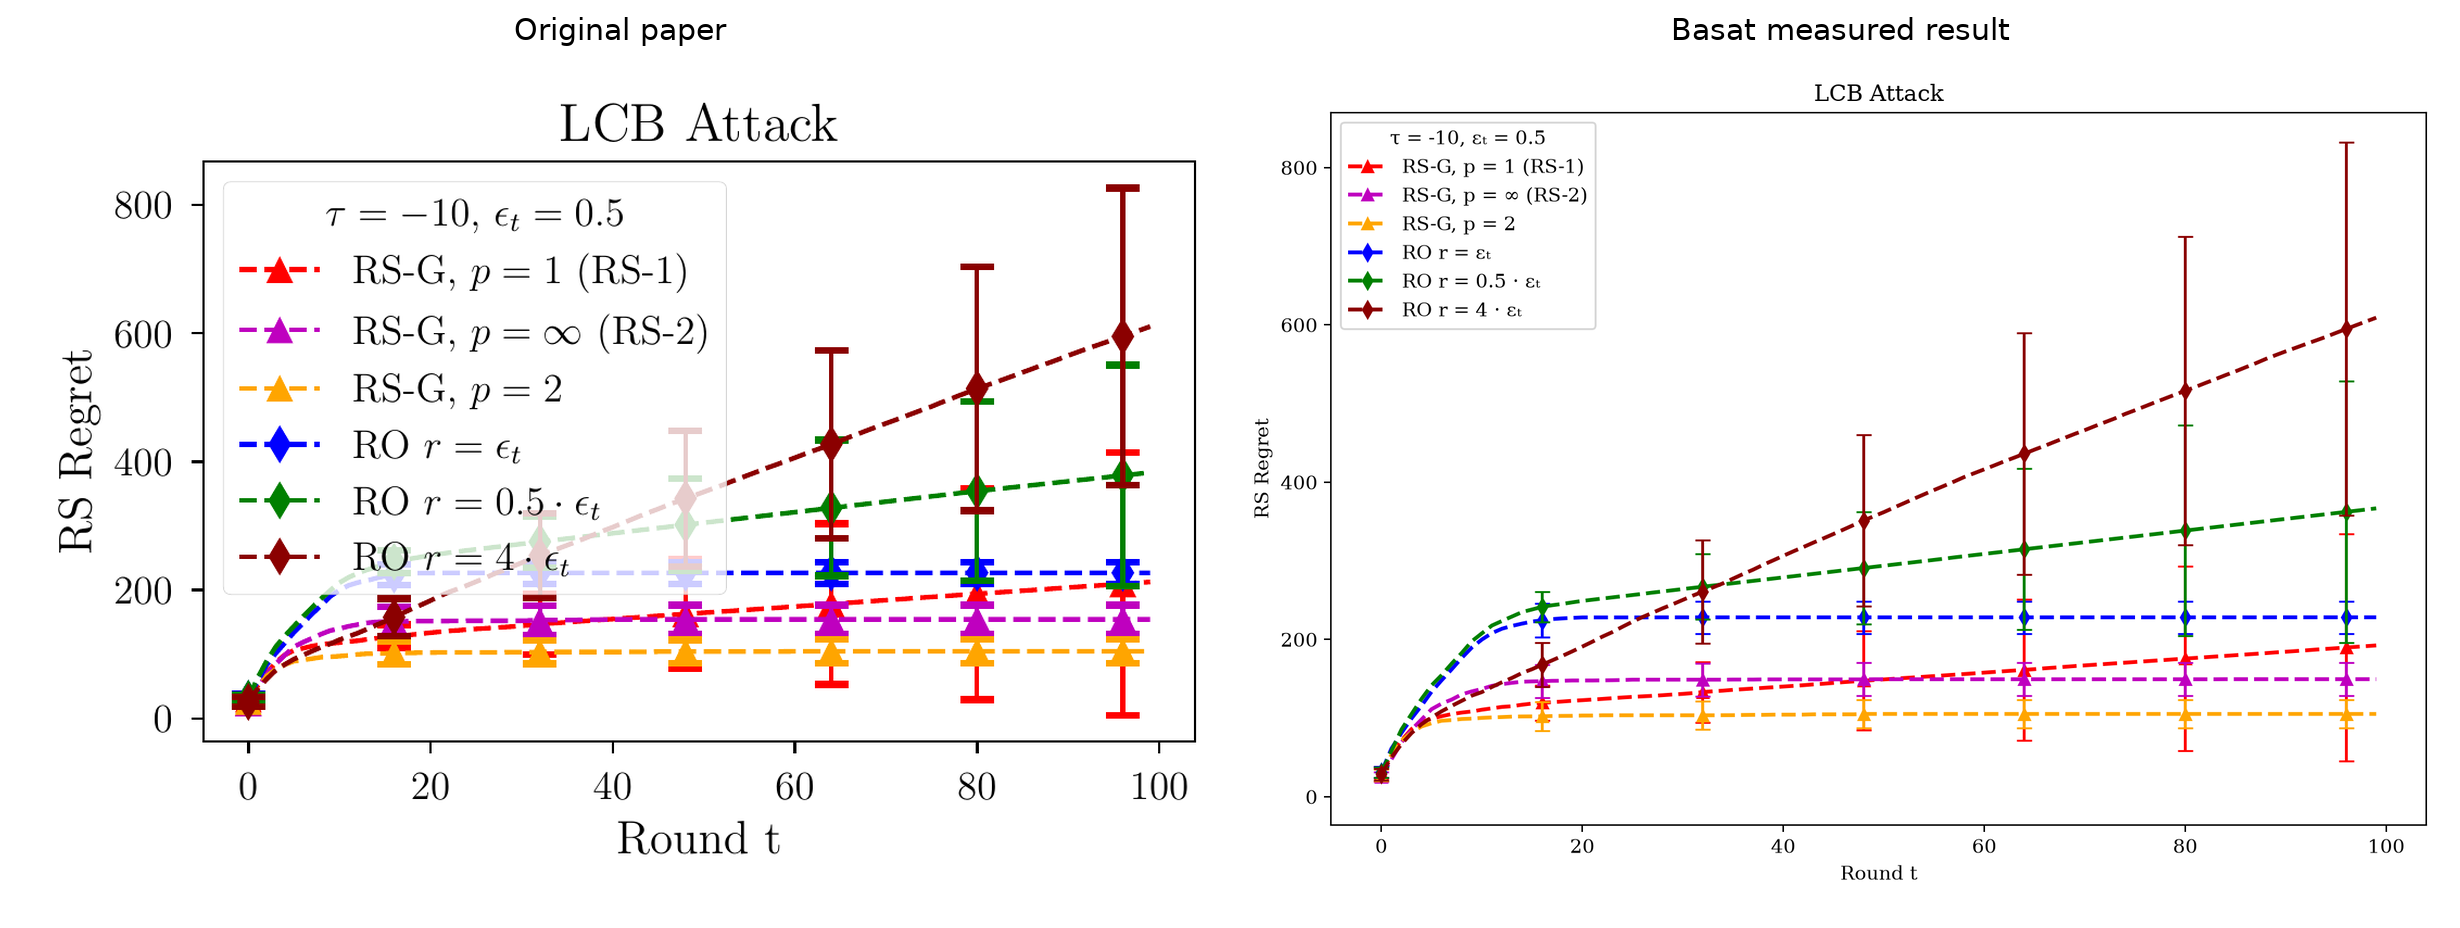

## 5.5 RoBOS: synthetic function

In [ ]:
import basat

OUTPUT_DIRECTORY = "./results/reproducibility/robos2023_synthetic_source_v1"

TRIALS, ONLINE_ROUNDS, MAX_TRIALS = (50, 201, None)

labels = ("DRBO: 3ε", "DRBO: ε", "DRBO: ε/3", "RoBOS")

roles = ("drbo_3epsilon", "drbo_epsilon", "drbo_epsilon_over_3", "robos")

colors = ("#A23582", "#04649D", "#592F0D", "#AC0026")

algorithms, environments = ({}, {})

# Reuse the completed measurements read-only; the comparison figure is below.
# For a new campaign, set False and choose a fresh experiment output directory.
READ_COMPLETED_RESULTS = True
_completed_artifacts = {'results/reproducibility/robos2023_synthetic_source_v1/protocol.json': '85c991ca2f2ec018ebb1a495f003c1d6ccb7f27d7c350febba8ee11a8e889849', 'results/reproducibility/robos2023_synthetic_source_v1/runtime.json': '050b146747a84426f740ff4f86daf3470d126e0a864da09f31732536020d095e', 'results/reproducibility/robos2023_synthetic_source_v1/statistics.json': 'db9b3f451ec06195641f3a79d11bddac99d22e0b746852dd9b72ba9eb4f5b1d0', 'results/reproducibility/robos2023_synthetic_source_v1/trial-results.json': '34af940fc2ec56a13bed0cbc0c33500a3162650478bc9e8f2ac29fa50c66f050', 'results/reproducibility/robos2023_synthetic_source_v1/source_summary.json': 'a43c9a2983dd187d383a0c85556b99a99696e16f89f135ecf3c9a0ce03b88cd0', 'results/reproducibility/robos2023_synthetic_source_v1/rs_regret.png': '0262a45c4ac59623e7759ca0fd4084d4ee377b8652b676b5ed3a4c03e8cec6d5'}
_project_store = basat.ArtifactStore(
    basat.find_path('pyproject.toml')[:-len('pyproject.toml')])
_completed_results_match = READ_COMPLETED_RESULTS and all(
    _project_store.exists(path) and _project_store.sha256(path) == checksum
    for path, checksum in _completed_artifacts.items())
if not _completed_results_match:
    basat.set_seed(123, threads=1)

    store = basat.ArtifactStore(OUTPUT_DIRECTORY)

    benchmark = basat.RoBOSSynthetic(cache_directory=store.path("data"), dtype="float64")

    epsilon = benchmark.epsilon

    for index, label in enumerate(labels):
        gp = basat.GaussianProcessConfig(
            kernel=basat.FixedRBFKernel(input_dimension=2, lengthscale=[0.2, 5.0], ard=True),
            mean="zero",
            noise_mode="fixed",
            noise_variance=0.0004,
            standardize_outcomes=False,
            jitter=1e-10,
            dtype="float64",
            device="cpu",
        )
        settings = dict(
            action_kernel=basat.FixedRBFKernel(input_dimension=1, lengthscale=0.2),
            context_kernel=basat.FixedRBFKernel(input_dimension=1, lengthscale=5.0),
            gp_config=gp,
            gp_backend="fixed_gpy",
            gp_training_regularization=1e-08,
            beta=4.0,
            initial_points=3,
            batch_size=1,
            seed=123,
            feasibility_tolerance=1e-07,
            optimizer_tolerance=1e-08,
        )
        common = dict(
            bounds=benchmark.bounds,
            maximize=True,
            dtype="float64",
            device="cpu",
            plot=False,
            verbose=False,
            verbose_setting=False,
            verbose_iter_by_iter=False,
        )
        if index < 3:
            algorithms[label] = basat.DRBO(
                **common,
                config=basat.DRBOConfig(
                    **settings,
                    inner_solver="source_cvxpy",
                    finite_action_tie_breaking="first",
                    action_optimizer=basat.ActionOptimizerSpec(fit_maxiter=0),
                ),
            )
        else:
            algorithms[label] = basat.RoBOS(
                **common,
                config=basat.RoBOSConfig(
                    **settings,
                    aspiration=0.6,
                    simplex_solver="source_cobyla",
                    allow_semidefinite_mmd=True,
                    fit_maxiter=0,
                ),
            )
        environments[label] = basat.DistributionalEnvironment(
            bounds=benchmark.bounds,
            dataset=benchmark.dataset,
            context_support=benchmark.context_support,
            reference_distribution=benchmark.reference_distribution,
            sampling_distribution=benchmark.sampling_distribution,
            margin=(3 * epsilon, epsilon, epsilon / 3, epsilon)[index],
            noise_std=0.02,
            add_noise_to_data=True,
            allow_repeated_actions=True,
            dtype="float64",
            device="cpu",
            seed=123,
        )

    source_protocol = basat.RoBOSSourceProtocol(
        seed=123,
        initial_points=3,
        online_rounds=ONLINE_ROUNDS,
        method_roles=dict(zip(labels, roles)),
        rng_schedule="released",
    )

    metric = basat.RoBOSSourceRegret(aspiration=0.6, epsilon=epsilon)

    protocol = {
        "protocol": "robos2023-synthetic-source-v1",
        "source_revision": "96bf39400a0b2044e3c21e08b4fbeb8886584ee3",
        "benchmark": benchmark.metadata,
        "methods": list(labels),
        "roles": list(roles),
        "trials": TRIALS,
        "online_rounds": ONLINE_ROUNDS,
        "initial_points": 3,
        "seed": 123,
        "rng_schedule": "released",
        "aspiration": 0.6,
        "epsilon": epsilon,
        "noise_std": 0.02,
        "likelihood_variance": 0.0004,
        "gp_training_regularization": 1e-08,
        "kernel": "unit RBF ARD action0.2/context5",
        "beta": 4.0,
        "fit_maxiter": 0,
        "metric": "cumulative source numerical-fragility RS regret on true expected reward",
        "planned_online_queries": 40200,
        "planned_shared_initialization_queries": 150,
        "planned_total_objective_queries": 40350,
    }

    if store.exists("protocol.json") and store.read_json("protocol.json") != basat.to_list(protocol):
        raise RuntimeError("Scientific settings changed; use a fresh output directory.")

    store.write_json("protocol.json", protocol)

    if not store.exists("runtime.json"):
        store.write_json("runtime.json", basat.runtime_info(include_source_hash=True))

    store.write_json("last-invocation-runtime.json", basat.runtime_info(include_source_hash=True))

    experiment = basat.Experiment(
        environment=environments,
        algorithm=algorithms,
        stopping_rule=None,
        output_directory=OUTPUT_DIRECTORY,
        resume=True,
        save_every=201,
        checkpoint_policy="transactional",
        evaluation_protocol=source_protocol,
    )

    comparison = experiment.run(
        trials=TRIALS,
        max_trials=MAX_TRIALS,
        max_rounds=ONLINE_ROUNDS,
        regret=metric,
        fail_fast=True,
        plot=False,
        show=False,
        progress=False,
    )

    experiment.save(store.path("trial-results.json"))

    summaries = {
        label: basat.rs_regret_statistics(comparison.regret_runs[label], error_scale=0.5)
        for label in labels
    }

    store.write_json(
        "statistics.json",
        {
            "planned_trials": TRIALS,
            "online_rounds": ONLINE_ROUNDS,
            "metric": "source cumulative RS regret",
            "error": "population SD / 2",
            "methods": {
                label: {
                    "completed_runs": summaries[label].run_count,
                    "mean": summaries[label].mean,
                    "sd_over_2": summaries[label].error,
                    "runs": summaries[label].runs,
                }
                for label in labels
            },
        },
    )

    series = {
        label: basat.PlotSeries(
            values=summaries[label].mean[::25],
            x=range(0, ONLINE_ROUNDS, 25),
            error=summaries[label].error[::25],
            color=colors[index],
            error_color=colors[index] + "99",
            error_linewidth=0.3,
            linestyle=":" if index < 3 else "-",
            linewidth=2.0,
            capsize=4.0,
        )
        for index, label in enumerate(labels)
    }

    plot = basat.plot_panels(
        [
            basat.PlotPanel(
                series,
                xlabel="Round",
                ylabel="RS Regret",
                xlim=(-10, 210),
                ylim=(-0.8, 18.7),
                xticks=(0, 50, 100, 150, 200),
                grid=False,
                legend=True,
                legend_location="upper left",
                legend_fontsize=11,
            )
        ],
        columns=1,
        figsize=(6.5, 4.5),
        font_family="serif",
        save_path=store.path("rs_regret.png"),
        dpi=200,
        show=False,
    )


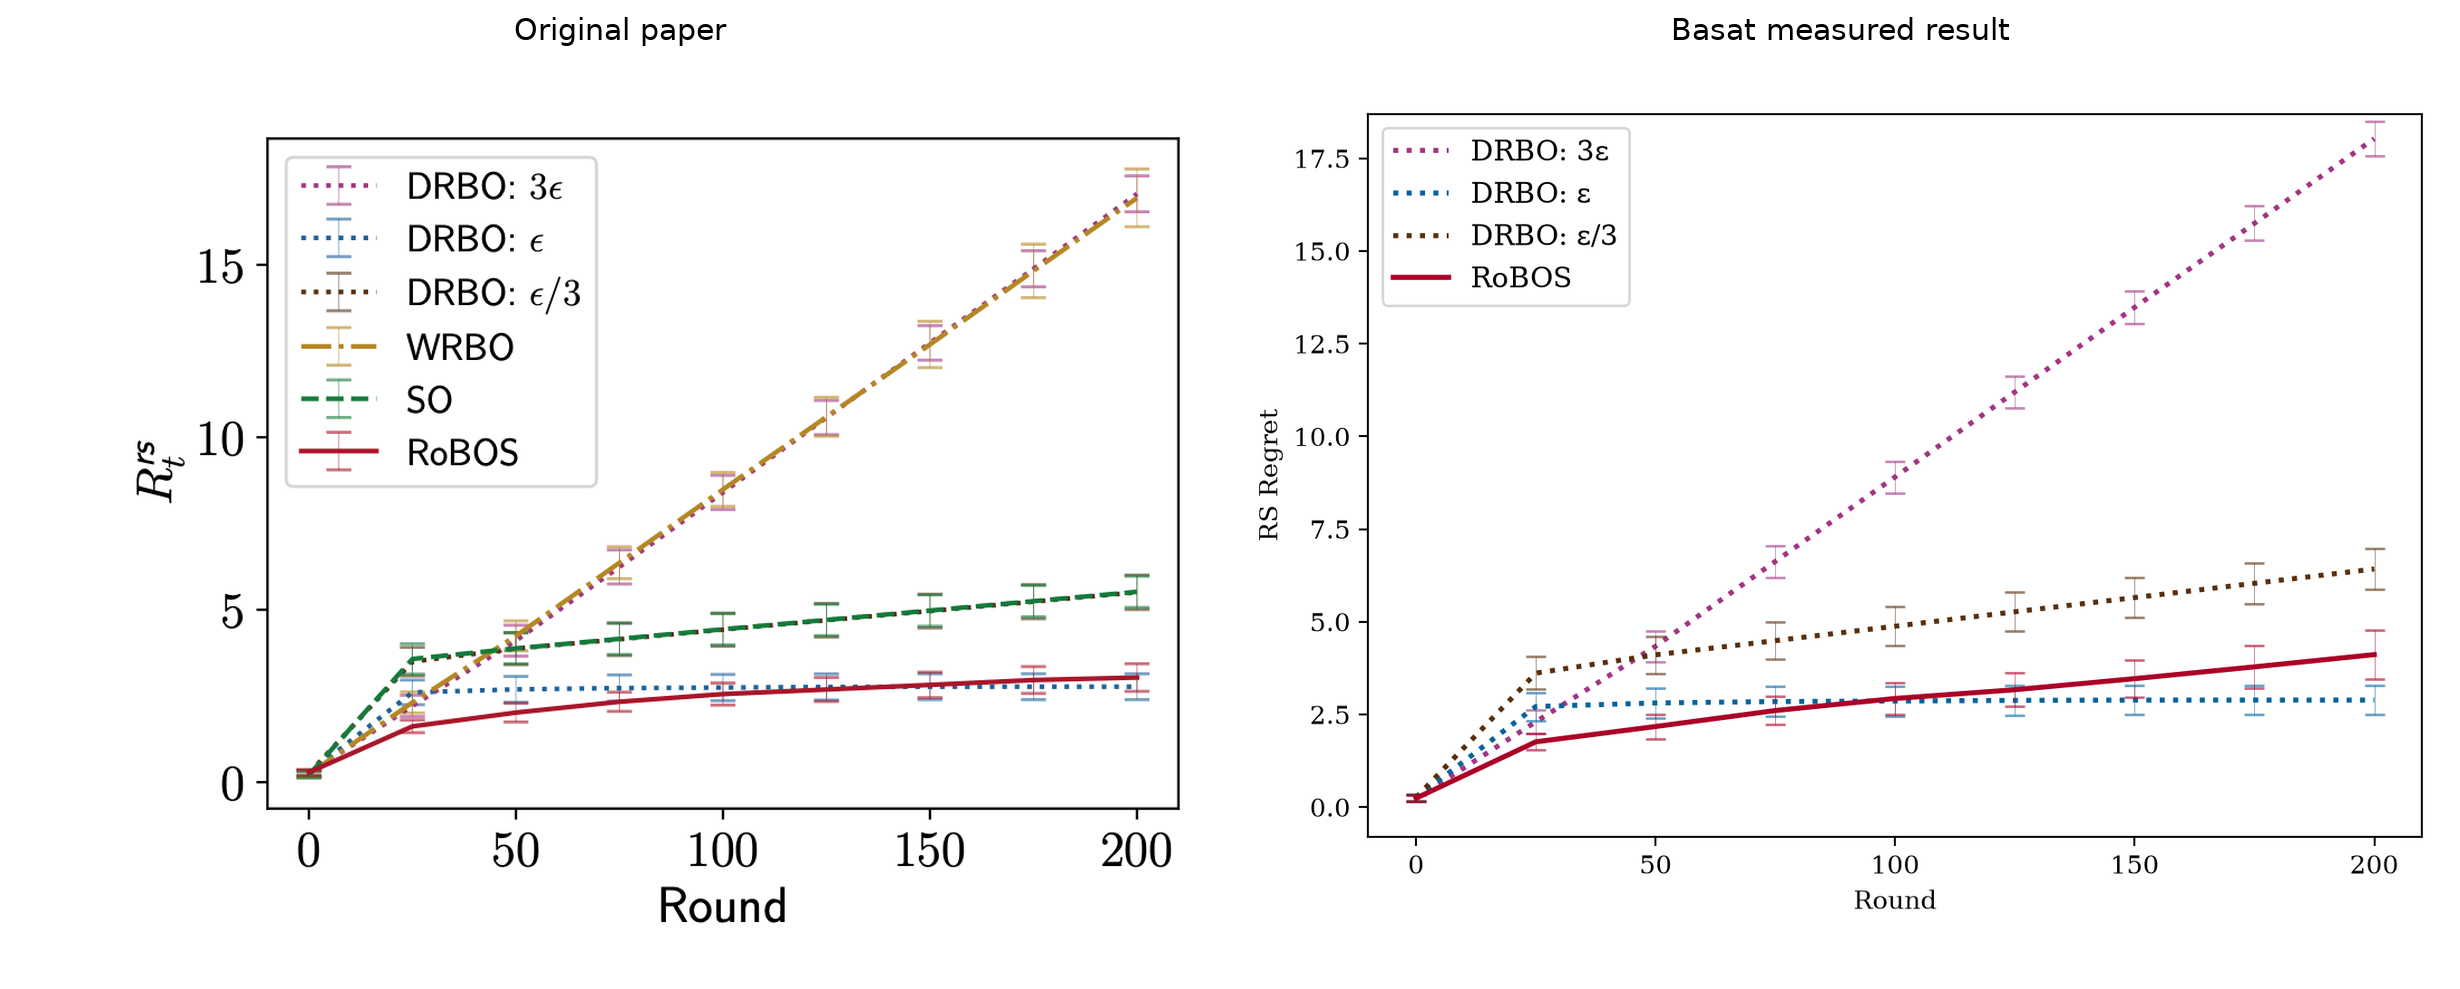

## 5.6 CGP-UCB: MHC-I reconstruction

In [ ]:
import basat

# Reuse the completed measurements read-only; the comparison figure is below.
# For a new campaign, set False and choose a fresh experiment output directory.
READ_COMPLETED_RESULTS = True
_completed_artifacts = {'results/reproducibility/cgp_ucb_mhci2011_author_data_v2/protocol.json': '1dacb4cebfc2429ca20cf3ec67c3adfb0bbd63d57da5b1c4a3d5227e952271a2', 'results/reproducibility/cgp_ucb_mhci2011_author_data_v2/statistics.json': 'b5f7bc89a9e81439c559fa1d33caaf2c509f6fc783e29a52551b2ca66241050f', 'results/reproducibility/cgp_ucb_mhci2011_author_data_v2/calibration_sample.npz': '368f57a271c3adab5b9ef3eb953d5b6d8484a655155dd5e2eead9578bdf648b5', 'results/reproducibility/cgp_ucb_mhci2011_author_data_v2/run_summary.json': 'f83f40d7dbea1071cd86bd2c676cad0af0b282a739a87793102d089c84899308', 'results/reproducibility/cgp_ucb_mhci2011_author_data_v2/run/latest.json': '4dafa1f7527aaf54d31b926ce0c1779d265f9e212aef85e205a674d6c1adac9a', 'results/reproducibility/cgp_ucb_mhci2011_author_data_v2/run/result.json': 'ee0d90a7fbcc52b9070ebb460b4e7350a238d14733be76206e54a616bb9b96dd', 'results/reproducibility/cgp_ucb_mhci2011_author_data_v2/maximum_regret.png': 'eb20db5209d8a28b808d431c6aa7ffb9290b880c2b2bc9c2f852984bcdd8e494'}
_project_store = basat.ArtifactStore(
    basat.find_path('pyproject.toml')[:-len('pyproject.toml')])
_completed_results_match = READ_COMPLETED_RESULTS and all(
    _project_store.exists(path) and _project_store.sha256(path) == checksum
    for path, checksum in _completed_artifacts.items())
if not _completed_results_match:
    OUTPUT_DIRECTORY = basat.join_path(
        basat.find_path("docs"), "..", "results/reproducibility/cgp_ucb_mhci2011_author_data_v2"
    )

    basat.set_seed(2021, threads=1)

    store = basat.ArtifactStore(OUTPUT_DIRECTORY)

    benchmark = basat.MHCBindingBenchmark(source="author_nips11", cache_directory=store.path("data"))

    calibration = benchmark.calibration_sample(seed=2021, size=1000)

    fit = basat.fit_contextual_rbf(
        calibration.observations,
        action_coordinates=calibration.actions,
        context_coordinates=calibration.contexts,
        context_support=benchmark.context_support,
        context_covariance=benchmark.hamming_context_gram,
        initial_action_lengthscale=1.0,
        initial_signal_variance=None,
        initial_noise_variance=0.1,
        action_lengthscale_bounds=(0.001, 1000.0),
        signal_variance_bounds=(0.0001, 100.0),
        noise_variance_bounds=(1e-06, 100.0),
        maxiter=200,
        ftol=1e-10,
        maxls=40,
        cache_directory=store.path("calibration"),
    )

    environment = basat.ContextualEnvironment(
        bounds=benchmark.bounds,
        context_provider=benchmark.context_provider,
        dataset=benchmark.make_dataset(noise_variance=fit.noise_variance, exclude_initial=True),
        previous_data=benchmark.make_initial_data(noise_variance=fit.noise_variance),
        noise_std=0.0,
        add_noise_to_data=False,
        allow_repeated_actions=True,
        data_row_selection="first",
        dtype="float64",
        device="cpu",
        seed=2021,
    )

    algorithm = basat.CGP_UCB(
        bounds=benchmark.bounds,
        maximize=True,
        dtype="float64",
        device="cpu",
        plot=False,
        verbose=False,
        verbose_setting=False,
        verbose_iter_by_iter=False,
        config=basat.CGPUCBConfig(
            action_set=benchmark.actions[1:],
            action_kernel=fit.action_kernel,
            context_kernel=fit.context_kernel,
            kernel_combination="product",
            beta="finite-theory",
            delta=0.1,
            finite_domain_cardinality=4417,
            initial_points=1,
            batch_size=1,
            seed=2021,
            gp_backend="fixed_incremental",
            finite_prediction="marginal",
            marginal_chunk_size=1024,
            recommendation_candidates="latest_context",
            acquisition_optimizer=basat.AcquisitionOptimizerSpec(fit_maxiter=0),
            gp_config=basat.GaussianProcessConfig(
                mean="zero",
                noise_mode="fixed",
                noise_variance=fit.noise_variance,
                standardize_outcomes=False,
                jitter=1e-06,
                max_cholesky_retries=5,
                dtype="float64",
                device="cpu",
            ),
        ),
    )

    protocol = {
        "version": "cgp-mhci2011-author-data-v2",
        "seed": 2021,
        "paper": "Krause and Ong 2011, section 6.1 / Figure 2",
        "unofficial_source_revision": "9a5e6d4ba5fbda223dd8497aaf54e817313fd286",
        "data_provider_revision": "b8ce676ecb778b17dc39d06878523299fd693bc3",
        "data": benchmark.metadata,
        "calibration": fit.parameters,
        "calibration_sample_seed": 2021,
        "calibration_records": 1000,
        "calibration_rows_injected": 0,
        "online_queries": 350,
        "base_observations": 1,
        "online_measured_pairs": 4417,
        "context_covariance_policy": "explicit valid Hamming reconstruction; indefinite author matrix not used or repaired",
        "queries_per_context": 50,
        "allow_repeated_queries": True,
        "beta": "2*log(4417*t**2*pi**2/(6*0.1)); t=global online query, 1..350",
        "feedback": "recorded noiseless reward; calibrated likelihood for conditioning",
        "checkpoint_policy": "periodic",
        "save_every": 10,
        "fidelity": "historical-data reconstruction, not recovered author state",
    }

    if store.exists("protocol.json") and store.read_json("protocol.json") != basat.to_list(protocol):
        raise ValueError("Scientific protocol differs: use a fresh output directory.")

    store.write_json("protocol.json", protocol)

    benchmark.export_artifacts(store.path("benchmark"))

    store.write_arrays(
        "calibration_sample.npz",
        row_indices=calibration.row_indices,
        source_row_indices=calibration.source_row_indices,
        actions=calibration.actions,
        contexts=calibration.contexts,
        observations=calibration.observations,
    )

    if not store.exists("runtime.json"):
        store.write_json("runtime.json", basat.runtime_info(include_source_hash=True))

    experiment = basat.Experiment(
        environment=environment,
        algorithm=algorithm,
        output_directory=store.path("run"),
        resume=True,
        checkpoint_policy="periodic",
        save_every=10,
    )

    result = experiment.run(max_rounds=350, max_evaluations=351, fail_fast=True)

    statistics = basat.contextual_regret_statistics(
        environment,
        context_order=benchmark.context_support,
        queries_per_context=50,
        exclude_initial=True,
    )

    if not statistics.complete or statistics.observed_queries != 350:
        raise RuntimeError("The seven 50-query task blocks have not completed.")

    store.write_json("statistics.json", statistics.as_dict())

    for metric, values, x, xlabel, ylabel, xlim, ylim in (
        (
            "maximum",
            statistics.maximum_simple_regret,
            statistics.aligned_local_queries,
            "Trial t per task",
            "Maximum regret Rₜ",
            (0, 50),
            (0, 5),
        ),
    ):
        basat.plot_panels(
            [
                basat.PlotPanel(
                    {"CGP-UCB": basat.PlotSeries(values, x=x, color="#0000FF")},
                    title="MHC-I historical-data reconstruction",
                    xlabel=xlabel,
                    ylabel=ylabel,
                    xlim=xlim,
                    ylim=ylim,
                    grid=False,
                )
            ],
            figsize=(7, 6),
            save_path=store.path(metric + "_regret.png"),
            show=False,
        )


### Maximum regret

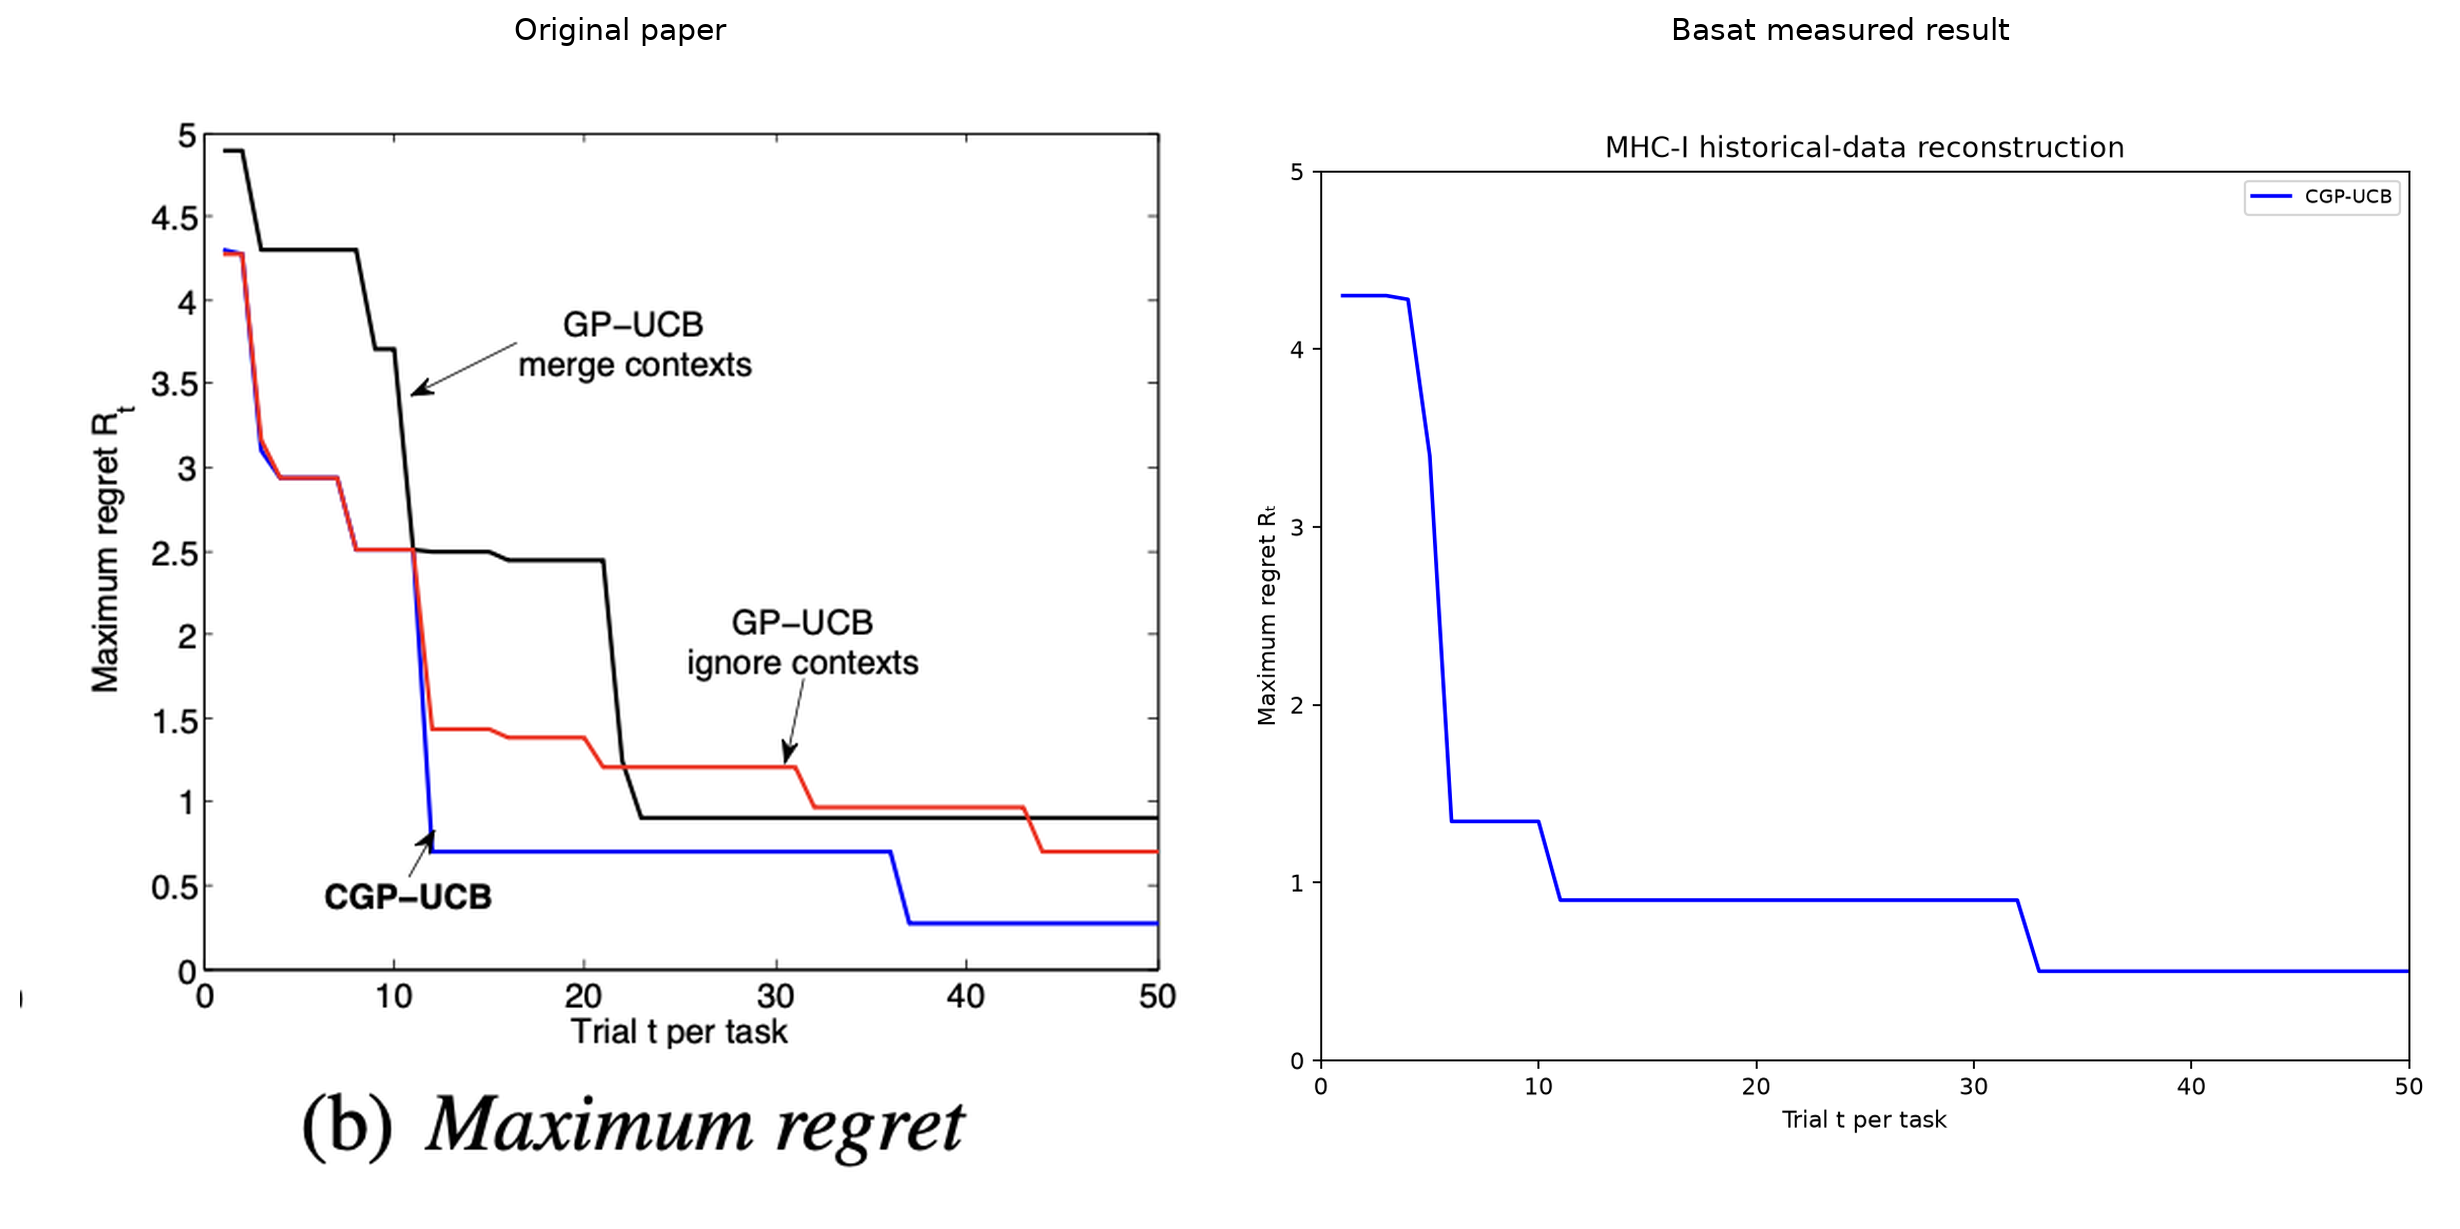